# Formula 1 Podium Prediction: Milestone 1 (CSEN 903 ACL)
Predict whether each driver finishes on the podium (`positionOrder <= 3`) using only information known after qualifying and before the race.

## 1. Setup

### 1.1 Libraries

In [526]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


### 1.2 Data path
Defaults to the Kaggle input folder; set the `F1_DATA_DIR` environment variable to run locally.

In [527]:
import os

DATA_DIR = Path(os.environ.get(
    'F1_DATA_DIR',
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'
))

print("Data directory:", DATA_DIR)

Data directory: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


## 2. Load the Dataset (14 tables)

In [528]:
# Load all 14 CSV files

results = pd.read_csv(
    DATA_DIR / 'results.csv',
    na_values=[r'\N']
)

races = pd.read_csv(
    DATA_DIR / 'races.csv',
    na_values=[r'\N']
)

drivers = pd.read_csv(
    DATA_DIR / 'drivers.csv',
    na_values=[r'\N']
)

constructors = pd.read_csv(
    DATA_DIR / 'constructors.csv',
    na_values=[r'\N']
)

qualifying = pd.read_csv(
    DATA_DIR / 'qualifying.csv',
    na_values=[r'\N']
)

status = pd.read_csv(
    DATA_DIR / 'status.csv',
    na_values=[r'\N']
)

circuits = pd.read_csv(
    DATA_DIR / 'circuits.csv',
    na_values=[r'\N']
)

constructor_results = pd.read_csv(
    DATA_DIR / 'constructor_results.csv',
    na_values=[r'\N']
)

constructor_standings = pd.read_csv(
    DATA_DIR / 'constructor_standings.csv',
    na_values=[r'\N']
)

driver_standings = pd.read_csv(
    DATA_DIR / 'driver_standings.csv',
    na_values=[r'\N']
)

lap_times = pd.read_csv(
    DATA_DIR / 'lap_times.csv',
    na_values=[r'\N']
)

pit_stops = pd.read_csv(
    DATA_DIR / 'pit_stops.csv',
    na_values=[r'\N']
)

sprint_results = pd.read_csv(
    DATA_DIR / 'sprint_results.csv',
    na_values=[r'\N']
)

seasons = pd.read_csv(
    DATA_DIR / 'seasons.csv',
    na_values=[r'\N']  # treat \N as missing
)


tables = {
    'results': results,
    'races': races,
    'drivers': drivers,
    'constructors': constructors,
    'qualifying': qualifying,
    'status': status,
    'circuits': circuits,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'driver_standings': driver_standings,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'sprint_results': sprint_results,
    'seasons': seasons
}

# Check that all tables are loaded
print("Number of tables:", len(tables))

for name, df in tables.items():
    print(name, ":", df.shape)


Number of tables: 14
results : (26759, 18)
races : (1125, 18)
drivers : (861, 9)
constructors : (212, 5)
qualifying : (10494, 9)
status : (139, 2)
circuits : (77, 9)
constructor_results : (12625, 5)
constructor_standings : (13391, 7)
driver_standings : (34863, 7)
lap_times : (589081, 6)
pit_stops : (11371, 7)
sprint_results : (360, 16)
seasons : (75, 2)


## 3. Raw Data Audit
Read-only checks on the raw tables; the findings here motivate the cleaning steps in Section 4.

### 3.1 results.csv: overview

In [529]:
results.head() # Display the first five rows
results.info() # Check data types, non-null counts and columns
results.describe() # Statistical summary
results.isnull().sum() # Count missing values per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

### 3.2 Primary key checks

In [530]:
primary_keys = {
    'results': ['resultId'],
    'races': ['raceId'],
    'drivers': ['driverId'],
    'constructors': ['constructorId'],
    'qualifying': ['qualifyId'],
    'status': ['statusId'],
    'circuits': ['circuitId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId'],
    'seasons': ['year']
}


In [531]:
for table_name, key_columns in primary_keys.items():

    df = tables[table_name]

    # Count rows with at least one missing key component
    missing_keys = df[key_columns].isnull().any(axis=1).sum()

    # Count repeated keys
    duplicate_keys = df.duplicated(
        subset=key_columns
    ).sum()

    print("Table:", table_name)
    print("Primary key:", key_columns)
    print("Missing key rows:", missing_keys)
    print("Duplicate keys:", duplicate_keys)
    print("-" * 45)


Table: results
Primary key: ['resultId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: races
Primary key: ['raceId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: drivers
Primary key: ['driverId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: constructors
Primary key: ['constructorId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: qualifying
Primary key: ['qualifyId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: status
Primary key: ['statusId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: circuits
Primary key: ['circuitId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: constructor_results
Primary key: ['constructorResultsId']
Missing key rows: 0
Duplicate keys: 0
-----------

### 3.3 Foreign key checks

In [532]:
foreign_keys = {
    'results': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId'),
        ('statusId', 'status', 'statusId')
    ],

    'races': [
        ('year', 'seasons', 'year'),
        ('circuitId', 'circuits', 'circuitId')
    ],

    'qualifying': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'constructor_results': [
        ('raceId', 'races', 'raceId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'constructor_standings': [
        ('raceId', 'races', 'raceId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'driver_standings': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'lap_times': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'pit_stops': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'sprint_results': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId'),
        ('statusId', 'status', 'statusId')
    ]
}


In [533]:
foreign_key_results = []

for table_name, relationships in foreign_keys.items():

    df = tables[table_name]

    for foreign_key, ref_table, primary_key in relationships:

        # Count missing foreign keys
        missing_count = df[foreign_key].isnull().sum()

        # Check whether IDs exist in the referenced table
        invalid = (
            ~df[foreign_key].isin(tables[ref_table][primary_key])
        ) & df[foreign_key].notna()

        invalid_count = invalid.sum()

        foreign_key_results.append({
            'Table': table_name,
            'Foreign Key': foreign_key,
            'References': ref_table,
            'Missing Values': missing_count,
            'Invalid References': invalid_count
        })

fk_audit = pd.DataFrame(foreign_key_results)

display(fk_audit)


,Table,Foreign Key,References,Missing Values,Invalid References
0,results,raceId,races,0,0
1,results,driverId,drivers,0,0
2,results,constructorId,constructors,0,0
3,results,statusId,status,0,0
4,races,year,seasons,0,0
5,races,circuitId,circuits,0,0
6,qualifying,raceId,races,0,0
7,qualifying,driverId,drivers,0,0
8,qualifying,constructorId,constructors,0,0
9,constructor_results,raceId,races,0,0


### 3.4 Missing values per table

In [534]:
for name, df in tables.items():

    print("\nTable:", name)

    missing = df.isnull().sum()

    print(
        missing[missing > 0]
        .sort_values(ascending=False)
    )

    print("-" * 45)



Table: results
milliseconds       19079
time               19079
fastestLapTime     18507
fastestLap         18507
fastestLapSpeed    18507
rank               18249
position           10953
number                 6
dtype: int64
---------------------------------------------

Table: races
sprint_time    1110
sprint_date    1107
fp3_time       1072
quali_time     1057
fp2_time       1057
fp1_time       1057
fp3_date       1053
fp2_date       1035
fp1_date       1035
quali_date     1035
time            731
dtype: int64
---------------------------------------------

Table: drivers
number    802
code      757
dtype: int64
---------------------------------------------

Table: constructors
Series([], dtype: int64)
---------------------------------------------

Table: qualifying
q3    6865
q2    4647
q1     156
dtype: int64
---------------------------------------------

Table: status
Series([], dtype: int64)
---------------------------------------------

Table: circuits
Series([], dtype: int64

### 3.5 Duplicate (raceId, driverId) rows in results

In [535]:
# Check completely identical rows
print("Exact duplicates:", results.duplicated().sum())

# Check drivers appearing more than once in the same race
print(
    "Duplicate driver-race combinations:",
    results.duplicated(
        subset=['raceId', 'driverId']
    ).sum()
)

Exact duplicates: 0
Duplicate driver-race combinations: 91


In [536]:
duplicates = results[
    results.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].copy()

# Display the important columns
display(
    duplicates[
        ['resultId', 'raceId', 'driverId',
         'constructorId', 'grid', 'positionOrder',
         'points', 'statusId']
    ].sort_values(['raceId', 'driverId'])
)


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,statusId
13188,13189,540,229,54,0,26,0.0,81
13191,13192,540,229,57,0,29,0.0,97
17362,17363,717,373,172,1,7,0.0,60
24298,24304,717,373,172,1,12,0.0,98
17740,17741,733,465,172,0,22,0.0,54
...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,15,6,0.0,18
20163,20164,839,579,51,1,15,1.0,6
20183,20184,839,579,51,7,13,0.0,5
20165,20166,839,647,6,2,17,0.0,5


In [537]:
# Add the race year
duplicates_details = pd.merge(
    duplicates,
    races[['raceId', 'year', 'name']],
    on='raceId',
    how='left'
)

# Add driver names
duplicates_details = pd.merge(
    duplicates_details,
    drivers[['driverId', 'forename', 'surname']],
    on='driverId',
    how='left'
)

# Add constructor names to duplicated records
duplicates_details = pd.merge(
    duplicates_details,
    constructors[['constructorId', 'name']],
    on='constructorId',
    how='left',
    suffixes=('', '_constructor')
)

# Display the results
display(
    duplicates_details[
        ['year', 'name', 'forename', 'surname',
         'raceId', 'driverId', 'constructorId', 'name_constructor', 'resultId',
         'grid', 'positionOrder', 'points']
    ].sort_values(['year', 'raceId', 'driverId'])
    .head(30)
)

# Count duplicate groups with multiple constructors
constructor_counts = (
    duplicates.groupby(['raceId', 'driverId'])
    ['constructorId'].nunique()
)

print(
    "Groups with different constructors:",
    (constructor_counts > 1).sum()
)

print(
    "Groups with the same constructor:",
    (constructor_counts == 1).sum()
)

# Check for multiple non-zero grid positions
grid_counts = (
    duplicates[duplicates['grid'] > 0]
    .groupby(['raceId', 'driverId'])
    .size()
)

print(
    "Groups with multiple positive grid positions:",
    (grid_counts > 1).sum()
)

# Check duplicate groups with conflicting podium outcomes
podium_counts = (
    duplicates.assign(
        podium=(duplicates['positionOrder'] <= 3).astype(int)
    )
    .groupby(['raceId', 'driverId'])
    ['podium'].nunique()
)

print(
    "Groups with conflicting podium labels:",
    (podium_counts > 1).sum()
)



,year,name,forename,surname,raceId,driverId,constructorId,name_constructor,resultId,grid,positionOrder,points
84,1950,Indianapolis 500,Tony,Bettenhausen,835,529,150,Deidt,20097,8,31,0.0
88,1950,Indianapolis 500,Tony,Bettenhausen,835,529,113,Kurtis Kraft,20179,9,5,1.0
85,1950,French Grand Prix,Louis,Rosier,838,627,154,Talbot-Lago,20143,6,12,0.0
89,1950,French Grand Prix,Louis,Rosier,838,627,154,Talbot-Lago,20182,15,6,0.0
86,1950,Italian Grand Prix,Juan,Fangio,839,579,51,Alfa Romeo,20164,1,15,1.0
91,1950,Italian Grand Prix,Juan,Fangio,839,579,51,Alfa Romeo,20184,7,13,0.0
87,1950,Italian Grand Prix,Alberto,Ascari,839,647,6,Ferrari,20166,2,17,0.0
90,1950,Italian Grand Prix,Alberto,Ascari,839,647,6,Ferrari,20183,6,2,3.0
81,1951,French Grand Prix,Juan,Fangio,828,579,51,Alfa Romeo,19928,1,11,0.0
92,1951,French Grand Prix,Juan,Fangio,828,579,51,Alfa Romeo,20186,7,1,5.0


Groups with different constructors: 16
Groups with the same constructor: 69
Groups with multiple positive grid positions: 82
Groups with conflicting podium labels: 21


### 3.6 Grid position values and grid = 0

In [538]:
# Check minimum and maximum grid positions
print("Minimum grid position:", results['grid'].min())
print("Maximum grid position:", results['grid'].max())

# Count unusual grid values
print("Grid = 0:", (results['grid'] == 0).sum())
print("Negative grid values:", (results['grid'] < 0).sum())

# Display grid distribution
print(results['grid'].value_counts().sort_index())



# Select records where grid is zero
grid_zero = results[results['grid'] == 0].copy()

# Add race status descriptions
grid_zero = pd.merge(
    grid_zero,
    status,
    on='statusId',
    how='left',
    validate='many_to_one'
)

# Display the most common statuses
print(grid_zero['status'].value_counts().head(20))


Minimum grid position: 0
Maximum grid position: 34
Grid = 0: 1638
Negative grid values: 0
grid
0     1638
1     1136
2     1125
3     1130
4     1132
5     1132
6     1125
7     1135
8     1129
9     1132
10    1130
11    1132
12    1127
13    1125
14    1120
15    1113
16    1100
17    1089
18    1050
19    1031
20     975
21     697
22     656
23     453
24     429
25     301
26     248
27      46
28      30
29      25
30      19
31      18
32      17
33      13
34       1
Name: count, dtype: int64
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Safety concerns          2
107% Rule                2
Suspension               2
P

In [539]:
# Display all status values for grid-zero records
grid_zero_status = grid_zero['status'].value_counts()

display(grid_zero_status)


status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Safety concerns          2
107% Rule                2
Suspension               2
Power Unit               2
Fuel system              2
Underweight              1
Fatal accident           1
Battery                  1
Transmission             1
Gearbox                  1
Collision                1
Undertray                1
Hydraulics               1
Name: count, dtype: int64

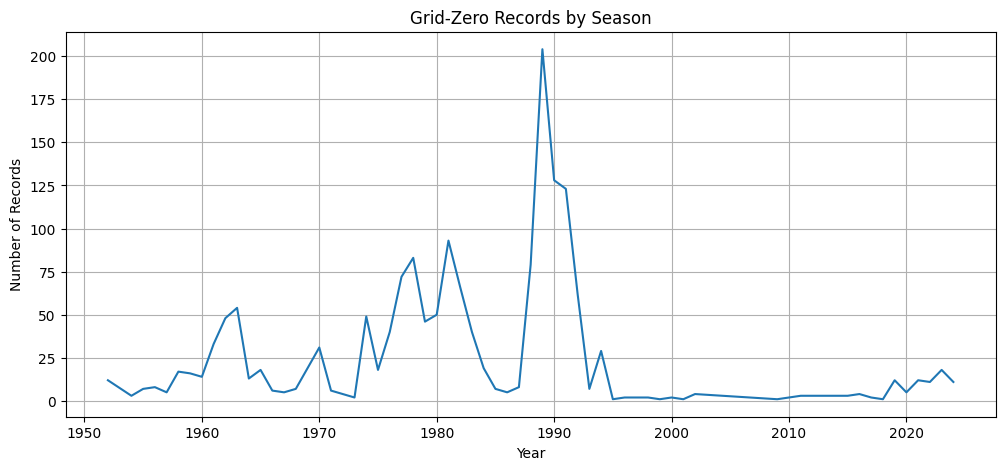

In [540]:
# Add year to grid-zero records
grid_zero_years = pd.merge(
    grid_zero,
    races[['raceId', 'year']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

# Calculate number of grid-zero records per year
grid_zero_counts = (
    grid_zero_years['year']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

grid_zero_counts.plot()

plt.title('Grid-Zero Records by Season')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.grid(True)
plt.show()


#### 3.6.1 Investigating grid = 0 records

In [541]:
#Inspect the grid-zero drivers who finished
grid_zero_finished = grid_zero[
    grid_zero['status'].str.match(
        r'^(Finished|\+\d+ Laps?)$',
        na=False
    )
]

display(
    grid_zero_finished[
        ['raceId', 'driverId', 'grid',
         'positionOrder', 'status']
    ].head(20)
)

print(
    "Grid-zero records classified as finished/lapped:",
    len(grid_zero_finished)
)


,raceId,driverId,grid,positionOrder,status
1558,931,832,0,10,Finished
1569,1012,848,0,10,+1 Lap
1570,1013,8,0,10,+1 Lap
1571,1013,9,0,16,+2 Laps
1573,1014,807,0,13,Finished
1574,1016,825,0,17,+2 Laps
1575,1018,847,0,18,+2 Laps
1576,1022,9,0,17,+1 Lap
1577,1023,8,0,15,+1 Lap
1578,1025,848,0,5,Finished


Grid-zero records classified as finished/lapped: 56


In [542]:
# Exclude the three dominant non-starting status categories
other_grid_zero = grid_zero[
    ~grid_zero['status'].isin([
        'Did not qualify',
        'Did not prequalify',
        'Withdrew'
    ])
].copy()

print("Other grid-zero records:", len(other_grid_zero))

# Inspect completed laps and race classifications
display(
    other_grid_zero[
        ['raceId', 'driverId', 'grid', 'laps',
         'positionOrder', 'status']
    ].sort_values('laps', ascending=False).head(30)
)

print("Records with laps > 0:",
      (other_grid_zero['laps'] > 0).sum())

print("Records with laps = 0:",
      (other_grid_zero['laps'] == 0).sum())


Other grid-zero records: 130


,raceId,driverId,grid,laps,positionOrder,status
1558,931,832,0,78,10,Finished
1616,1111,825,0,72,16,Finished
1593,1064,815,0,71,8,+1 Lap
1632,1135,825,0,71,18,+1 Lap
1602,1084,822,0,70,11,+1 Lap
1635,1140,839,0,70,13,+1 Lap
1627,1129,822,0,70,13,Finished
1594,1064,849,0,70,16,+2 Laps
1613,1107,856,0,70,17,+1 Lap
1597,1071,8,0,70,12,+1 Lap


Records with laps > 0: 72
Records with laps = 0: 58


### 3.7 Qualifying coverage by season

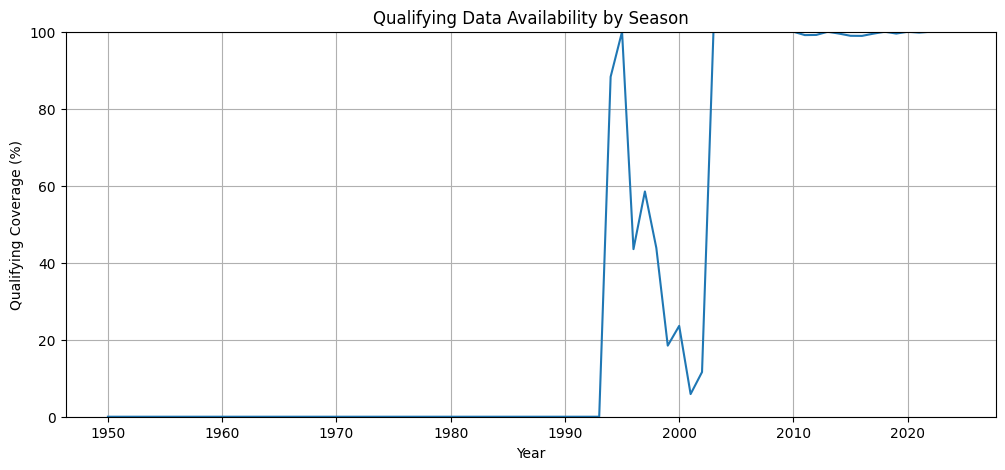

In [543]:
# Get race year for each result
results_years = pd.merge(
    results,
    races[['raceId', 'year']],
    on='raceId',
    how='left'
)

# Get unique driver-race combinations with qualifying data
qualifying_pairs = qualifying[
    ['raceId', 'driverId']
].drop_duplicates()

qualifying_pairs['has_qualifying'] = 1

# Match qualifying availability to result records
qualifying_coverage = pd.merge(
    results_years,
    qualifying_pairs,
    on=['raceId', 'driverId'],
    how='left'
)

# Missing match means no qualifying record
qualifying_coverage['has_qualifying'] = (
    qualifying_coverage['has_qualifying'].fillna(0)
)

# Percentage with qualifying data each year
coverage_by_year = (
    qualifying_coverage.groupby('year')['has_qualifying']
    .mean() * 100
)

plt.figure(figsize=(12, 5))
coverage_by_year.plot()

plt.title('Qualifying Data Availability by Season')
plt.xlabel('Year')
plt.ylabel('Qualifying Coverage (%)')
plt.ylim(0, 100)
plt.grid(True)
plt.show()


> Treat qualifying position as an optional additional feature and compare whether it improves model performance.

### 3.8 Data types and time formats
Conversions are first tried on temporary `*_check` copies to measure parse failures before cleaning.

In [544]:
# Inspect date and time-related columns

print("Races:")
print(races[['date', 'time']].dtypes)

print("\nQualifying:")
print(qualifying[['q1', 'q2', 'q3']].dtypes)

print("\nLap times:")
print(lap_times[['time', 'milliseconds']].dtypes)

print("\nPit stops:")
print(pit_stops[['time', 'duration', 'milliseconds']].dtypes)



display(races[['date', 'time']].head())

display(qualifying[['q1', 'q2', 'q3']].head())

display(lap_times[['time', 'milliseconds']].head())

display(pit_stops[['time', 'duration', 'milliseconds']].head())


Races:
date    object
time    object
dtype: object

Qualifying:
q1    object
q2    object
q3    object
dtype: object

Lap times:
time            object
milliseconds     int64
dtype: object

Pit stops:
time            object
duration        object
milliseconds     int64
dtype: object


,date,time
0,2009-03-29,06:00:00
1,2009-04-05,09:00:00
2,2009-04-19,07:00:00
3,2009-04-26,12:00:00
4,2009-05-10,12:00:00


,q1,q2,q3
0,1:26.572,1:25.187,1:26.714
1,1:26.103,1:25.315,1:26.869
2,1:25.664,1:25.452,1:27.079
3,1:25.994,1:25.691,1:27.178
4,1:25.960,1:25.518,1:27.236


,time,milliseconds
0,1:38.109,98109
1,1:33.006,93006
2,1:32.713,92713
3,1:32.803,92803
4,1:32.342,92342


,time,duration,milliseconds
0,17:05:23,26.898,26898
1,17:05:52,25.021,25021
2,17:20:48,23.426,23426
3,17:22:34,23.251,23251
4,17:24:10,23.842,23842


In [545]:
# Convert dates temporarily to check validity
race_dates_check = pd.to_datetime(
    races['date'],
    errors='coerce'
)

print("Original missing dates:", races['date'].isnull().sum())

print("Invalid dates after conversion:", race_dates_check.isnull().sum())

print("Earliest date:", race_dates_check.min())
print("Latest date:", race_dates_check.max())


Original missing dates: 0
Invalid dates after conversion: 0
Earliest date: 1950-05-13 00:00:00
Latest date: 2024-12-08 00:00:00


In [546]:
# Temporary copy for auditing
qualifying_check = qualifying.copy()

for column in ['q1', 'q2', 'q3']:

    # Convert qualifying lap time to timedelta
    converted = pd.to_timedelta(
        '00:' + qualifying_check[column].dropna().astype(str),
        errors='coerce'
    )

    # Store durations in seconds
    qualifying_check[column + '_seconds'] = np.nan

    qualifying_check.loc[
        converted.index,
        column + '_seconds'
    ] = converted.dt.total_seconds()

    print(column)
    print("Original non-missing:", qualifying[column].notna().sum())
    print("Successfully converted:", converted.notna().sum())
    print("Invalid formats:", converted.isna().sum())
    print("-" * 40)

display(
    qualifying_check[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)



# Work on a temporary copy
lap_times_check = lap_times.copy()

# Convert milliseconds to seconds
lap_times_check['time_seconds'] = (
    lap_times_check['milliseconds'] / 1000
)

# Display original and converted values
display(
    lap_times_check[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)



# Parse the original lap-time strings
parsed_lap_times = pd.to_timedelta(
    '00:' + lap_times['time'].astype(str),
    errors='coerce'
).dt.total_seconds()

# Compare parsed times with milliseconds
differences = (
    parsed_lap_times -
    lap_times_check['time_seconds']
).abs()

print("Unparseable lap times:", parsed_lap_times.isnull().sum())

print(
    "Time mismatches:",
    (differences > 0.001).sum()
)



pit_stops_check = pit_stops.copy()

# Convert duration strings to numeric seconds
pit_stops_check['duration_seconds'] = pd.to_numeric(
    pit_stops_check['duration'],
    errors='coerce'
)

# Convert milliseconds to seconds
pit_stops_check['milliseconds_seconds'] = (
    pit_stops_check['milliseconds'] / 1000
)

# Compare the two duration representations
differences = (
    pit_stops_check['duration_seconds'] -
    pit_stops_check['milliseconds_seconds']
).abs()

print(
    "Invalid duration strings:",
    pit_stops_check['duration_seconds'].isnull().sum()
)

print(
    "Duration mismatches:",
    (differences > 0.001).sum()
)

display(
    pit_stops_check[
        ['duration', 'milliseconds',
         'duration_seconds', 'milliseconds_seconds']
    ].head()
)


q1
Original non-missing: 10338
Successfully converted: 10338
Invalid formats: 0
----------------------------------------
q2
Original non-missing: 5847
Successfully converted: 5847
Invalid formats: 0
----------------------------------------
q3
Original non-missing: 3629
Successfully converted: 3629
Invalid formats: 0
----------------------------------------


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Unparseable lap times: 43
Time mismatches: 0
Invalid duration strings: 517
Duration mismatches: 0


,duration,milliseconds,duration_seconds,milliseconds_seconds
0,26.898,26898,26.898,26.898
1,25.021,25021,25.021,25.021
2,23.426,23426,23.426,23.426
3,23.251,23251,23.251,23.251
4,23.842,23842,23.842,23.842


In [547]:
invalid_pit_durations = pit_stops[
    pit_stops_check['duration_seconds'].isna() &
    pit_stops['duration'].notna()
]

print("Unparseable pit-stop durations:", len(invalid_pit_durations))

display(
    invalid_pit_durations[
        ['raceId', 'driverId', 'stop',
         'duration', 'milliseconds']
    ].head(30)
)

print(
    invalid_pit_durations['duration']
    .value_counts()
    .head(20)
)


Unparseable pit-stop durations: 517


,raceId,driverId,stop,duration,milliseconds
751,853,817,1,16:44.718,1004718
2419,881,814,2,2:03.124,123124
2420,881,16,2,1:29.401,89401
2421,881,18,3,1:44.833,104833
2422,884,16,1,1:14.026,74026
2533,888,17,1,2:42.042,162042
2713,893,154,3,1:13.009,73009
2802,894,16,3,1:11.445,71445
3089,901,817,3,1:49.329,109329
3159,903,13,1,1:18.277,78277


duration
24:16.349    2
2:03.124     1
6:29.973     1
6:32.517     1
6:33.601     1
6:36.504     1
6:36.837     1
6:41.057     1
6:41.749     1
6:42.478     1
6:40.857     1
6:40.463     1
6:42.029     1
6:46.256     1
6:47.553     1
6:47.673     1
6:27.399     1
50:11.861    1
51:05.174    1
51:09.017    1
Name: count, dtype: int64


In [548]:
# Lap-time milliseconds
print("Lap-time missing milliseconds:",
      lap_times['milliseconds'].isna().sum())

print("Lap-time non-positive milliseconds:",
      (lap_times['milliseconds'] <= 0).sum())

# Pit-stop milliseconds
print("Pit-stop missing milliseconds:",
      pit_stops['milliseconds'].isna().sum())

print("Pit-stop non-positive milliseconds:",
      (pit_stops['milliseconds'] <= 0).sum())

# Inspect the largest durations
display(
    lap_times.nlargest(10, 'milliseconds')[
        ['raceId', 'driverId', 'lap', 'time', 'milliseconds']
    ]
)

display(
    pit_stops.nlargest(10, 'milliseconds')[
        ['raceId', 'driverId', 'stop', 'duration', 'milliseconds']
    ]
)


Lap-time missing milliseconds: 0
Lap-time non-positive milliseconds: 0
Pit-stop missing milliseconds: 0
Pit-stop non-positive milliseconds: 0


,raceId,driverId,lap,time,milliseconds
8372,847,2,25,2:05:07.547,7507547
8020,847,13,25,2:05:06.656,7506656
8426,847,808,25,2:05:06.243,7506243
8621,847,155,25,2:05:06.095,7506095
7916,847,20,25,2:05:05.152,7505152
8089,847,17,25,2:05:05.034,7505034
7985,847,4,25,2:05:04.226,7504226
8495,847,814,25,2:05:03.980,7503980
8876,847,37,25,2:05:03.795,7503795
8234,847,18,25,2:05:03.775,7503775


,raceId,driverId,stop,duration,milliseconds
9156,1083,840,1,51:09.017,3069017
9155,1083,20,1,51:07.301,3067301
9157,1083,854,1,51:05.174,3065174
9154,1083,825,1,51:03.613,3063613
9152,1083,817,1,51:03.314,3063314
9151,1083,822,1,50:55.732,3055732
9147,1083,4,1,50:55.700,3055700
9150,1083,849,1,50:51.904,3051904
9153,1083,842,1,50:48.950,3048950
9145,1083,1,1,50:46.888,3046888


## 4. Data Cleaning
Raw tables are never modified; every cleaned table is a copy with the `_clean` suffix.

### 4.1 Create working copies

In [549]:
# Preserve original datasets: all cleaning happens on these copies
results_clean               = results.copy()
races_clean                 = races.copy()
drivers_clean               = drivers.copy()
constructors_clean          = constructors.copy()
qualifying_clean            = qualifying.copy()
status_clean                = status.copy()
circuits_clean              = circuits.copy()
constructor_results_clean   = constructor_results.copy()
constructor_standings_clean = constructor_standings.copy()
driver_standings_clean      = driver_standings.copy()
lap_times_clean             = lap_times.copy()
pit_stops_clean             = pit_stops.copy()
sprint_results_clean        = sprint_results.copy()
seasons_clean               = seasons.copy()

### 4.2 races_clean: race date

In [550]:
# Convert race dates to datetime
races_clean['date'] = pd.to_datetime(
    races_clean['date'],
    errors='coerce'
)

print(races_clean['date'].dtype)
print("Missing dates:", races_clean['date'].isnull().sum())


datetime64[ns]
Missing dates: 0


### 4.3 qualifying_clean: Q1–Q3 times to seconds

In [551]:
# Convert qualifying times into seconds
for column in ['q1', 'q2', 'q3']:

    converted = pd.to_timedelta(
        '00:' + qualifying_clean[column].dropna().astype(str),
        errors='coerce'
    )

    qualifying_clean[column + '_seconds'] = (
        converted.dt.total_seconds()
    )

display(
    qualifying_clean[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


### 4.4 lap_times_clean and pit_stops_clean: durations from milliseconds

In [552]:
# Convert milliseconds to seconds
lap_times_clean['time_seconds'] = (
    lap_times_clean['milliseconds'] / 1000
)

display(
    lap_times_clean[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)

print(
    "Missing converted lap times:",
    lap_times_clean['time_seconds'].isnull().sum()
)


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Missing converted lap times: 0


In [553]:
# Convert pit-stop milliseconds to seconds
pit_stops_clean['duration_seconds'] = (
    pit_stops_clean['milliseconds'] / 1000
)

display(
    pit_stops_clean[
        ['duration', 'milliseconds', 'duration_seconds']
    ].head()
)

print(
    "Missing converted durations:",
    pit_stops_clean['duration_seconds'].isnull().sum()
)


,duration,milliseconds,duration_seconds
0,26.898,26898,26.898
1,25.021,25021,25.021
2,23.426,23426,23.426
3,23.251,23251,23.251
4,23.842,23842,23.842


Missing converted durations: 0


### 4.5 Validate conversions and row counts

In [554]:
# 1. Verify race dates
print("Race dates:")
print("Data type:", races_clean['date'].dtype)
print("Missing:", races_clean['date'].isna().sum())

# 2. Verify qualifying conversions
print("\nQualifying times:")

for column in ['q1', 'q2', 'q3']:
    failed = (
        qualifying_clean[column].notna() &
        qualifying_clean[column + '_seconds'].isna()
    ).sum()

    print(column, "- unexpected failures:", failed)

# 3. Verify lap and pit-stop durations
print("\nLap times:")
print(
    "Invalid durations:",
    (
        lap_times_clean['time_seconds'].isna() |
        (lap_times_clean['time_seconds'] <= 0)
    ).sum()
)

print("\nPit stops:")
print(
    "Invalid durations:",
    (
        pit_stops_clean['duration_seconds'].isna() |
        (pit_stops_clean['duration_seconds'] <= 0)
    ).sum()
)

# 4. Verify row counts have not changed
print("\nRow-count verification:")

for name, original, cleaned in [
    ('races', races, races_clean),
    ('qualifying', qualifying, qualifying_clean),
    ('lap_times', lap_times, lap_times_clean),
    ('pit_stops', pit_stops, pit_stops_clean)
]:
    print(
        name,
        "- original:", len(original),
        "- cleaned:", len(cleaned)
    )
    assert len(original) == len(cleaned)


Race dates:
Data type: datetime64[ns]
Missing: 0

Qualifying times:
q1 - unexpected failures: 0
q2 - unexpected failures: 0
q3 - unexpected failures: 0

Lap times:
Invalid durations: 0

Pit stops:
Invalid durations: 0

Row-count verification:
races - original: 1125 - cleaned: 1125
qualifying - original: 10494 - cleaned: 10494
lap_times - original: 589081 - cleaned: 589081
pit_stops - original: 11371 - cleaned: 11371


### 4.6 races_clean: structure and duplicate checks

In [555]:

# Inspect the cleaned races table
print("Dataset shape:", races_clean.shape)

print("\nColumn names:")
print(races_clean.columns.tolist())

print("\nData types:")
print(races_clean.dtypes)

print("\nFirst five rows:")
display(races_clean.head())

print("\nSummary statistics:")
display(races_clean.describe(include='all'))


Dataset shape: (1125, 18)

Column names:
['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']

Data types:
raceId                  int64
year                    int64
round                   int64
circuitId               int64
name                   object
date           datetime64[ns]
time                   object
url                    object
fp1_date               object
fp1_time               object
fp2_date               object
fp2_time               object
fp3_date               object
fp3_time               object
quali_date             object
quali_time             object
sprint_date            object
sprint_time            object
dtype: object

First five rows:


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Summary statistics:


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
count,1125.000000,1125.000000,1125.000000,1125.000000,1125,1125,394,1125,90,68,90,68,72,53,90,68,18,15
unique,NaN,NaN,NaN,NaN,54,NaN,34,1125,90,20,90,19,72,18,90,15,18,12
top,NaN,NaN,NaN,NaN,Italian Grand Prix,NaN,12:00:00,https://en.wikipedia.org/wiki/2024_Abu_Dhabi_G...,2021-04-16,11:30:00,2021-04-16,15:00:00,2021-04-17,10:30:00,2021-04-17,14:00:00,2021-07-17,14:30:00
freq,NaN,NaN,NaN,NaN,75,NaN,113,1,1,18,1,22,1,14,1,24,1,4
mean,565.710222,1992.703111,8.579556,23.889778,NaN,1993-03-25 13:23:50.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,1950.000000,1.000000,1.000000,NaN,1950-05-13 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,282.000000,1977.000000,4.000000,9.000000,NaN,1977-01-23 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,563.000000,1994.000000,8.000000,18.000000,NaN,1994-11-06 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,845.000000,2011.000000,13.000000,34.000000,NaN,2011-05-22 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,1144.000000,2024.000000,24.000000,80.000000,NaN,2024-12-08 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [556]:

print("Exact duplicate rows:",
      races_clean.duplicated().sum())

print("Missing race IDs:",
      races_clean['raceId'].isna().sum())

print("Duplicate race IDs:",
      races_clean['raceId'].duplicated().sum())

print("Duplicate year-round combinations:",
      races_clean.duplicated(
          subset=['year', 'round']
      ).sum())

# Show repeated year-round combinations, if any
duplicate_races = races_clean[
    races_clean.duplicated(
        subset=['year', 'round'],
        keep=False
    )
]

display(
    duplicate_races[
        ['raceId', 'year', 'round', 'name', 'date']
    ].sort_values(['year', 'round'])
)


Exact duplicate rows: 0
Missing race IDs: 0
Duplicate race IDs: 0
Duplicate year-round combinations: 0


,raceId,year,round,name,date


#### 4.6.1 Session dates and times

In [557]:

# Convert optional session dates to datetime
date_columns = [
    'fp1_date',
    'fp2_date',
    'fp3_date',
    'quali_date',
    'sprint_date'
]

# Record original non-missing counts
original_date_counts = races_clean[date_columns].notna().sum()

for col in date_columns:
    races_clean[col] = pd.to_datetime(
        races_clean[col],
        errors='coerce'
    )

# Check whether valid values were lost
converted_date_counts = races_clean[date_columns].notna().sum()

date_validation = pd.DataFrame({
    'Before': original_date_counts,
    'After': converted_date_counts,
    'Failed Conversions': (
        original_date_counts - converted_date_counts
    )
})

display(date_validation)
print(races_clean[date_columns].dtypes)


,Before,After,Failed Conversions
fp1_date,90,90,0
fp2_date,90,90,0
fp3_date,72,72,0
quali_date,90,90,0
sprint_date,18,18,0


fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object


In [558]:

# Convert clock-time columns
time_columns = [
    'time',
    'fp1_time',
    'fp2_time',
    'fp3_time',
    'quali_time',
    'sprint_time'
]

original_time_counts = races_clean[time_columns].notna().sum()

for col in time_columns:
    parsed = pd.to_datetime(
        races_clean[col],
        format='%H:%M:%S',
        errors='coerce'
    )

    races_clean[col] = parsed.dt.time

converted_time_counts = races_clean[time_columns].notna().sum()

time_validation = pd.DataFrame({
    'Before': original_time_counts,
    'After': converted_time_counts,
    'Failed Conversions': (
        original_time_counts - converted_time_counts
    )
})

display(time_validation)


,Before,After,Failed Conversions
time,394,394,0
fp1_time,68,68,0
fp2_time,68,68,0
fp3_time,53,53,0
quali_time,68,68,0
sprint_time,15,15,0


In [559]:

print("Date column types:")
print(races_clean[['date'] + date_columns].dtypes)

print("\nSample converted dates and times:")

display(
    races_clean.loc[
        races_clean['fp1_date'].notna(),
        [
            'year', 'name', 'date', 'time',
            'fp1_date', 'fp1_time',
            'quali_date', 'quali_time'
        ]
    ].head(10)
)

# Ensure no originally populated values were lost
assert (date_validation['Failed Conversions'] == 0).all()
assert (time_validation['Failed Conversions'] == 0).all()

print("\nAll date and time conversions validated!")


Date column types:
date           datetime64[ns]
fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object

Sample converted dates and times:


,year,name,date,time,fp1_date,fp1_time,quali_date,quali_time
1035,2021,Emilia Romagna Grand Prix,2021-04-18,13:00:00,2021-04-16,NaT,2021-04-17,NaT
1036,2022,Bahrain Grand Prix,2022-03-20,15:00:00,2022-03-18,12:00:00,2022-03-19,15:00:00
1037,2021,Bahrain Grand Prix,2021-03-28,15:00:00,2021-03-26,NaT,2021-03-27,NaT
1038,2021,Qatar Grand Prix,2021-11-21,14:00:00,2021-11-19,NaT,2021-11-20,NaT
1039,2021,Portuguese Grand Prix,2021-05-02,14:00:00,2021-04-30,NaT,2021-05-01,NaT
1040,2021,Spanish Grand Prix,2021-05-09,13:00:00,2021-05-07,NaT,2021-05-08,NaT
1041,2021,Monaco Grand Prix,2021-05-23,13:00:00,2021-05-21,NaT,2021-05-22,NaT
1042,2021,Azerbaijan Grand Prix,2021-06-06,12:00:00,2021-06-04,NaT,2021-06-05,NaT
1043,2021,Styrian Grand Prix,2021-06-27,13:00:00,2021-06-25,NaT,2021-06-26,NaT
1044,2021,French Grand Prix,2021-06-20,13:00:00,2021-06-18,NaT,2021-06-19,NaT



All date and time conversions validated!


#### 4.6.2 Schedule missingness by season

In [560]:

# Count missing values after type conversion
missing_counts = races_clean.isna().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing %': (
        missing_counts / len(races_clean) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report['Missing Count'] > 0
    ].sort_values(
        'Missing %',
        ascending=False
    )
)


,Missing Count,Missing %
sprint_time,1110,98.67
sprint_date,1107,98.40
fp3_time,1072,95.29
quali_time,1057,93.96
fp2_time,1057,93.96
fp1_time,1057,93.96
fp3_date,1053,93.60
fp2_date,1035,92.00
fp1_date,1035,92.00
quali_date,1035,92.00


In [561]:

schedule_columns = [
    'time',
    'fp1_date', 'fp1_time',
    'fp2_date', 'fp2_time',
    'fp3_date', 'fp3_time',
    'quali_date', 'quali_time',
    'sprint_date', 'sprint_time'
]

# Calculate non-missing percentage for every season
schedule_availability = (
    races_clean
    .groupby('year')[schedule_columns]
    .agg(lambda x: x.notna().mean() * 100)
)

# Display the most recent seasons
display(
    schedule_availability.tail(15).round(2)
)


,time,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
year,,,,,,,,,,,
2010,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2011,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2012,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2013,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2014,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2015,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2016,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2017,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2018,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00


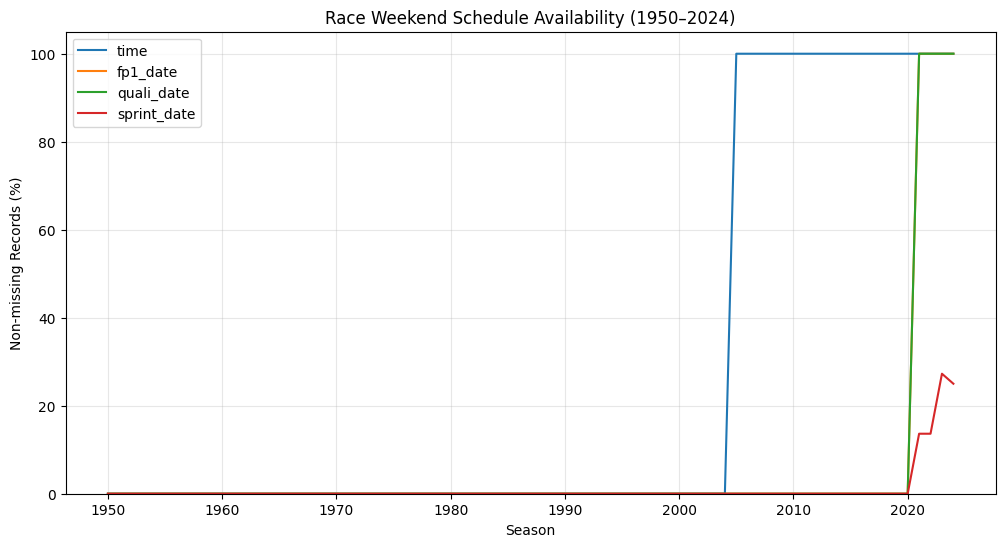

In [562]:

plt.figure(figsize=(12, 6))

for column in [
    'time',
    'fp1_date',
    'quali_date',
    'sprint_date'
]:
    plt.plot(
        schedule_availability.index,
        schedule_availability[column],
        label=column
    )

plt.title('Race Weekend Schedule Availability (1950–2024)')
plt.xlabel('Season')
plt.ylabel('Non-missing Records (%)')

plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)

plt.show()


**Decision: schedule NaNs are kept, not filled.**
- They are structurally missing, not errors: practice/qualifying dates are only recorded from 2021 (times from 2022), sprint columns exist only at sprint weekends, and race start `time` only in recent seasons.
- No other table holds these values (`qualifying` and `sprint_results` have no dates), so they cannot be recovered; filling them would invent data and turn the datetime columns back into text.
- These columns are not model features, so NaN is the correct representation.

#### 4.6.3 Date consistency checks

In [563]:

# Check that each race date belongs to its recorded season
year_mismatches = races_clean[
    races_clean['date'].dt.year != races_clean['year']
]

print(
    "Race dates outside their recorded season:",
    len(year_mismatches)
)

display(
    year_mismatches[
        ['raceId', 'year', 'round', 'name', 'date']
    ]
)


Race dates outside their recorded season: 0


,raceId,year,round,name,date


In [564]:

# Sort races within each season by championship round
races_ordered = races_clean.sort_values(
    ['year', 'round']
).copy()

# Previous round's race date
races_ordered['previous_date'] = (
    races_ordered.groupby('year')['date'].shift(1)
)

# Identify races scheduled before the preceding round
round_date_issues = races_ordered[
    races_ordered['previous_date'].notna()
    & (races_ordered['date'] < races_ordered['previous_date'])
]

print(
    "Races earlier than the previous round:",
    len(round_date_issues)
)

display(
    round_date_issues[
        ['raceId', 'year', 'round',
         'name', 'date', 'previous_date']
    ]
)


Races earlier than the previous round: 0


,raceId,year,round,name,date,previous_date


In [565]:

session_date_columns = [
    'fp1_date',
    'fp2_date',
    'fp3_date',
    'quali_date',
    'sprint_date'
]

for col in session_date_columns:

    issues = races_clean[
        races_clean[col].notna()
        & (races_clean[col] > races_clean['date'])
    ]

    print(f"{col}: {len(issues)} dates after race day")

    if not issues.empty:
        display(
            issues[
                ['raceId', 'year', 'name',
                 'date', col]
            ]
        )


fp1_date: 0 dates after race day
fp2_date: 0 dates after race day
fp3_date: 0 dates after race day
quali_date: 0 dates after race day
sprint_date: 0 dates after race day


### 4.7 qualifying_clean: integrity and missing values

In [566]:

# Check qualifying record integrity
print("Original shape:", qualifying.shape)
print("Cleaned shape:", qualifying_clean.shape)

print("\nExact duplicate rows:",
      qualifying_clean.duplicated().sum())

print("Missing qualify IDs:",
      qualifying_clean['qualifyId'].isna().sum())

print("Duplicate qualify IDs:",
      qualifying_clean['qualifyId'].duplicated().sum())

print("Duplicate race-driver combinations:",
      qualifying_clean.duplicated(
          subset=['raceId', 'driverId']
      ).sum())

# Display any duplicated race-driver entries
duplicate_qualifying = qualifying_clean[
    qualifying_clean.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].sort_values(['raceId', 'driverId'])

display(
    duplicate_qualifying[
        [
            'qualifyId', 'raceId', 'driverId',
            'constructorId', 'number', 'position',
            'q1', 'q2', 'q3'
        ]
    ]
)


Original shape: (10494, 9)
Cleaned shape: (10494, 12)

Exact duplicate rows: 0
Missing qualify IDs: 0
Duplicate qualify IDs: 0
Duplicate race-driver combinations: 0


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3


In [567]:

missing = qualifying_clean.isna().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': (
        missing / len(qualifying_clean) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report['Missing Count'] > 0
    ].sort_values(
        'Missing Count',
        ascending=False
    )
)


,Missing Count,Missing %
q3_seconds,6865,65.42
q3,6865,65.42
q2_seconds,4647,44.28
q2,4647,44.28
q1,156,1.49
q1_seconds,156,1.49


#### 4.7.1 Session-time patterns

In [568]:

# Add race, driver and constructor information for inspection
qualifying_inspection = (
    qualifying_clean
    .merge(
        races_clean[['raceId', 'year', 'round', 'name']],
        on='raceId',
        how='left'
    )
    .merge(
        drivers[['driverId', 'forename', 'surname']],
        on='driverId',
        how='left'
    )
    .merge(
        constructors[['constructorId', 'name']],
        on='constructorId',
        how='left',
        suffixes=('_race', '_constructor')
    )
)

# Select readable columns
inspection_columns = [
    'year', 'round', 'name_race',
    'forename', 'surname', 'name_constructor',
    'number', 'position',
    'q1', 'q2', 'q3',
    'q1_seconds', 'q2_seconds', 'q3_seconds'
]

display(
    qualifying_inspection[inspection_columns].head(20)
)


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
0,2008,1,Australian Grand Prix,Lewis,Hamilton,McLaren,22,1,1:26.572,1:25.187,1:26.714,86.572,85.187,86.714
1,2008,1,Australian Grand Prix,Robert,Kubica,BMW Sauber,4,2,1:26.103,1:25.315,1:26.869,86.103,85.315,86.869
2,2008,1,Australian Grand Prix,Heikki,Kovalainen,McLaren,23,3,1:25.664,1:25.452,1:27.079,85.664,85.452,87.079
3,2008,1,Australian Grand Prix,Felipe,Massa,Ferrari,2,4,1:25.994,1:25.691,1:27.178,85.994,85.691,87.178
4,2008,1,Australian Grand Prix,Nick,Heidfeld,BMW Sauber,3,5,1:25.960,1:25.518,1:27.236,85.960,85.518,87.236
5,2008,1,Australian Grand Prix,Jarno,Trulli,Toyota,11,6,1:26.427,1:26.101,1:28.527,86.427,86.101,88.527
6,2008,1,Australian Grand Prix,Nico,Rosberg,Williams,7,7,1:26.295,1:26.059,1:28.687,86.295,86.059,88.687
7,2008,1,Australian Grand Prix,David,Coulthard,Red Bull,9,8,1:26.381,1:26.063,1:29.041,86.381,86.063,89.041
8,2008,1,Australian Grand Prix,Timo,Glock,Toyota,12,9,1:26.919,1:26.164,1:29.593,86.919,86.164,89.593
9,2008,1,Australian Grand Prix,Sebastian,Vettel,Toro Rosso,15,10,1:26.702,1:25.842,NaN,86.702,85.842,NaN


In [569]:

# Drivers with all three session times
all_sessions = qualifying_inspection[
    qualifying_inspection[
        ['q1', 'q2', 'q3']
    ].notna().all(axis=1)
]

# Drivers with Q1 and Q2, but no Q3
q1_q2_only = qualifying_inspection[
    qualifying_inspection['q1'].notna()
    & qualifying_inspection['q2'].notna()
    & qualifying_inspection['q3'].isna()
]

# Drivers with only Q1 recorded
q1_only = qualifying_inspection[
    qualifying_inspection['q1'].notna()
    & qualifying_inspection['q2'].isna()
    & qualifying_inspection['q3'].isna()
]

# Drivers with no Q1 time
missing_q1 = qualifying_inspection[
    qualifying_inspection['q1'].isna()
]

print("All Q1, Q2, Q3 recorded:", len(all_sessions))
print("Q1 and Q2 only:", len(q1_q2_only))
print("Q1 only:", len(q1_only))
print("Missing Q1:", len(missing_q1))

print("\nExample: all three sessions")
display(all_sessions[inspection_columns].head(5))

print("\nExample: Q1 and Q2 only")
display(q1_q2_only[inspection_columns].head(5))

print("\nExample: Q1 only")
display(q1_only[inspection_columns].head(5))

print("\nExample: missing Q1")
display(missing_q1[inspection_columns].head(10))


All Q1, Q2, Q3 recorded: 3629
Q1 and Q2 only: 2218
Q1 only: 4491
Missing Q1: 156

Example: all three sessions


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
0,2008,1,Australian Grand Prix,Lewis,Hamilton,McLaren,22,1,1:26.572,1:25.187,1:26.714,86.572,85.187,86.714
1,2008,1,Australian Grand Prix,Robert,Kubica,BMW Sauber,4,2,1:26.103,1:25.315,1:26.869,86.103,85.315,86.869
2,2008,1,Australian Grand Prix,Heikki,Kovalainen,McLaren,23,3,1:25.664,1:25.452,1:27.079,85.664,85.452,87.079
3,2008,1,Australian Grand Prix,Felipe,Massa,Ferrari,2,4,1:25.994,1:25.691,1:27.178,85.994,85.691,87.178
4,2008,1,Australian Grand Prix,Nick,Heidfeld,BMW Sauber,3,5,1:25.960,1:25.518,1:27.236,85.960,85.518,87.236



Example: Q1 and Q2 only


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
9,2008,1,Australian Grand Prix,Sebastian,Vettel,Toro Rosso,15,10,1:26.702,1:25.842,NaN,86.702,85.842,NaN
10,2008,1,Australian Grand Prix,Rubens,Barrichello,Honda,17,11,1:26.369,1:26.173,NaN,86.369,86.173,NaN
11,2008,1,Australian Grand Prix,Fernando,Alonso,Renault,5,12,1:26.907,1:26.188,NaN,86.907,86.188,NaN
12,2008,1,Australian Grand Prix,Jenson,Button,Honda,16,13,1:26.712,1:26.259,NaN,86.712,86.259,NaN
13,2008,1,Australian Grand Prix,Kazuki,Nakajima,Williams,8,14,1:26.891,1:26.413,NaN,86.891,86.413,NaN



Example: Q1 only


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
14,2008,1,Australian Grand Prix,Mark,Webber,Red Bull,10,15,1:26.914,NaN,NaN,86.914,NaN,NaN
15,2008,1,Australian Grand Prix,Kimi,Räikkönen,Ferrari,1,16,1:26.140,NaN,NaN,86.140,NaN,NaN
16,2008,1,Australian Grand Prix,Giancarlo,Fisichella,Force India,21,17,1:27.207,NaN,NaN,87.207,NaN,NaN
17,2008,1,Australian Grand Prix,Sébastien,Bourdais,Toro Rosso,14,18,1:27.446,NaN,NaN,87.446,NaN,NaN
18,2008,1,Australian Grand Prix,Adrian,Sutil,Force India,20,19,1:27.859,NaN,NaN,87.859,NaN,NaN



Example: missing Q1


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
147,2008,7,Canadian Grand Prix,Sebastian,Vettel,Toro Rosso,15,20,NaN,NaN,NaN,NaN,NaN,NaN
307,2008,15,Singapore Grand Prix,Giancarlo,Fisichella,Force India,21,20,NaN,NaN,NaN,NaN,NaN,NaN
455,2007,4,Spanish Grand Prix,Scott,Speed,Toro Rosso,19,22,NaN,NaN,NaN,NaN,NaN,NaN
477,2007,5,Monaco Grand Prix,Christijan,Albers,Spyker,21,22,NaN,NaN,NaN,NaN,NaN,NaN
763,2006,1,Bahrain Grand Prix,Kimi,Räikkönen,McLaren,3,22,NaN,NaN,NaN,NaN,NaN,NaN
873,2006,6,Spanish Grand Prix,David,Coulthard,Red Bull,14,22,NaN,NaN,NaN,NaN,NaN,NaN
894,2006,7,Monaco Grand Prix,Felipe,Massa,Ferrari,6,21,NaN,NaN,NaN,NaN,NaN,NaN
895,2006,7,Monaco Grand Prix,Michael,Schumacher,Ferrari,5,22,NaN,NaN,NaN,NaN,NaN,NaN
917,2006,8,British Grand Prix,Jarno,Trulli,Toyota,8,22,NaN,NaN,NaN,NaN,NaN,NaN
1005,2006,12,German Grand Prix,Scott,Speed,Toro Rosso,21,22,NaN,NaN,NaN,NaN,NaN,NaN


In [570]:

# Select a specific race
selected_race = qualifying_inspection[
    (qualifying_inspection['year'] == 2024)
    & (qualifying_inspection['name_race'] == 'Bahrain Grand Prix')
].sort_values('position')

display(
    selected_race[
        [
            'position', 'forename', 'surname',
            'name_constructor', 'number',
            'q1', 'q2', 'q3',
            'q1_seconds', 'q2_seconds', 'q3_seconds'
        ]
    ]
)


,position,forename,surname,name_constructor,number,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
10015,1,Max,Verstappen,Red Bull,1,1:30.031,1:29.374,1:29.179,90.031,89.374,89.179
10016,2,Charles,Leclerc,Ferrari,16,1:30.243,1:29.165,1:29.407,90.243,89.165,89.407
10017,3,George,Russell,Mercedes,63,1:30.350,1:29.922,1:29.485,90.350,89.922,89.485
10018,4,Carlos,Sainz,Ferrari,55,1:29.909,1:29.573,1:29.507,89.909,89.573,89.507
10019,5,Sergio,Pérez,Red Bull,11,1:30.221,1:29.932,1:29.537,90.221,89.932,89.537
10020,6,Fernando,Alonso,Aston Martin,14,1:30.179,1:29.801,1:29.542,90.179,89.801,89.542
10021,7,Lando,Norris,McLaren,4,1:30.143,1:29.941,1:29.614,90.143,89.941,89.614
10022,8,Oscar,Piastri,McLaren,81,1:30.531,1:30.122,1:29.683,90.531,90.122,89.683
10023,9,Lewis,Hamilton,Mercedes,44,1:30.451,1:29.718,1:29.710,90.451,89.718,89.710
10024,10,Nico,Hülkenberg,Haas F1 Team,27,1:30.566,1:29.851,1:30.502,90.566,89.851,90.502


#### 4.7.2 Label missing session times
Only the string columns get labels; the numeric `*_seconds` columns keep NaN on purpose.
Knockout qualifying (Q1/Q2/Q3) started in 2006; earlier formats varied (2005 still recorded a second time for 107 rows), so a missing pre-2006 Q2/Q3 gets a neutral historical label.
From 2006 a missing later session usually means elimination, but a driver can also advance or start without a valid time, so the labels only say the time was not recorded.

In [571]:
# Determine which sessions have recorded lap times
has_q1 = qualifying_clean['q1_seconds'].notna()
has_q2 = qualifying_clean['q2_seconds'].notna()
has_q3 = qualifying_clean['q3_seconds'].notna()

# Pattern 1: Q1 and Q2 recorded, Q3 missing
q2_only_end = has_q1 & has_q2 & ~has_q3

# Pattern 2: Only Q1 recorded
q1_only_end = has_q1 & ~has_q2 & ~has_q3

# Pattern 3: No qualifying session times recorded
no_times = ~has_q1 & ~has_q2 & ~has_q3

# Knockout format (Q1/Q2/Q3) only exists from 2006
qualifying_year = qualifying_clean['raceId'].map(
    races_clean.set_index('raceId')['year']
)
knockout_era = qualifying_year >= 2006

# Evidence: which pre-2006 seasons recorded a second session time
pre_2006_with_q2 = ~knockout_era & (has_q2 | has_q3)
print("Pre-2006 rows with a Q2 or Q3 time:", pre_2006_with_q2.sum())
print(qualifying_year[pre_2006_with_q2].value_counts().sort_index())

# Fill only missing values in the original string columns
# Knockout era: no time in a later session (usually elimination, but not always)
qualifying_clean.loc[q2_only_end & knockout_era, 'q3'] = (
    'Not Recorded After Q2'
)

qualifying_clean.loc[q1_only_end & knockout_era, ['q2', 'q3']] = (
    'Not Recorded After Q1'
)

# Pre-2006: formats varied, so the label is neutral
qualifying_clean.loc[has_q1 & ~has_q2 & ~knockout_era, 'q2'] = (
    'Not Recorded (Historical Format)'
)

qualifying_clean.loc[has_q1 & ~has_q3 & ~knockout_era, 'q3'] = (
    'Not Recorded (Historical Format)'
)

qualifying_clean.loc[no_times, ['q1', 'q2', 'q3']] = (
    'No Qualifying Time Recorded'
)

# Check how many missing values remain
print("Missing descriptive fields:")
print(qualifying_clean[['q1', 'q2', 'q3']].isna().sum())

print("\nNumeric time missingness (intentionally preserved):")
print(
    qualifying_clean[
        ['q1_seconds', 'q2_seconds', 'q3_seconds']
    ].isna().sum()
)


Pre-2006 rows with a Q2 or Q3 time: 107
raceId
2005    107
Name: count, dtype: int64
Missing descriptive fields:
q1    0
q2    0
q3    0
dtype: int64

Numeric time missingness (intentionally preserved):
q1_seconds     156
q2_seconds    4647
q3_seconds    6865
dtype: int64


In [572]:

print("Q1 values:")
display(qualifying_clean['q1'].value_counts(dropna=False).head(10))

print("\nQ2 labels:")
print(
    qualifying_clean['q2']
    .value_counts(dropna=False)
    .loc[lambda x: x.index.isin([
        'Not Recorded After Q1',
        'Not Recorded (Historical Format)',
        'No Qualifying Time Recorded'
    ])]
)

print("\nQ3 labels:")
print(
    qualifying_clean['q3']
    .value_counts(dropna=False)
    .loc[lambda x: x.index.isin([
        'Not Recorded After Q1',
        'Not Recorded After Q2',
        'Not Recorded (Historical Format)',
        'No Qualifying Time Recorded'
    ])]
)

display(
    qualifying_clean[
        ['raceId', 'driverId', 'position',
         'q1', 'q2', 'q3',
         'q1_seconds', 'q2_seconds', 'q3_seconds']
    ].head(15)
)


Q1 values:


q1
No Qualifying Time Recorded    156
1:20.382                         4
1:20.888                         4
1:17.244                         4
1:21.891                         3
1:34.646                         3
1:18.811                         3
1:21.901                         3
1:14.412                         3
1:16.259                         3
Name: count, dtype: int64


Q2 labels:
q2
Not Recorded (Historical Format)    2416
Not Recorded After Q1               2075
No Qualifying Time Recorded          156
Name: count, dtype: int64

Q3 labels:
q3
Not Recorded (Historical Format)    2523
Not Recorded After Q2               2111
Not Recorded After Q1               2075
No Qualifying Time Recorded          156
Name: count, dtype: int64


,raceId,driverId,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
0,18,1,1,1:26.572,1:25.187,1:26.714,86.572,85.187,86.714
1,18,9,2,1:26.103,1:25.315,1:26.869,86.103,85.315,86.869
2,18,5,3,1:25.664,1:25.452,1:27.079,85.664,85.452,87.079
3,18,13,4,1:25.994,1:25.691,1:27.178,85.994,85.691,87.178
4,18,2,5,1:25.960,1:25.518,1:27.236,85.960,85.518,87.236
5,18,15,6,1:26.427,1:26.101,1:28.527,86.427,86.101,88.527
6,18,3,7,1:26.295,1:26.059,1:28.687,86.295,86.059,88.687
7,18,14,8,1:26.381,1:26.063,1:29.041,86.381,86.063,89.041
8,18,10,9,1:26.919,1:26.164,1:29.593,86.919,86.164,89.593
9,18,20,10,1:26.702,1:25.842,Not Recorded After Q2,86.702,85.842,NaN


### 4.8 status_clean: status categories
Q3 needs to know which statuses are mechanical retirements, and results cleaning needs to know which mean the driver never started; both come from one explicit mapping.

In [573]:
# Every status with how many result rows use it
status_usage = (
    results_clean['statusId'].value_counts()
    .rename('result_rows')
    .reset_index()
)

status_overview = status_clean.merge(
    status_usage, on='statusId', how='left'
)
status_overview['result_rows'] = status_overview['result_rows'].fillna(0).astype(int)

print("Statuses:", len(status_overview))
print("Statuses never used in results:", (status_overview['result_rows'] == 0).sum())

with pd.option_context('display.max_rows', None):
    display(status_overview.sort_values('result_rows', ascending=False))

Statuses: 139
Statuses never used in results: 2


,statusId,status,result_rows
0,1,Finished,7674
10,11,+1 Lap,4037
4,5,Engine,2026
11,12,+2 Laps,1613
2,3,Accident,1062
80,81,Did not qualify,1025
3,4,Collision,854
5,6,Gearbox,810
19,20,Spun off,795
12,13,+3 Laps,731


#### 4.8.1 Map each status to a category
Following the brief, a mechanical retirement is a race start that ended because a car component failed; crashes, driver causes and regulation decisions are excluded.

In [574]:
import re

did_not_start = {
    'Did not qualify', 'Did not prequalify', 'Withdrew'
}

# 'Not classified' is left out on purpose: it means too little distance was
# covered to be classified, not a regulation decision, so it falls into 'other'
regulation = {
    'Disqualified', 'Excluded', '107% Rule', 'Underweight',
    'Safety concerns', 'Safety'
}

accident = {
    'Accident', 'Collision', 'Collision damage', 'Spun off',
    'Fatal accident', 'Damage', 'Debris'
}

mechanical = {
    # Power unit and engine
    'Engine', 'Engine fire', 'Engine misfire', 'Power Unit', 'ERS',
    'Turbo', 'Supercharger', 'Power loss', 'Ignition', 'Spark plugs',
    'Magneto', 'Distributor', 'Injection', 'Alternator', 'Battery',
    'Electrical', 'Electronics', 'Crankshaft', 'Overheating',
    'Cooling system', 'Radiator', 'Exhaust',
    # Fluids
    'Oil leak', 'Oil pressure', 'Oil pump', 'Oil line', 'Oil pipe',
    'Water leak', 'Water pressure', 'Water pump', 'Water pipe',
    'Fuel system', 'Fuel pressure', 'Fuel pump', 'Fuel leak',
    'Fuel pipe', 'Fuel', 'Hydraulics', 'Pneumatics',
    # Drivetrain
    'Gearbox', 'Transmission', 'Clutch', 'Differential', 'Driveshaft',
    'Halfshaft', 'Drivetrain', 'CV joint', 'Axle', 'Launch control',
    # Chassis, suspension, brakes, wheels
    'Suspension', 'Track rod', 'Steering', 'Brakes', 'Brake duct',
    'Wheel bearing', 'Wheel rim', 'Chassis', 'Undertray', 'Rear wing',
    'Throttle', 'Vibrations', 'Heat shield fire', 'Fire',
    'Driver Seat', 'Seat', 'Safety belt',
    # Generic failures
    'Mechanical', 'Technical'
}


def status_category(name):
    # 'Finished' or lapped finishers such as '+1 Lap', '+2 Laps'
    if name == 'Finished' or re.fullmatch(r'\+\d+ Laps?', name):
        return 'finished'
    if name in did_not_start:
        return 'did_not_start'
    if name in regulation:
        return 'regulation'
    if name in accident:
        return 'accident'
    if name in mechanical:
        return 'mechanical'
    return 'other'


status_clean['category'] = status_clean['status'].apply(status_category)
status_clean['is_mechanical'] = status_clean['category'] == 'mechanical'

# Names in the lists that do not exist in the data (catches spelling mismatches)
all_listed = did_not_start | regulation | accident | mechanical
print("Listed names not found in status table:",
      sorted(all_listed - set(status_clean['status'])))

# Result rows per category
category_rows = (
    results_clean.merge(status_clean, on='statusId', how='left', validate='many_to_one')
    ['category'].value_counts()
)
print("\nResult rows per category:")
print(category_rows)

# Everything left as 'other' is shown for review
print("\nStatuses in 'other':")
display(
    status_overview.merge(status_clean[['statusId', 'category']], on='statusId')
    .query("category == 'other'")
    .sort_values('result_rows', ascending=False)
)

assert status_clean['category'].notna().all()
assert len(status_clean) == len(status)

Listed names not found in status table: []

Result rows per category:
category
finished         15161
mechanical        6334
accident          2777
did_not_start     1604
other              714
regulation         169
Name: count, dtype: int64

Statuses in 'other':


,statusId,status,result_rows,category
61,62,Not classified,172,other
30,31,Retired,107,other
59,60,Out of fuel,100,other
35,36,Wheel,88,other
26,27,Tyre,55,other
63,64,Handling,54,other
28,29,Puncture,41,other
67,68,Physical,31,other
81,82,Injury,13,other
40,41,Broken wing,11,other


**Decision: borderline statuses are not counted as mechanical.**
- `Retired` gives no cause, and tyre/puncture, wheel nut, refuelling, out of fuel, stalled, front/broken wing and handling can come from debris, contact, pit work or strategy, so they stay in 'other'.
- Driver health (injury, illness) is a driver cause, `Not restarted` happened after a stoppage, and `Not classified` only means too little distance was covered (it is neither a failure nor a regulation decision), so all are kept in 'other'.
- Categories rely on the recorded retirement reason, which can be vague or ambiguous; the mechanical rate is therefore an estimate based on recorded statuses (a conservative, lower-bound one), not an exact count of every mechanical failure. The full 'other' list is shown above so the choice can be checked.
- Impact is small: before `Not classified` was moved, 'other' covered 542 of 26,759 result rows (about 2%) against 6,334 mechanical rows; the updated counts are printed above. The largest borderline groups are `Retired` (107), `Out of fuel` (100) and `Wheel` (88).
- All listed names exist in the data and every result row gets a category; `did_not_start` (1,604 rows) is larger than the grid = 0 non-starters (1,508), so non-starters are identified by status, not by grid.
- Q3 uses actual race starters as the denominator (all rows except `did_not_start`), so drivers who never started do not dilute the mechanical-retirement rate.

### 4.9 results_clean: building the modeling table
`results` becomes the modeling table (one row per driver per race); its cleaning comes after the status categories (4.8), which it uses to identify non-starters.

#### 4.9.1 Snapshot before cleaning
The raw state is recorded first so the after-cleaning EDA can show exactly what each step changed.

In [575]:
results_before = results.merge(
    races_clean[['raceId', 'year']], on='raceId', how='left', validate='many_to_one'
)
results_before['is_podium'] = results_before['positionOrder'] <= 3

before_summary = pd.Series({
    'rows': len(results_before),
    'races': results_before['raceId'].nunique(),
    'drivers': results_before['driverId'].nunique(),
    'duplicate (raceId, driverId) rows': results_before.duplicated(['raceId', 'driverId']).sum(),
    'podium rows': results_before['is_podium'].sum(),
    'podium rate (%)': round(results_before['is_podium'].mean() * 100, 2)
}, name='before cleaning')
display(before_summary.to_frame())

missing_before = (results.isna().mean() * 100).round(2).rename('missing % before')
display(missing_before[missing_before > 0].to_frame())

rows_per_season_before = results_before.groupby('year').size().rename('rows before')
podium_rate_before = (results_before.groupby('year')['is_podium'].mean() * 100).rename('podium % before')

,before cleaning
rows,26759.00
races,1125.00
drivers,861.00
"duplicate (raceId, driverId) rows",91.00
podium rows,3397.00
podium rate (%),12.69


,missing % before
number,0.02
position,40.93
time,71.30
milliseconds,71.30
fastestLap,69.16
rank,68.20
fastestLapTime,69.16
fastestLapSpeed,69.16


#### 4.9.2 Missing car numbers
Six rows have no car number; these cells check whether they are real race entries or part of a duplicate group.

In [576]:
# Find all result rows with missing car numbers
missing_numbers = results[
    results['number'].isna()
].copy()

# Identify all rows belonging to duplicate driver-race groups
duplicate_pairs = results.loc[
    results.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    ),
    ['raceId', 'driverId']
].drop_duplicates()

# Check which missing-number records belong to duplicate groups
missing_numbers = missing_numbers.merge(
    duplicate_pairs.assign(in_duplicate_group=True),
    on=['raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

missing_numbers['in_duplicate_group'] = (
    missing_numbers['in_duplicate_group'].eq(True)
)

display(
    missing_numbers[
        ['raceId', 'driverId', 'constructorId',
         'number', 'grid', 'positionOrder',
         'in_duplicate_group']
    ]
)

print("Total missing car numbers:", len(missing_numbers))

print(
    "Missing-number rows in duplicate groups:",
    missing_numbers['in_duplicate_group'].sum()
)


,raceId,driverId,constructorId,number,grid,positionOrder,in_duplicate_group
0,732,459,66,NaN,0,19,False
1,732,462,95,NaN,0,20,False
2,732,446,172,NaN,0,21,False
3,732,437,170,NaN,0,22,False
4,741,485,172,NaN,0,28,False
5,728,305,26,NaN,0,23,False


Total missing car numbers: 6
Missing-number rows in duplicate groups: 0


In [577]:
# Start with the six records with missing car numbers
missing_numbers_details = results[
    results['number'].isna()
].copy()

# Add race status descriptions
missing_numbers_details = missing_numbers_details.merge(
    status[['statusId', 'status']],
    on='statusId',
    how='left',
    validate='many_to_one'
)

# Add race information
missing_numbers_details = missing_numbers_details.merge(
    races[['raceId', 'year', 'name', 'date']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

# Display relevant information
display(
    missing_numbers_details[
        ['year', 'name', 'driverId',
         'constructorId', 'number', 'grid',
         'laps', 'positionOrder', 'status']
    ].sort_values('year')
)


,year,name,driverId,constructorId,number,grid,laps,positionOrder,status
4,1961,French Grand Prix,485,172,NaN,0,0,28,Withdrew
0,1962,French Grand Prix,459,66,NaN,0,0,19,Withdrew
2,1962,French Grand Prix,446,172,NaN,0,0,21,Withdrew
1,1962,French Grand Prix,462,95,NaN,0,0,20,Withdrew
3,1962,French Grand Prix,437,170,NaN,0,0,22,Withdrew
5,1963,South African Grand Prix,305,26,NaN,0,0,23,Withdrew


**Decision: the 6 rows with no car number are not dropped here.**
All 6 are `Withdrew` entries (grid 0, 0 laps, 1961–1963) and none is in a duplicate group, so they are non-starters; they are removed with all other non-starters in 4.9.7, for that reason rather than because the car number is missing (car number is not a feature).

#### 4.9.3 Duplicate (raceId, driverId) rows: which row is the original entry?
The fallback in 4.9.4 keeps the earliest row (lowest `resultId`), so first check how the IDs behave: in each duplicate group, is there a row whose `resultId` lies above every normal row of that race, i.e. a row added later for a car taken over?

In [578]:
is_dup = results_clean.duplicated(['raceId', 'driverId'], keep=False)
duplicate_rows = results_clean[is_dup].copy()

# Highest resultId among the normal rows of each race
normal_max_id = results_clean[~is_dup].groupby('raceId')['resultId'].max()
duplicate_rows['late_added'] = (
    duplicate_rows['resultId'] > duplicate_rows['raceId'].map(normal_max_id)
)

late_per_group = duplicate_rows.groupby(['raceId', 'driverId'])['late_added'].sum()

print("Duplicate groups:", len(late_per_group))
print("Rows in duplicate groups:", len(duplicate_rows))
print("\nGroups by number of late-added rows:")
print(late_per_group.value_counts().sort_index().rename_axis('late-added rows').to_string())

# Groups that do not follow the pattern (not exactly one late-added row)
unusual = late_per_group[late_per_group != 1].index
display(
    duplicate_rows.set_index(['raceId', 'driverId']).loc[unusual]
    [['resultId', 'constructorId', 'grid', 'positionOrder', 'late_added']]
)

Duplicate groups: 85
Rows in duplicate groups: 176

Groups by number of late-added rows:
late-added rows
0    39
1    44
2     2


resultId  constructorId  grid  positionOrder  late_added
raceId driverId                                                          
540    229          13189             54     0             26       False
       229          13192             57     0             29       False
733    465          17741            172     0             22       False
       465          17744             97     0             25       False
742    475          17962            102    20             19       False
...                   ...            ...   ...            ...         ...
828    579          20186             51     7              1       False
       647          19919              6     6              2       False
       647          19935              6     3             18       False
835    529          20097            150     8             31       False
       529          20179            113     9              5       False

[86 rows x 5 columns]

#### 4.9.4 Keep one row per driver per race
The row is chosen without looking at the race result: a unique qualifying match (car number + constructor) first, otherwise the original entry. The target is created later from the kept row (4.9.11).

In [579]:
keys = ['raceId', 'driverId']
rows_before_dedup = len(results_clean)

work = results_clean.copy().reset_index(drop=True)
work['_original_order'] = np.arange(len(work))      # results file order = resultId order
work['_group_size'] = work.groupby(keys)['resultId'].transform('size')

# Car the driver qualified with (car number + constructor)
qual_ref = qualifying_clean[keys + ['number', 'constructorId']].rename(columns={
    'number': 'qual_number',
    'constructorId': 'qual_constructorId'
})
assert not qual_ref.duplicated(keys).any()

work = work.merge(qual_ref, on=keys, how='left', validate='many_to_one')

work['_car_match'] = (
    work['number'].eq(work['qual_number'])
    & work['constructorId'].eq(work['qual_constructorId'])
)
match_count = work.groupby(keys)['_car_match'].transform('sum')
work['_preferred'] = work['_car_match'] & match_count.eq(1)

# Choose the row WITHOUT using the race result:
# unique qualifying match first, otherwise the original entry (earliest row)
ranked = work.sort_values(
    ['raceId', 'driverId', '_preferred', '_original_order'],
    ascending=[True, True, False, True],
    kind='stable'
)
keep_mask = ~ranked.duplicated(keys, keep='first')
duplicates_removed = ranked.loc[~keep_mask].copy()
selected = ranked.loc[keep_mask].copy()

# How the row was chosen (only duplicate groups involve a choice)
selected['selection_method'] = np.select(
    [selected['_group_size'].eq(1), selected['_preferred']],
    ['single_record', 'unique_qualifying_match'],
    default='original_entry_fallback'
)

results_clean = (
    selected.drop(columns=['_original_order', '_group_size', 'qual_number',
                           'qual_constructorId', '_car_match', '_preferred'])
    .sort_values(keys)
    .reset_index(drop=True)
)

print("Rows before:", rows_before_dedup)
print("Duplicates removed:", len(duplicates_removed))
print("Rows after:", len(results_clean))

print("\nHow the kept row was chosen:")
print(results_clean['selection_method'].value_counts().to_string())

assert not results_clean.duplicated(keys).any()
assert len(results_clean) == rows_before_dedup - len(duplicates_removed)

Rows before: 26759
Duplicates removed: 91
Rows after: 26668

How the kept row was chosen:
selection_method
single_record              26583
original_entry_fallback       85


**Decision: duplicate (raceId, driverId) rows — the kept row is chosen without using the race result.**
- 85 driver-race groups (176 rows, all shared drives from 1950–1960) are reduced to one row each: 91 rows removed, 26,759 → 26,668, and uniqueness is asserted.
- The race result (`positionOrder`) plays no part in the choice, so the outcome cannot decide which grid and constructor become features. A unique qualifying match (car number + constructor) is preferred; otherwise the earliest row, the driver's original entry, is kept.
- All duplicate groups are from 1950–1960, before qualifying data begins (3.7), so they use the original-entry fallback (see the selection counts above). The fallback is a consistent convention: 4.9.3 shows the later-added row pattern holds for 44 of 85 groups, so it is not a proven reconstruction for every group.
- The target is then taken from the kept row's own finish (4.9.11), so the label and the features describe the same car entry. Consequence: a driver whose other car reached the podium gets `podium` = 0 if his original entry did not; 4.9.11 shows how many drivers this affects.
- These rows only exist in 1950–1960; if training starts in 1994 they do not reach the model.
- Because these kept rows may not carry the driver's full podium outcome, they are flagged in 6.1 (`ambiguous_shared_drive`) and left out of model training and evaluation.

#### 4.9.5 Non-starters (evidence only, nothing removed yet)
A prediction row is "a driver entering a race"; drivers who did not qualify, did not prequalify or withdrew never started, so they cannot finish on the podium. They are identified by the status categories (4.8), not by grid = 0.

In [580]:
results_status = results_clean.merge(
    status_clean[['statusId', 'status', 'category']],
    on='statusId', how='left', validate='many_to_one'
)
non_starter = results_status['category'] == 'did_not_start'

print("Rows:", len(results_status))
print("Non-starter rows:", non_starter.sum())
print(results_status.loc[non_starter, 'status'].value_counts().to_string())

# Non-starters that a grid = 0 filter would miss
print("\nNon-starters with grid > 0:", (non_starter & (results_status['grid'] > 0)).sum())
display(
    results_status.loc[non_starter & (results_status['grid'] > 0),
                       ['raceId', 'driverId', 'grid', 'laps', 'positionOrder', 'status']].head(10)
)

# grid = 0 rows that would remain: should all be real starters
remaining_grid_zero = results_status[~non_starter & (results_status['grid'] == 0)]
print("grid = 0 rows remaining after removal:", len(remaining_grid_zero))
print("  of which completed at least one lap:", (remaining_grid_zero['laps'] > 0).sum())
print(remaining_grid_zero['category'].value_counts().to_string())

# Effect on the target (top-three finishes; the podium column is created in 4.9.11)
print("\nNon-starters with a podium:", (non_starter & (results_status['positionOrder'] <= 3)).sum())
print("Podium rate with non-starters:   ",
      round((results_status['positionOrder'] <= 3).mean() * 100, 2), "%")
print("Podium rate without non-starters:",
      round((results_status.loc[~non_starter, 'positionOrder'] <= 3).mean() * 100, 2), "%")

Rows: 26668
Non-starter rows: 1601
status
Did not qualify       1024
Did not prequalify     330
Withdrew               247

Non-starters with grid > 0: 96


,raceId,driverId,grid,laps,positionOrder,status
1634,79,2,15,0,19,Withdrew
1635,79,4,6,0,11,Withdrew
1636,79,8,2,0,8,Withdrew
1637,79,11,8,0,12,Withdrew
1638,79,13,10,0,14,Withdrew
1639,79,14,16,0,20,Withdrew
1640,79,15,1,0,7,Withdrew
1641,79,17,9,0,13,Withdrew
1642,79,18,3,0,9,Withdrew
1643,79,21,4,0,10,Withdrew


grid = 0 rows remaining after removal: 130
  of which completed at least one lap: 72
category
finished      56
accident      25
mechanical    19
regulation    17
other         13

Non-starters with a podium: 0
Podium rate with non-starters:    12.67 %
Podium rate without non-starters: 13.48 %


#### 4.9.6 Indianapolis 500 (evidence only, nothing removed yet)
The Indy 500 counted toward the championship in 1950–1960 but was run to American rules with its own entry list; the check below measures how separate its field really was.

In [581]:
indy_race_ids = races_clean.loc[races_clean['name'] == 'Indianapolis 500', 'raceId']
results_years = results_clean.merge(races_clean[['raceId', 'year']], on='raceId', how='left')
is_indy = results_years['raceId'].isin(indy_race_ids)

print("Indy 500 races:", len(indy_race_ids),
      "| seasons:", sorted(races_clean.loc[races_clean['raceId'].isin(indy_race_ids), 'year']))
print("Indy 500 result rows:", is_indy.sum())
print("Indy 500 podium rows:", (is_indy & (results_years['positionOrder'] <= 3)).sum())

indy_drivers = set(results_years.loc[is_indy, 'driverId'])
other_drivers = set(results_years.loc[~is_indy, 'driverId'])
print("\nDrivers who raced the Indy 500:", len(indy_drivers))
print("  ...and never raced any other championship race:", len(indy_drivers - other_drivers))

indy_constructors = set(results_years.loc[is_indy, 'constructorId'])
other_constructors = set(results_years.loc[~is_indy, 'constructorId'])
print("Constructors at the Indy 500:", len(indy_constructors))
print("  ...that never entered any other championship race:", len(indy_constructors - other_constructors))

# Share of all 1950-1960 rows and podiums that come from the Indy 500
era = results_years['year'].between(1950, 1960)
print("\nShare of 1950-1960 result rows from Indy:",
      round(is_indy[era].mean() * 100, 1), "%")
print("Share of 1950-1960 podium rows from Indy:",
      round(is_indy[era & (results_years['positionOrder'] <= 3)].mean() * 100, 1), "%")

Indy 500 races: 11 | seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]
Indy 500 result rows: 381
Indy 500 podium rows: 35

Drivers who raced the Indy 500: 107
  ...and never raced any other championship race: 103
Constructors at the Indy 500: 34
  ...that never entered any other championship race: 31

Share of 1950-1960 result rows from Indy: 17.8 %
Share of 1950-1960 podium rows from Indy: 12.2 %


#### 4.9.7 Remove non-starters and the Indianapolis 500
Both removals were decided from the evidence in 4.9.5–4.9.6: non-starters cannot be prediction rows, and the Indy 500 had a separate field (103 of its 107 drivers never raced another championship race).

In [582]:
rows_raw = len(results)
rows_after_dedup = rows_before_dedup - len(duplicates_removed)

# 1. Non-starters, identified by status category (4.8)
non_starter_ids = status_clean.loc[status_clean['category'] == 'did_not_start', 'statusId']
is_non_starter = results_clean['statusId'].isin(non_starter_ids)
non_starters_removed = results_clean[is_non_starter]
results_clean = results_clean[~is_non_starter].copy()

# 2. Indianapolis 500 (1950-1960)
is_indy_row = results_clean['raceId'].isin(indy_race_ids)
indy_removed = results_clean[is_indy_row]
results_clean = results_clean[~is_indy_row].copy()

# Row log for the after-cleaning EDA
cleaning_log = pd.Series({
    'raw results': rows_raw,
    'after duplicate resolution': rows_after_dedup,
    'after removing non-starters': rows_after_dedup - len(non_starters_removed),
    'after excluding Indy 500': len(results_clean)
}, name='rows')
display(cleaning_log.to_frame())

print("Non-starters removed:", len(non_starters_removed))
print(non_starters_removed['statusId'].map(status_clean.set_index('statusId')['status']).value_counts().to_string())
print("Indy 500 rows removed:", len(indy_removed))

# Checks
assert not results_clean['statusId'].isin(non_starter_ids).any()
assert not results_clean['raceId'].isin(indy_race_ids).any()
assert not results_clean.duplicated(['raceId', 'driverId']).any()
assert results_clean['number'].notna().all()   # the 6 rows without a car number were non-starters
assert cleaning_log.iloc[-1] == len(results_clean)

,rows
raw results,26759
after duplicate resolution,26668
after removing non-starters,25067
after excluding Indy 500,24686


Non-starters removed: 1601
statusId
Did not qualify       1024
Did not prequalify     330
Withdrew               247
Indy 500 rows removed: 381


#### 4.9.8 Consistency checks
Values that must agree with each other or stay in a valid range are checked, so the target and the later joins rest on consistent data.

In [583]:
# Valid ranges
print("Negative points:", (results_clean['points'] < 0).sum())
print("Negative laps:", (results_clean['laps'] < 0).sum())
print("Negative grid:", (results_clean['grid'] < 0).sum())
print("positionOrder below 1:", (results_clean['positionOrder'] < 1).sum())
print("Grid range:", results_clean['grid'].min(), "-", results_clean['grid'].max())

# position (classified finish) must equal positionOrder wherever it exists
classified = results_clean['position'].notna()
print("\nposition != positionOrder (classified rows):",
      (results_clean.loc[classified, 'position'] != results_clean.loc[classified, 'positionOrder']).sum())

# positionOrder should be unique within a race; shared drives can repeat it
repeated_order = results_clean.duplicated(['raceId', 'positionOrder'], keep=False)
print("Rows sharing a positionOrder within a race:", repeated_order.sum())
display(
    results_clean.loc[repeated_order, ['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder']]
    .merge(races_clean[['raceId', 'year', 'name']], on='raceId')
    .sort_values(['year', 'raceId', 'positionOrder'])
    .head(20)
)

assert (results_clean[['points', 'laps', 'grid']] >= 0).all().all()
assert (results_clean['positionOrder'] >= 1).all()

Negative points: 0
Negative laps: 0
Negative grid: 0
positionOrder below 1: 0
Grid range: 0 - 34

position != positionOrder (classified rows): 13
Rows sharing a positionOrder within a race: 42


,raceId,driverId,constructorId,grid,positionOrder,year,name
38,833,778,105,20,10,1950,British Grand Prix
39,833,788,105,20,10,1950,British Grand Prix
36,833,661,151,10,20,1950,British Grand Prix
37,833,666,151,10,20,1950,British Grand Prix
40,838,741,154,4,5,1950,French Grand Prix
41,838,774,154,4,5,1950,French Grand Prix
34,828,498,6,6,2,1951,French Grand Prix
35,828,647,6,6,2,1951,French Grand Prix
32,820,721,6,17,11,1952,French Grand Prix
33,820,723,6,17,11,1952,French Grand Prix


In [584]:
# positionText codes (non-numeric) against the status categories
codes = results_clean.merge(status_clean[['statusId', 'category']], on='statusId', how='left')
non_numeric = ~codes['positionText'].astype(str).str.isdigit()
print("Non-numeric positionText values:")
display(pd.crosstab(codes.loc[non_numeric, 'positionText'], codes.loc[non_numeric, 'category']))

# Constructor in results vs. qualifying for the same driver and race
constructor_check = results_clean.merge(
    qualifying_clean[['raceId', 'driverId', 'constructorId']],
    on=['raceId', 'driverId'], how='inner', suffixes=('_results', '_qualifying')
)
mismatch = constructor_check['constructorId_results'] != constructor_check['constructorId_qualifying']
print("Driver-race pairs in both tables:", len(constructor_check))
print("Constructor mismatches:", mismatch.sum())
display(constructor_check[mismatch].head(10))

Non-numeric positionText values:


category,accident,finished,mechanical,other,regulation
positionText,,,,,
D,2,0,2,0,146
E,0,0,0,0,9
F,0,0,0,3,9
N,0,19,0,171,0
R,2513,5,5764,399,0
W,35,0,51,18,4


Driver-race pairs in both tables: 10455
Constructor mismatches: 10


,resultId,raceId,driverId,constructorId_results,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,selection_method,constructorId_qualifying
6469,22751,937,829,209,28.0,15,16.0,16,16,0.0,42,NaN,NaN,33.0,17.0,1:58.150,213.410,11,single_record,206
6473,22750,937,833,209,98.0,17,15.0,15,15,0.0,42,NaN,NaN,32.0,18.0,1:58.174,213.366,11,single_record,206
6549,22829,941,829,209,28.0,17,14.0,14,14,0.0,51,NaN,NaN,50.0,16.0,1:44.926,200.644,12,single_record,206
6552,22828,941,833,209,98.0,18,13.0,13,13,0.0,52,NaN,NaN,50.0,17.0,1:45.049,200.409,11,single_record,206
6568,22856,942,829,209,28.0,19,NaN,R,20,0.0,1,NaN,NaN,NaN,0.0,NaN,NaN,31,single_record,206
6572,22848,942,834,209,53.0,17,12.0,12,12,0.0,56,+1:15.277,6727980.0,50.0,16.0,1:48.173,183.472,1,single_record,206
6588,22872,943,829,209,28.0,17,16.0,16,16,0.0,69,NaN,NaN,67.0,19.0,1:25.540,181.136,12,single_record,206
6592,22871,943,834,209,53.0,16,15.0,15,15,0.0,69,NaN,NaN,69.0,18.0,1:25.005,182.276,12,single_record,206
6608,22893,944,829,209,28.0,18,17.0,17,17,0.0,67,NaN,NaN,42.0,19.0,1:19.098,196.116,14,single_record,206
6612,22894,944,834,209,53.0,17,18.0,18,18,0.0,67,NaN,NaN,43.0,18.0,1:18.617,197.316,14,single_record,206


#### 4.9.9 Missing values explained
The remaining missing values are compared with the status categories to show they are expected (not classified, not finished, or not timed in that era) rather than errors.

In [585]:
missing_after = (results_clean.isna().mean() * 100).round(2)
display(missing_after[missing_after > 0].rename('missing %').to_frame())

with_category = results_clean.merge(
    status_clean[['statusId', 'category']], on='statusId', how='left'
).merge(races_clean[['raceId', 'year']], on='raceId', how='left')

print("Status category of rows with no position (not classified):")
print(with_category.loc[with_category['position'].isna(), 'category'].value_counts().to_string())

print("\nStatus category of rows with no race time:")
print(with_category.loc[with_category['milliseconds'].isna(), 'category'].value_counts().to_string())

print("\nFinishers without a race time, by status:")
finished_no_time = with_category[(with_category['category'] == 'finished') & with_category['milliseconds'].isna()]
print(finished_no_time['statusId'].map(status_clean.set_index('statusId')['status']).value_counts().head(5).to_string())

print("\nFirst season with fastest-lap data:",
      with_category.loc[with_category['fastestLapTime'].notna(), 'year'].min())
print("Target column positionOrder missing:", results_clean['positionOrder'].isna().sum())

,missing %
position,37.07
time,69.43
milliseconds,69.43
fastestLap,66.59
rank,65.61
fastestLapTime,66.59
fastestLapSpeed,66.59


Status category of rows with no position (not classified):
category
mechanical    5817
accident      2550
other          591
regulation     168
finished        26

Status category of rows with no race time:
category
finished      7383
mechanical    6177
accident      2713
other          704
regulation     163

Finishers without a race time, by status:
statusId
+1 Lap     4020
+2 Laps    1603
+3 Laps     720
+4 Laps     392
+5 Laps     214

First season with fastest-lap data: 2004
Target column positionOrder missing: 0


**Decision: the remaining missing values in results are kept as NaN.**
- They belong to post-race columns (`position`, `time`, `milliseconds`, fastest lap, `rank`) and match the status breakdown above: no position for drivers who were not classified, no race time for drivers who did not finish or were lapped, and no fastest-lap data before the first season shown.
- None of these columns is used as a feature (they are only known after the race), and the target uses `positionOrder`, which has no missing values, so nothing is filled.

#### 4.9.10 Durations to seconds
Race time is taken from `milliseconds` (the `time` text holds gaps like "+1.234" for non-winners) and `fastestLapTime` ("1:30.123") is parsed like qualifying times.

In [586]:
results_clean['time_seconds'] = results_clean['milliseconds'] / 1000

results_clean['fastestLapTime_seconds'] = pd.to_timedelta(
    '00:' + results_clean['fastestLapTime'].dropna().astype(str),
    errors='coerce'
).dt.total_seconds()

failed_fastest = (
    results_clean['fastestLapTime'].notna() & results_clean['fastestLapTime_seconds'].isna()
).sum()

print("Race times converted:", results_clean['time_seconds'].notna().sum(),
      "of", results_clean['milliseconds'].notna().sum())
print("Fastest-lap conversion failures:", failed_fastest)
display(results_clean[['time', 'milliseconds', 'time_seconds',
                       'fastestLapTime', 'fastestLapTime_seconds']].dropna().head())

assert failed_fastest == 0
assert results_clean['time_seconds'].notna().sum() == results_clean['milliseconds'].notna().sum()

Race times converted: 7546 of 7546
Fastest-lap conversion failures: 0


,time,milliseconds,time_seconds,fastestLapTime,fastestLapTime_seconds
1,+7.085,5662869.0,5662.869,1:28.283,88.283
2,+5.722,5661506.0,5661.506,1:27.706,87.706
3,+4.879,5660663.0,5660.663,1:28.712,88.712
6,+6.298,5662082.0,5662.082,1:29.823,89.823
9,+4.435,5660219.0,5660.219,1:28.416,88.416


#### 4.9.11 Target: `podium`
The target is 1 when the kept row finished in the top three (`positionOrder <= 3`) and 0 otherwise. It is created only now, after the row was chosen (4.9.4) and the modeling population fixed (4.9.7), so the result never influenced which row was kept.

In [587]:
results_clean['podium'] = (results_clean['positionOrder'] <= 3).astype(int)

class_balance = results_clean['podium'].value_counts().sort_index()
print("Class balance:")
display(pd.DataFrame({
    'rows': class_balance,
    '%': (class_balance / len(results_clean) * 100).round(2)
}).rename(index={0: 'not podium', 1: 'podium'}))

print("Final results_clean shape:", results_clean.shape)

# Shared drives: drivers whose removed car finished top three but whose kept row did not
removed_top3 = (
    duplicates_removed.loc[duplicates_removed['positionOrder'] <= 3, ['raceId', 'driverId']]
    .drop_duplicates()
    .merge(results_clean[['raceId', 'driverId', 'podium']], on=['raceId', 'driverId'], how='inner')
)
print("\nDrivers whose other (removed) car finished top three:", len(removed_top3))
print("  ...of which the kept row is not a podium:", (removed_top3['podium'] == 0).sum())

# Podium rows per race
podiums_per_race = results_clean.groupby('raceId')['podium'].sum()
print("\nPodium rows per race:")
print(podiums_per_race.value_counts().sort_index().rename_axis('podium rows').to_string())
display(
    races_clean[races_clean['raceId'].isin(podiums_per_race[podiums_per_race != 3].index)]
    [['raceId', 'year', 'name']]
    .assign(podium_rows=lambda d: d['raceId'].map(podiums_per_race))
)

assert results_clean['podium'].isin([0, 1]).all()
assert not results_clean.duplicated(['raceId', 'driverId']).any()

Class balance:


,rows,%
podium,,
not podium,21342,86.45
podium,3344,13.55


Final results_clean shape: (24686, 22)

Drivers whose other (removed) car finished top three: 16
  ...of which the kept row is not a podium: 15

Podium rows per race:
podium rows
3    1112
4       2


,raceId,year,name,podium_rows
791,792,1955,Argentine Grand Prix,4
827,828,1951,French Grand Prix,4


#### 4.9.12 EDA before vs. after cleaning
Each plot compares the raw `results` table (gray) with `results_clean` (blue), so the effect of every cleaning step is visible, not only described.

In [588]:
# Shared style for the before/after plots
BEFORE_COLOR = '#9b9a95'   # neutral gray: raw data
AFTER_COLOR = '#2a78d6'    # blue: cleaned data
TEXT_COLOR = '#52514e'


def style_axes(ax, title, xlabel, ylabel):
    ax.set_title(title, loc='left', fontsize=12)
    ax.set_xlabel(xlabel, color=TEXT_COLOR)
    ax.set_ylabel(ylabel, color=TEXT_COLOR)
    ax.tick_params(colors=TEXT_COLOR)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)


# results_clean with its season, for the per-season plots
results_after = results_clean.merge(
    races_clean[['raceId', 'year']], on='raceId', how='left', validate='many_to_one'
)

**Rows removed by each step.** Shows how much each decision (duplicates, non-starters, Indy 500) changed the modeling table.

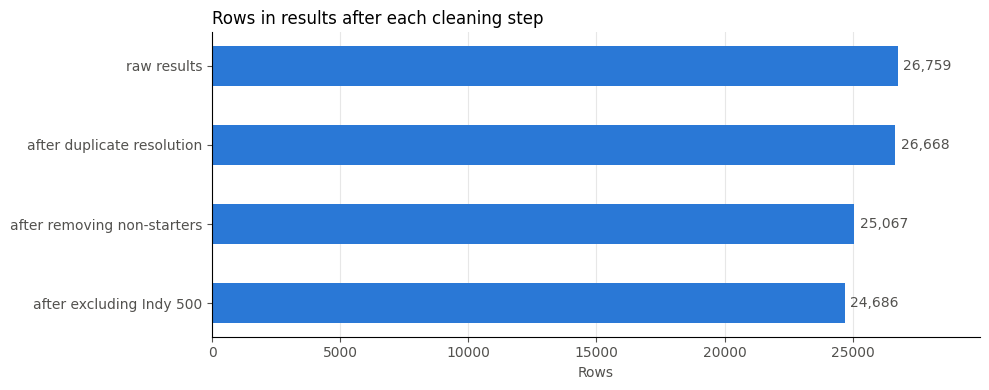

Rows removed per step:
after duplicate resolution       91
after removing non-starters    1601
after excluding Indy 500        381


In [589]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(cleaning_log.index[::-1], cleaning_log.values[::-1], color=AFTER_COLOR, height=0.5)
ax.bar_label(bars, labels=[f"{v:,}" for v in cleaning_log.values[::-1]], padding=4, color=TEXT_COLOR)
style_axes(ax, 'Rows in results after each cleaning step', 'Rows', '')
ax.grid(axis='y', alpha=0)
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, cleaning_log.max() * 1.12)
plt.tight_layout()
plt.show()

steps = cleaning_log.diff().dropna().astype(int)
print("Rows removed per step:")
print((-steps).to_string())

**Missing values before vs. after.** Cleaning should not create new gaps; columns that stay incomplete are the post-race ones explained in 4.9.9.

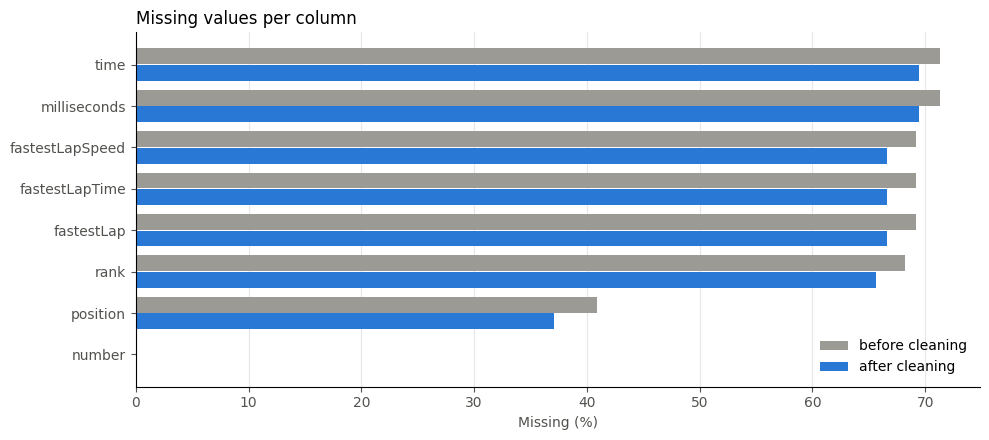

,before,after
number,0.02,0.00
position,40.93,37.07
rank,68.20,65.61
fastestLap,69.16,66.59
fastestLapTime,69.16,66.59
fastestLapSpeed,69.16,66.59
milliseconds,71.30,69.43
time,71.30,69.43


In [590]:
missing_after_pct = (results_clean.drop(columns=['time_seconds', 'fastestLapTime_seconds', 'podium'])
                     .isna().mean() * 100)
missing_compare = pd.DataFrame({
    'before': missing_before.reindex(missing_after_pct.index).fillna(0),
    'after': missing_after_pct
})
missing_compare = missing_compare[(missing_compare > 0).any(axis=1)].sort_values('before')

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(missing_compare))
ax.barh(y + 0.2, missing_compare['before'], height=0.38, color=BEFORE_COLOR, label='before cleaning')
ax.barh(y - 0.2, missing_compare['after'], height=0.38, color=AFTER_COLOR, label='after cleaning')
ax.set_yticks(y, missing_compare.index)
style_axes(ax, 'Missing values per column', 'Missing (%)', '')
ax.grid(axis='y', alpha=0)
ax.grid(axis='x', alpha=0.3)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

display(missing_compare.round(2))

**Podium class balance.** The target is imbalanced, which is why PR-AUC and F1 are reported alongside ROC-AUC later; removing non-starters raises the podium share because they could never finish on the podium.

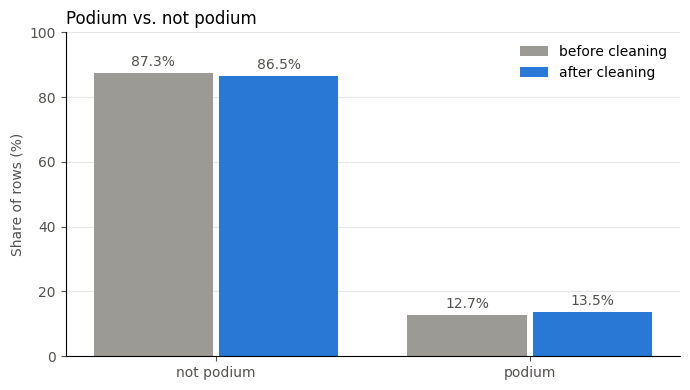

,before cleaning,after cleaning
not podium,87.31,86.45
podium,12.69,13.55


In [591]:
balance = pd.DataFrame({
    'before cleaning': results_before['is_podium'].value_counts(normalize=True) * 100,
    'after cleaning': results_clean['podium'].astype(bool).value_counts(normalize=True) * 100
}).rename(index={False: 'not podium', True: 'podium'}).loc[['not podium', 'podium']]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(balance.index))
b1 = ax.bar(x - 0.2, balance['before cleaning'], width=0.38, color=BEFORE_COLOR, label='before cleaning')
b2 = ax.bar(x + 0.2, balance['after cleaning'], width=0.38, color=AFTER_COLOR, label='after cleaning')
ax.bar_label(b1, fmt='%.1f%%', padding=3, color=TEXT_COLOR)
ax.bar_label(b2, fmt='%.1f%%', padding=3, color=TEXT_COLOR)
ax.set_xticks(x, balance.index)
style_axes(ax, 'Podium vs. not podium', '', 'Share of rows (%)')
ax.set_ylim(0, 100)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

display(balance.round(2))

**Podium rate and field size per season.** The podium rate is roughly 3 divided by the field size, so seasons with large fields (many entries, including non-starters) have a lower rate; cleaning removes entries that never raced and makes seasons more comparable.

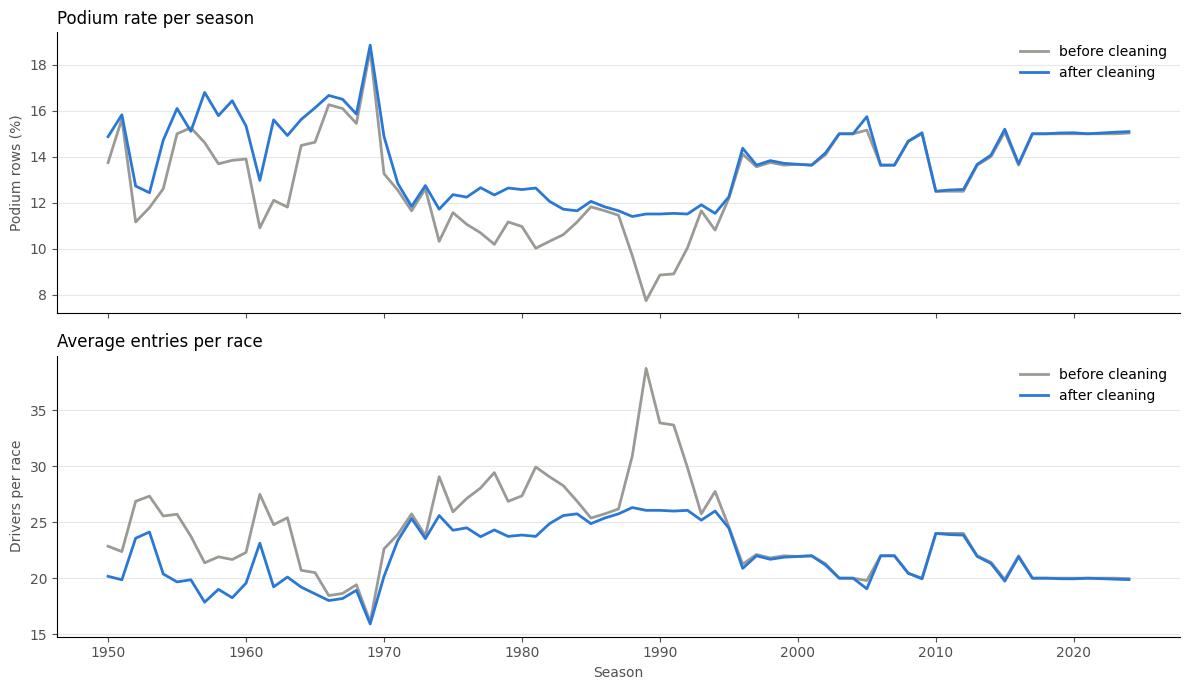

Largest drop in average field size:
year
1989    12.7
1990     7.8
1991     7.7
1981     6.2
1955     6.0


In [592]:
podium_rate_after = (results_after.groupby('year')['podium'].mean() * 100)

field_before = results_before.groupby(['year', 'raceId']).size().groupby('year').mean()
field_after = results_after.groupby(['year', 'raceId']).size().groupby('year').mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(podium_rate_before.index, podium_rate_before.values, color=BEFORE_COLOR, lw=2, label='before cleaning')
axes[0].plot(podium_rate_after.index, podium_rate_after.values, color=AFTER_COLOR, lw=2, label='after cleaning')
style_axes(axes[0], 'Podium rate per season', '', 'Podium rows (%)')
axes[0].legend(frameon=False)

axes[1].plot(field_before.index, field_before.values, color=BEFORE_COLOR, lw=2, label='before cleaning')
axes[1].plot(field_after.index, field_after.values, color=AFTER_COLOR, lw=2, label='after cleaning')
style_axes(axes[1], 'Average entries per race', 'Season', 'Drivers per race')
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print("Largest drop in average field size:")
print((field_before - field_after).sort_values(ascending=False).head(5).round(1).to_string())

**Podium probability by grid position (after cleaning).** The first look at the main pre-race signal: if starting position strongly predicts the podium, grid is a key feature. Grid 0 (no starting slot recorded, often a pit-lane start) is shown separately because 0 does not mean "ahead of pole".

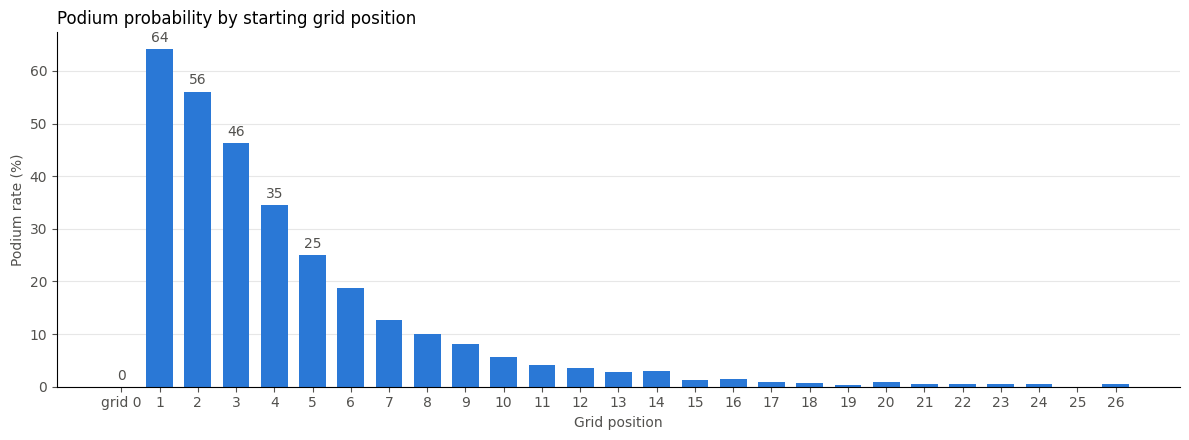

,podium %,starts
grid,,
0,0.0,130
1,64.1,1115
2,56.1,1109
3,46.3,1113
4,34.6,1117
5,25.0,1113
6,18.7,1107
7,12.7,1110
8,9.9,1106


In [593]:
by_grid = results_clean.groupby('grid')['podium'].agg(['mean', 'size'])
by_grid = by_grid[by_grid['size'] >= 30]   # skip grid slots with too few starts to be reliable
by_grid['mean'] = by_grid['mean'] * 100

labels = ['grid 0' if g == 0 else str(g) for g in by_grid.index]
colors = [BEFORE_COLOR if g == 0 else AFTER_COLOR for g in by_grid.index]

fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.bar(labels, by_grid['mean'], color=colors, width=0.7)
ax.bar_label(bars, labels=[f"{v:.0f}" if i < 6 else "" for i, v in enumerate(by_grid['mean'])],
             padding=3, color=TEXT_COLOR)
style_axes(ax, 'Podium probability by starting grid position', 'Grid position', 'Podium rate (%)')
plt.tight_layout()
plt.show()

display(by_grid.head(10).round(1).rename(columns={'mean': 'podium %', 'size': 'starts'}))

### 4.10 constructor_results_clean: `status` column

In [594]:
# Display the first 10 rows
display(constructor_results.head(10))

# Check number of rows and columns
print("Dataset shape:", constructor_results.shape)

# Display column names
print("\nColumn names:")
print(constructor_results.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
constructor_results.info()


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN
5,6,18,6,1.0,NaN
6,7,18,7,0.0,NaN
7,8,18,8,0.0,NaN
8,9,18,9,0.0,NaN
9,10,18,10,0.0,NaN


Dataset shape: (12625, 5)

Column names:
['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [595]:
# Show frequency of each status value
print("Status value distribution:")
print(
    constructor_results['status']
    .value_counts(dropna=False)
)

# Display rows with available status
print("\nRecords with non-missing status:")

display(
    constructor_results[
        constructor_results['status'].notna()
    ]
)


Status value distribution:
status
NaN    12608
D         17
Name: count, dtype: int64

Records with non-missing status:


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


In [596]:
# Verify which constructor and season have status = D
status_details = (
    constructor_results[
        constructor_results['status'].notna()
    ]
    .merge(
        constructors[['constructorId', 'name']],
        on='constructorId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        races[['raceId', 'year']],
        on='raceId',
        how='left',
        validate='many_to_one'
    )
)

display(
    status_details[
        ['year', 'name', 'raceId', 'points', 'status']
    ]
)

# Drop the mostly-empty status column
constructor_results_clean = (
    constructor_results_clean.drop(columns=['status'])
)

print("Original shape:", constructor_results.shape)
print("Cleaned shape:", constructor_results_clean.shape)
print("Remaining missing values:")
print(constructor_results_clean.isna().sum())

assert len(constructor_results_clean) == len(constructor_results)


,year,name,raceId,points,status
0,2007,McLaren,36,14.0,D
1,2007,McLaren,37,18.0,D
2,2007,McLaren,38,12.0,D
3,2007,McLaren,39,14.0,D
4,2007,McLaren,40,18.0,D
5,2007,McLaren,41,12.0,D
6,2007,McLaren,42,18.0,D
7,2007,McLaren,43,8.0,D
8,2007,McLaren,44,14.0,D
9,2007,McLaren,45,10.0,D


Original shape: (12625, 5)
Cleaned shape: (12625, 4)
Remaining missing values:
constructorResultsId    0
raceId                  0
constructorId           0
points                  0
dtype: int64


### 4.11 drivers_clean: missing codes and duplicate names

In [597]:
# Display missing counts
print("Missing driver numbers:",
      drivers['number'].isna().sum())

print("Missing driver codes:",
      drivers['code'].isna().sum())

# Inspect examples
display(
    drivers[
        drivers['number'].isna() |
        drivers['code'].isna()
    ][
        ['driverId', 'forename', 'surname',
         'number', 'code']
    ].head(20)
)

# Check whether stable driver IDs are complete
print(
    "Missing driver IDs:",
    drivers['driverId'].isna().sum()
)

print(
    "Duplicate driver IDs:",
    drivers['driverId'].duplicated().sum()
)


Missing driver numbers: 802
Missing driver codes: 757


,driverId,forename,surname,number,code
1,2,Nick,Heidfeld,NaN,HEI
4,5,Heikki,Kovalainen,NaN,KOV
5,6,Kazuki,Nakajima,NaN,NAK
6,7,Sébastien,Bourdais,NaN,BOU
9,10,Timo,Glock,NaN,GLO
10,11,Takuma,Sato,NaN,SAT
11,12,Nelson,Piquet Jr.,NaN,PIQ
13,14,David,Coulthard,NaN,COU
14,15,Jarno,Trulli,NaN,TRU
16,17,Mark,Webber,NaN,WEB


Missing driver IDs: 0
Duplicate driver IDs: 0


**Decision: missing `drivers.number` is not filled.**
- `drivers.number` is the driver's permanent racing number, introduced in 2014, so most earlier drivers never had one; it is structurally missing (802 rows), not an error.
- The car number a driver used in each race is stored per race in `results.number` (and `qualifying.number`), so that is the column we rely on; `drivers.number` is not used as a feature.

In [598]:
# 1. Check completely identical rows
print("Exact duplicate rows:", drivers.duplicated().sum())

# 2. Check duplicate driver IDs (primary key)
print(
    "Duplicate driver IDs:",
    drivers.duplicated(subset=['driverId']).sum()
)

# 3. Check drivers with identical first and last names
print(
    "Duplicate full names:",
    drivers.duplicated(
        subset=['forename', 'surname']
    ).sum()
)

# 4. Display all records sharing the same full name
duplicate_names = drivers[
    drivers.duplicated(
        subset=['forename', 'surname'],
        keep=False
    )
].sort_values(['forename', 'surname'])

display(
    duplicate_names[
        ['driverId', 'forename', 'surname',
         'dob', 'nationality', 'number', 'code']
    ]
)


Exact duplicate rows: 0
Duplicate driver IDs: 0
Duplicate full names: 0


,driverId,forename,surname,dob,nationality,number,code


In [599]:

# Work only with drivers whose official code is available
code_check = drivers[
    drivers['code'].notna()
].copy()

# Generate the first three letters of each surname
code_check['generated_code'] = (
    code_check['surname']
    .str[:3]
    .str.upper()
)

# Compare generated codes with recorded codes
code_check['code_matches'] = (
    code_check['generated_code'] == code_check['code']
)

print("Drivers with recorded codes:", len(code_check))

print(
    "Matching codes:",
    code_check['code_matches'].sum()
)

print(
    "Mismatching codes:",
    (~code_check['code_matches']).sum()
)

print(
    "Match percentage:",
    round(code_check['code_matches'].mean() * 100, 2),
    "%"
)

# Display exceptions
display(
    code_check.loc[
        ~code_check['code_matches'],
        ['driverId', 'forename', 'surname',
         'code', 'generated_code']
    ]
)


Drivers with recorded codes: 104
Matching codes: 89
Mismatching codes: 15
Match percentage: 85.58 %


,driverId,forename,surname,code,generated_code
7,8,Kimi,Räikkönen,RAI,RÄI
29,30,Michael,Schumacher,MSC,SCH
30,31,Juan,Pablo Montoya,MON,PAB
32,33,Tiago,Monteiro,TMO,MON
35,36,Franck,Montagny,FMO,MON
36,37,Pedro,de la Rosa,DLR,DE
807,807,Nico,Hülkenberg,HUL,HÜL
809,810,Lucas,di Grassi,DIG,DI
813,814,Paul,di Resta,DIR,DI
814,815,Sergio,Pérez,PER,PÉR


In [600]:
# Generate a three-letter surname abbreviation
generated_codes = (
    drivers_clean['surname']
    .str[:3]
    .str.upper()
)

# Track whether each code was generated
drivers_clean['code_was_generated'] = (
    drivers_clean['code'].isna()
)

# Fill only missing codes
drivers_clean['code_filled'] = (
    drivers_clean['code'].fillna(generated_codes)
)

# Verify that existing official codes were not changed
assert (
    drivers_clean.loc[
        drivers_clean['code'].notna(), 'code'
    ].equals(
        drivers_clean.loc[
            drivers_clean['code'].notna(), 'code_filled'
        ]
    )
)

print(
    "Existing codes preserved:",
    drivers_clean['code'].notna().sum()
)

print(
    "Generated abbreviations:",
    drivers_clean['code_was_generated'].sum()
)

print(
    "Remaining missing abbreviations:",
    drivers_clean['code_filled'].isna().sum()
)


Existing codes preserved: 104
Generated abbreviations: 757
Remaining missing abbreviations: 0


In [601]:

# Check final table structure
print("Original shape:", drivers.shape)
print("Cleaned shape:", drivers_clean.shape)

# Verify unique and complete IDs
print("\nMissing driver IDs:",
      drivers_clean['driverId'].isna().sum())

print("Duplicate driver IDs:",
      drivers_clean['driverId'].duplicated().sum())

print("Exact duplicate rows:",
      drivers_clean.duplicated().sum())

# Verify generated code column
print("\nMissing original codes:",
      drivers_clean['code'].isna().sum())

print("Missing completed codes:",
      drivers_clean['code_filled'].isna().sum())

print("Generated abbreviations:",
      drivers_clean['code_was_generated'].sum())

# Check that existing codes were preserved
existing = drivers_clean['code'].notna()

print(
    "Existing codes changed:",
    (
        drivers_clean.loc[existing, 'code'] !=
        drivers_clean.loc[existing, 'code_filled']
    ).sum()
)

# Check remaining missing values
print("\nRemaining missing values:")
print(drivers_clean.isna().sum())

# Assertions
assert len(drivers_clean) == len(drivers)
assert drivers_clean['driverId'].is_unique
assert drivers_clean['driverId'].notna().all()
assert drivers_clean['code_filled'].notna().all()

print("\nDriver cleaning validation passed!")


Original shape: (861, 9)
Cleaned shape: (861, 11)

Missing driver IDs: 0
Duplicate driver IDs: 0
Exact duplicate rows: 0

Missing original codes: 757
Missing completed codes: 0
Generated abbreviations: 757
Existing codes changed: 0

Remaining missing values:
driverId                0
driverRef               0
number                802
code                  757
forename                0
surname                 0
dob                     0
nationality             0
url                     0
code_was_generated      0
code_filled             0
dtype: int64

Driver cleaning validation passed!


#### 4.11.1 Date of birth to datetime
Semantic typing of `dob`; needed later to compute driver age at each race.

In [602]:
# Record original non-missing count
original_dob_count = drivers_clean['dob'].notna().sum()

# Convert date of birth to datetime
drivers_clean['dob'] = pd.to_datetime(
    drivers_clean['dob'],
    errors='coerce'
)

print("dob type:", drivers_clean['dob'].dtype)
print("Non-missing before:", original_dob_count)
print("Non-missing after:", drivers_clean['dob'].notna().sum())
print("Earliest dob:", drivers_clean['dob'].min())
print("Latest dob:", drivers_clean['dob'].max())

# No valid dates may be lost in the conversion
assert drivers_clean['dob'].notna().sum() == original_dob_count

dob type: datetime64[ns]
Non-missing before: 861
Non-missing after: 861
Earliest dob: 1896-12-28 00:00:00
Latest dob: 2005-05-08 00:00:00


#### 4.11.2 Nationality to home country
Q2 compares a driver's nationality with the circuit's country, so each nationality is mapped to a country name written the same way as `circuits.country`.
Drivers with two nationalities (e.g. American-Italian) also get a second country in `home_country_2`, so a race in either country counts as a home race; for everyone else `home_country_2` is NaN, meaning "no second nationality".
Two spelling fixes make the tables match: stray whitespace is stripped from `nationality`, and `circuits.country` 'United States' is standardised to 'USA'.

In [603]:
# Nationalities present in the data
print(sorted(drivers_clean['nationality'].unique()))

['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']


In [604]:
# Map each nationality to a country, using circuits.country naming (e.g. 'UK', 'USA')
nationality_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentinian': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hong Kong': 'Hong Kong',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}

# Remove stray whitespace (e.g. 'Argentinian ' in the raw data)
print("Nationalities with extra whitespace:",
      (drivers_clean['nationality'] != drivers_clean['nationality'].str.strip()).sum())
drivers_clean['nationality'] = drivers_clean['nationality'].str.strip()

# circuits.country uses both 'USA' and 'United States'; standardise to 'USA'
print("Circuits spelled 'United States':",
      (circuits_clean['country'] == 'United States').sum())
circuits_clean['country'] = circuits_clean['country'].replace(
    {'United States': 'USA'}
)

drivers_clean['home_country'] = (
    drivers_clean['nationality'].map(nationality_to_country)
)

# Second country for dual nationalities only; NaN for everyone else
second_country = {
    'American-Italian': 'Italy',
    'Argentine-Italian': 'Italy'
}

drivers_clean['home_country_2'] = (
    drivers_clean['nationality'].map(second_country)
)

print("Drivers with a second home country:",
      drivers_clean['home_country_2'].notna().sum())

# Nationalities not covered by the mapping (should be empty)
unmapped = drivers_clean.loc[
    drivers_clean['home_country'].isna(), 'nationality'
].unique()
print("Unmapped nationalities:", list(unmapped))

# Circuit countries that no driver nationality maps to (no home driver from that country)
circuit_countries = set(circuits_clean['country'].unique())
print("Circuit countries with no matching nationality:",
      sorted(circuit_countries - set(nationality_to_country.values())))

print("Drivers whose home country hosts a circuit:",
      drivers_clean['home_country'].isin(circuit_countries).sum(),
      "of", len(drivers_clean))

Nationalities with extra whitespace: 1
Circuits spelled 'United States': 1
Drivers with a second home country: 2
Unmapped nationalities: []
Circuit countries with no matching nationality: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']
Drivers whose home country hosts a circuit: 811 of 861


### 4.12 sprint_results_clean: overview and grain
Sprints are short Saturday races held at some weekends since 2021; the table must have one row per driver per sprint, like results.

In [605]:
print("Original shape:", sprint_results.shape)
print("Working shape:", sprint_results_clean.shape)

print("\nColumn names:")
print(sprint_results_clean.columns.tolist())

print("\nData types:")
print(sprint_results_clean.dtypes)

print("\nFirst 10 records:")
display(sprint_results_clean.head(10))

print("\nSummary statistics:")
display(sprint_results_clean.describe(include='all'))

Original shape: (360, 16)
Working shape: (360, 16)

Column names:
['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'fastestLapTime', 'statusId']

Data types:
resultId            int64
raceId              int64
driverId            int64
constructorId       int64
number              int64
grid                int64
position          float64
positionText       object
positionOrder       int64
points              int64
laps                int64
time               object
milliseconds      float64
fastestLap        float64
fastestLapTime     object
statusId            int64
dtype: object

First 10 records:


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1
5,6,1061,817,1,3,7,6.0,6,6,0,17,+30.959,1569385.0,17.0,1:30.640,1
6,7,1061,4,214,14,11,7.0,7,7,0,17,+43.527,1581953.0,17.0,1:31.773,1
7,8,1061,20,117,5,10,8.0,8,8,0,17,+44.439,1582865.0,17.0,1:31.687,1
8,9,1061,847,3,63,8,9.0,9,9,0,17,+46.652,1585078.0,17.0,1:32.208,1
9,10,1061,839,214,31,13,10.0,10,10,0,17,+47.395,1585821.0,16.0,1:32.183,1



Summary statistics:


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
count,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,345.000000,360,360.000000,360.000000,360.000000,340,3.400000e+02,351.000000,351,360.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23,NaN,NaN,NaN,340,NaN,NaN,350,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,+1:14.371,NaN,NaN,1:28.717,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18,NaN,NaN,NaN,1,NaN,NaN,2,NaN
mean,180.500000,1106.944444,734.658333,94.366667,28.177778,9.922222,10.121739,NaN,10.500000,1.550000,19.583333,NaN,1.806263e+06,10.638177,NaN,3.336111
std,104.067286,25.636134,276.412115,89.166421,23.796293,5.842363,5.593520,NaN,5.774307,2.496293,4.752803,NaN,1.549986e+05,6.267159,NaN,13.447963
min,1.000000,1061.000000,1.000000,1.000000,1.000000,0.000000,1.000000,NaN,1.000000,0.000000,0.000000,NaN,1.498433e+06,2.000000,NaN,1.000000
25%,90.750000,1084.000000,822.000000,6.000000,11.000000,5.000000,5.000000,NaN,5.750000,0.000000,18.000000,NaN,1.649334e+06,5.000000,NaN,1.000000
50%,180.500000,1112.500000,840.000000,84.000000,22.000000,10.000000,10.000000,NaN,10.500000,0.000000,19.000000,NaN,1.842414e+06,9.000000,NaN,1.000000
75%,270.250000,1126.000000,848.000000,210.000000,44.000000,15.000000,15.000000,NaN,15.250000,3.000000,24.000000,NaN,1.909140e+06,17.000000,NaN,1.000000


In [606]:
print("Exact duplicate rows:",
      sprint_results_clean.duplicated().sum())

print("Missing result IDs:",
      sprint_results_clean['resultId'].isna().sum())

print("Duplicate result IDs:",
      sprint_results_clean['resultId'].duplicated().sum())

print("Duplicate race-driver combinations:",
      sprint_results_clean.duplicated(
          subset=['raceId', 'driverId']
      ).sum())

# Investigate duplicated driver-race combinations
duplicate_sprints = sprint_results_clean[
    sprint_results_clean.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].sort_values(['raceId', 'driverId'])

display(duplicate_sprints)

# Grain: one row per driver per sprint
assert not sprint_results_clean.duplicated(
    subset=['raceId', 'driverId']
).any()

Exact duplicate rows: 0
Missing result IDs: 0
Duplicate result IDs: 0
Duplicate race-driver combinations: 0


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId


#### 4.12.1 Missing values
Joining races, drivers, constructors and status shows who the rows with missing values are and why they are missing.

In [607]:
missing = sprint_results_clean.isna().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': (
        missing / len(sprint_results_clean) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report['Missing Count'] > 0
    ].sort_values(
        'Missing Count',
        ascending=False
    )
)

,Missing Count,Missing %
time,20,5.56
milliseconds,20,5.56
position,15,4.17
fastestLap,9,2.50
fastestLapTime,9,2.50


In [608]:
sprint_inspection = (
    sprint_results_clean
    .merge(
        races_clean[
            ['raceId', 'year', 'round', 'name']
        ],
        on='raceId',
        how='left'
    )
    .merge(
        drivers_clean[
            ['driverId', 'forename', 'surname']
        ],
        on='driverId',
        how='left'
    )
    .merge(
        constructors_clean[
            ['constructorId', 'name']
        ],
        on='constructorId',
        how='left',
        suffixes=('_race', '_constructor')
    )
)

display(
    sprint_inspection[
        [
            'year', 'round', 'name_race',
            'forename', 'surname', 'name_constructor',
            'grid', 'position', 'positionOrder',
            'points', 'laps', 'time', 'milliseconds',
            'fastestLap', 'fastestLapTime'
        ]
    ].head(20)
)

print(
    "Original sprint records:",
    len(sprint_results_clean)
)

print(
    "Records after inspection joins:",
    len(sprint_inspection)
)

,year,round,name_race,forename,surname,name_constructor,grid,position,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime
0,2021,10,British Grand Prix,Max,Verstappen,Red Bull,2,1.0,1,3,17,25:38.426,1538426.0,14.0,1:30.013
1,2021,10,British Grand Prix,Lewis,Hamilton,Mercedes,1,2.0,2,2,17,+1.430,1539856.0,17.0,1:29.937
2,2021,10,British Grand Prix,Valtteri,Bottas,Mercedes,3,3.0,3,1,17,+7.502,1545928.0,17.0,1:29.958
3,2021,10,British Grand Prix,Charles,Leclerc,Ferrari,4,4.0,4,0,17,+11.278,1549704.0,16.0,1:30.163
4,2021,10,British Grand Prix,Lando,Norris,McLaren,6,5.0,5,0,17,+24.111,1562537.0,16.0,1:30.566
5,2021,10,British Grand Prix,Daniel,Ricciardo,McLaren,7,6.0,6,0,17,+30.959,1569385.0,17.0,1:30.640
6,2021,10,British Grand Prix,Fernando,Alonso,Alpine F1 Team,11,7.0,7,0,17,+43.527,1581953.0,17.0,1:31.773
7,2021,10,British Grand Prix,Sebastian,Vettel,Aston Martin,10,8.0,8,0,17,+44.439,1582865.0,17.0,1:31.687
8,2021,10,British Grand Prix,George,Russell,Williams,8,9.0,9,0,17,+46.652,1585078.0,17.0,1:32.208
9,2021,10,British Grand Prix,Esteban,Ocon,Alpine F1 Team,13,10.0,10,0,17,+47.395,1585821.0,16.0,1:32.183


Original sprint records: 360
Records after inspection joins: 360


In [609]:
# Join sprint results with their own recorded statuses
sprint_missing_inspection = sprint_inspection.merge(
    status_clean[['statusId', 'status']],
    on='statusId',
    how='left'
)

missing_columns = [
    'position',
    'time',
    'milliseconds',
    'fastestLap',
    'fastestLapTime'
]

# Select records missing at least one relevant value
missing_sprint_records = sprint_missing_inspection[
    sprint_missing_inspection[missing_columns]
    .isna().any(axis=1)
]

print(
    "Sprint records with at least one missing value:",
    len(missing_sprint_records)
)

display(
    missing_sprint_records[
        [
            'year', 'name_race',
            'forename', 'surname',
            'grid', 'position', 'positionText',
            'positionOrder', 'laps',
            'time', 'milliseconds',
            'fastestLap', 'fastestLapTime',
            'status'
        ]
    ].sort_values(['year', 'name_race', 'positionOrder'])
)

Sprint records with at least one missing value: 20


,year,name_race,forename,surname,grid,position,positionText,positionOrder,laps,time,milliseconds,fastestLap,fastestLapTime,status
19,2021,British Grand Prix,Sergio,Pérez,5,NaN,R,20,16,NaN,NaN,6.0,1:31.465,Vibrations
39,2021,Italian Grand Prix,Pierre,Gasly,6,NaN,R,20,0,NaN,NaN,NaN,NaN,Accident
98,2022,Austrian Grand Prix,Sebastian,Vettel,20,19.0,19,19,21,NaN,NaN,4.0,1:10.317,Collision damage
99,2022,Austrian Grand Prix,Fernando,Alonso,8,NaN,N,20,0,NaN,NaN,NaN,NaN,Electrical
79,2022,Emilia Romagna Grand Prix,Guanyu,Zhou,0,NaN,R,20,0,NaN,NaN,NaN,NaN,Retired
119,2022,São Paulo Grand Prix,Alexander,Albon,11,NaN,R,20,12,NaN,NaN,4.0,1:15.998,Retired
138,2023,Azerbaijan Grand Prix,Yuki,Tsunoda,16,NaN,R,19,2,NaN,NaN,NaN,NaN,Collision damage
139,2023,Azerbaijan Grand Prix,Logan,Sargeant,0,NaN,W,20,0,NaN,NaN,NaN,NaN,Accident
178,2023,Belgian Grand Prix,Sergio,Pérez,8,NaN,R,19,8,NaN,NaN,2.0,2:02.516,Collision damage
179,2023,Belgian Grand Prix,Fernando,Alonso,15,NaN,R,20,2,NaN,NaN,NaN,NaN,Accident


In [610]:
print("Missing position AND milliseconds:",
      (
          sprint_results_clean['position'].isna()
          & sprint_results_clean['milliseconds'].isna()
      ).sum())

print("Missing milliseconds but position available:",
      (
          sprint_results_clean['milliseconds'].isna()
          & sprint_results_clean['position'].notna()
      ).sum())

print("Missing fastest lap AND fastest lap time:",
      (
          sprint_results_clean['fastestLap'].isna()
          & sprint_results_clean['fastestLapTime'].isna()
      ).sum())

print("Missing fastest lap time but lap number available:",
      (
          sprint_results_clean['fastestLapTime'].isna()
          & sprint_results_clean['fastestLap'].notna()
      ).sum())

print("\nSprint status distribution:")
display(
    sprint_missing_inspection['status']
    .value_counts(dropna=False)
)

Missing position AND milliseconds: 15
Missing milliseconds but position available: 5
Missing fastest lap AND fastest lap time: 9
Missing fastest lap time but lap number available: 0

Sprint status distribution:


status
Finished            340
Retired              10
Accident              3
Collision damage      3
Vibrations            1
Electrical            1
Brakes                1
Exhaust               1
Name: count, dtype: int64

**Decision: sprint NaNs are kept, not filled.**
- The status table above shows which drivers the missing position, time and fastest-lap values belong to (retired, lapped or not classified); these values do not exist, so filling them would invent results.
- These columns describe the sprint's outcome, so they stay as NaN and are not used as raw features.

#### 4.12.2 Durations to seconds
`time` only stores gaps such as "+1.234" for non-winners, so total sprint time is taken from `milliseconds`; `fastestLapTime` ("1:30.123") is parsed like qualifying times.

In [611]:
# 1. Convert total elapsed sprint time to seconds
sprint_results_clean['total_time_seconds'] = (
    sprint_results_clean['milliseconds'] / 1000
)

# 2. Convert fastest lap time to seconds
sprint_results_clean['fastestLapTime_seconds'] = (
    pd.to_timedelta(
        '00:' + sprint_results_clean[
            'fastestLapTime'
        ].dropna().astype(str),
        errors='coerce'
    ).dt.total_seconds()
)

# 3. Validate the conversions
print("Total time values before:",
      sprint_results_clean['milliseconds'].notna().sum())

print("Total time values after:",
      sprint_results_clean['total_time_seconds'].notna().sum())

print("\nFastest lap values before:",
      sprint_results_clean['fastestLapTime'].notna().sum())

print("Fastest lap values after:",
      sprint_results_clean['fastestLapTime_seconds'].notna().sum())

print("\nSample records:")
display(
    sprint_results_clean[
        [
            'time', 'milliseconds',
            'total_time_seconds',
            'fastestLapTime',
            'fastestLapTime_seconds'
        ]
    ].head(10)
)

Total time values before: 340
Total time values after: 340

Fastest lap values before: 351
Fastest lap values after: 351

Sample records:


,time,milliseconds,total_time_seconds,fastestLapTime,fastestLapTime_seconds
0,25:38.426,1538426.0,1538.426,1:30.013,90.013
1,+1.430,1539856.0,1539.856,1:29.937,89.937
2,+7.502,1545928.0,1545.928,1:29.958,89.958
3,+11.278,1549704.0,1549.704,1:30.163,90.163
4,+24.111,1562537.0,1562.537,1:30.566,90.566
5,+30.959,1569385.0,1569.385,1:30.640,90.640
6,+43.527,1581953.0,1581.953,1:31.773,91.773
7,+44.439,1582865.0,1582.865,1:31.687,91.687
8,+46.652,1585078.0,1585.078,1:32.208,92.208
9,+47.395,1585821.0,1585.821,1:32.183,92.183


#### 4.12.3 Validate sprint_results_clean

In [612]:
print("Original records:", len(sprint_results))
print("Cleaned records:", len(sprint_results_clean))

print("\nExact duplicate rows:",
      sprint_results_clean.duplicated().sum())

print("Duplicate result IDs:",
      sprint_results_clean['resultId'].duplicated().sum())

print("Duplicate race-driver pairs:",
      sprint_results_clean.duplicated(
          ['raceId', 'driverId']
      ).sum())

print("\nRemaining missing values:")
print(
    sprint_results_clean[
        ['position',
         'time', 'milliseconds',
         'total_time_seconds',
         'fastestLap', 'fastestLapTime',
         'fastestLapTime_seconds']
    ].isna().sum()
)

# Integrity assertions
assert len(sprint_results_clean) == len(sprint_results)
assert sprint_results_clean['resultId'].is_unique
assert not sprint_results_clean.duplicated(
    ['raceId', 'driverId']
).any()

assert (
    sprint_results_clean['milliseconds'].notna().sum()
    == sprint_results_clean['total_time_seconds'].notna().sum()
)

assert (
    sprint_results_clean['fastestLapTime'].notna().sum()
    == sprint_results_clean['fastestLapTime_seconds'].notna().sum()
)

print("\nSprint results validation passed!")
print(sprint_results_clean.shape)

Original records: 360
Cleaned records: 360

Exact duplicate rows: 0
Duplicate result IDs: 0
Duplicate race-driver pairs: 0

Remaining missing values:
position                  15
time                      20
milliseconds              20
total_time_seconds        20
fastestLap                 9
fastestLapTime             9
fastestLapTime_seconds     9
dtype: int64

Sprint results validation passed!
(360, 18)


### 4.13 driver_standings_clean and constructor_standings_clean
Standings are the championship table **after** each race, so they are post-race information: features must use the previous race's standings (Section 5). Here we only check their integrity.

In [613]:
standings_tables = [
    ('driver_standings', driver_standings, driver_standings_clean, 'driverId'),
    ('constructor_standings', constructor_standings, constructor_standings_clean, 'constructorId'),
]

for name, raw, df, key in standings_tables:
    print("Table:", name, "| shape:", df.shape)
    print("Duplicate (raceId, " + key + ") pairs:",
          df.duplicated(subset=['raceId', key]).sum())
    print("Negative points:", (df['points'] < 0).sum())
    print("Negative wins:", (df['wins'] < 0).sum())
    print("Position range:", df['position'].min(), "-", df['position'].max())

    # positionText values that are not plain numbers
    print("Non-numeric positionText values:")
    print(df.loc[~df['positionText'].astype(str).str.isdigit(), 'positionText'].value_counts())
    print("-" * 45)

    # Grain: one standings row per driver/constructor per race
    assert not df.duplicated(subset=['raceId', key]).any()
    assert len(df) == len(raw)

Table: driver_standings | shape: (34863, 7)
Duplicate (raceId, driverId) pairs: 0
Negative points: 0
Negative wins: 0
Position range: 1 - 108
Non-numeric positionText values:
positionText
D    1
Name: count, dtype: int64
---------------------------------------------
Table: constructor_standings | shape: (13391, 7)
Duplicate (raceId, constructorId) pairs: 0
Negative points: 0
Negative wins: 0
Position range: 1 - 22
Non-numeric positionText values:
positionText
E    17
Name: count, dtype: int64
---------------------------------------------


#### 4.13.1 Cumulative points never decrease within a season
Standings accumulate race by race, so points should only go up within a season; drops would mean mis-ordered races or corrections, which matters because form features will be shifted by race date.

In [614]:
race_dates = races_clean[['raceId', 'year', 'round', 'date']]

for name, raw, df, key in standings_tables:
    ordered = (
        df.merge(race_dates, on='raceId', how='left', validate='many_to_one')
        .sort_values([key, 'year', 'date'])
    )

    ordered['points_change'] = (
        ordered.groupby([key, 'year'])['points'].diff()
    )

    drops = ordered[ordered['points_change'] < 0]

    print(name, "- points decreases within a season:", len(drops))
    display(drops[['year', 'round', 'raceId', key, 'points', 'points_change']].head(10))

driver_standings - points decreases within a season: 0


,year,round,raceId,driverId,points,points_change


constructor_standings - points decreases within a season: 2


,year,round,raceId,constructorId,points,points_change
12021,2018,13,1001,10,18.0,-41.0
12360,2020,5,1035,211,41.0,-1.0


#### 4.13.2 Standings coverage vs. races
Pre-race standings features need a standings row for the previous race; races with results but no standings would leave those features missing.

In [615]:
# Compare with every race that has results in the dataset
results_races = set(results['raceId'])

for name, raw, df, key in standings_tables:
    standings_races = set(df['raceId'])

    missing_standings = races_clean[
        races_clean['raceId'].isin(results_races - standings_races)
    ]

    print(name)
    print("  Races with results but no standings:", len(missing_standings))
    print("  Races with standings but no results:", len(standings_races - results_races))

    if not missing_standings.empty:
        print("  Seasons affected:")
        print(missing_standings['year'].value_counts().sort_index().to_string())

driver_standings
  Races with results but no standings: 0
  Races with standings but no results: 0
constructor_standings
  Races with results but no standings: 64
  Races with standings but no results: 0
  Seasons affected:
year
1950    7
1951    8
1952    8
1953    9
1954    9
1955    7
1956    8
1957    8


**Decision: standings tables are kept unchanged.**
- No duplicate (raceId, driverId/constructorId) pairs and no negative points or wins.
- `positionText` 'D' (1 driver row) and 'E' (17 constructor rows) are official disqualification/exclusion entries; the 17 'E' rows match the 17 McLaren 2007 rows flagged in `constructor_results`.
- The 2 constructor points drops are real championship events (Force India's mid-2018 takeover reset its points; a 2020 points penalty), so they are not corrected.
- Constructor standings are missing for 64 races in 1950–1957 because the constructors' championship only started in 1958; these features will be NaN for those races.

### 4.14 seasons_clean: integrity checks
`seasons` lists one row per championship year (`year`, `url`); it has no date or time columns, so the checks are duplicates, missing values, type, year coverage and URL format.

In [616]:
print("Shape:", seasons_clean.shape)
print("\nData types:")
print(seasons_clean.dtypes)
display(seasons_clean.sort_values('year').head())

# Duplicates and missing values
print("\nExact duplicate rows:", seasons_clean.duplicated().sum())
print("Duplicate years:", seasons_clean['year'].duplicated().sum())
print("Duplicate URLs:", seasons_clean['url'].duplicated().sum())
print("Missing values:")
print(seasons_clean.isna().sum())

# year must be a whole number (it is the key that races.year points to)
print("\nyear is integer:", pd.api.types.is_integer_dtype(seasons_clean['year']))

Shape: (75, 2)

Data types:
year     int64
url     object
dtype: object


,year,url
60,1950,http://en.wikipedia.org/wiki/1950_Formula_One_...
59,1951,http://en.wikipedia.org/wiki/1951_Formula_One_...
58,1952,http://en.wikipedia.org/wiki/1952_Formula_One_...
57,1953,http://en.wikipedia.org/wiki/1953_Formula_One_...
56,1954,http://en.wikipedia.org/wiki/1954_Formula_One_...



Exact duplicate rows: 0
Duplicate years: 0
Duplicate URLs: 0
Missing values:
year    0
url     0
dtype: int64

year is integer: True


#### 4.14.1 Year coverage and consistency with races
Every season should be a consecutive year that has races, and every race year should exist in `seasons`.

In [617]:
season_years = set(seasons_clean['year'])
race_years = set(races_clean['year'])
full_range = set(range(seasons_clean['year'].min(), seasons_clean['year'].max() + 1))

print("Year range:", seasons_clean['year'].min(), "-", seasons_clean['year'].max())
print("Missing years inside the range:", sorted(full_range - season_years))
print("Seasons with no races:", sorted(season_years - race_years))
print("Race years missing from seasons:", sorted(race_years - season_years))

# Each URL should be a Wikipedia link that mentions its own year
url_has_year = seasons_clean.apply(lambda r: str(r['year']) in r['url'], axis=1)
url_is_link = seasons_clean['url'].str.startswith('http')
print("\nURLs that are not links:", (~url_is_link).sum())
print("URLs not containing their own year:", (~url_has_year).sum())
display(seasons_clean.loc[~url_has_year | ~url_is_link])

assert seasons_clean['year'].is_unique
assert seasons_clean['year'].notna().all()
assert len(seasons_clean) == len(seasons)

Year range: 1950 - 2024
Missing years inside the range: []
Seasons with no races: []
Race years missing from seasons: []

URLs that are not links: 0
URLs not containing their own year: 0


,year,url


**Decision: seasons is kept unchanged.**
- 75 rows covering every year from 1950 to 2024 with no gaps; no duplicate years, URLs or rows, and no missing values.
- `year` is already an integer and the table has no date or time columns, so no type conversion is needed.
- Every season has races and every race year exists in `seasons`; all URLs are links that contain their own year.

### 4.15 circuits_clean: integrity checks
`circuits` gives each track's name, location, country and coordinates; `country` is used in Q2, so its spelling matters (the 'United States' → 'USA' fix was applied in 4.11.2).

In [618]:
print("Shape:", circuits_clean.shape)
print("\nData types:")
print(circuits_clean.dtypes)
display(circuits_clean.head())

# Duplicates
print("\nExact duplicate rows:", circuits_clean.duplicated().sum())
for col in ['circuitId', 'circuitRef', 'name', 'url']:
    print(f"Duplicate {col}:", circuits_clean[col].duplicated().sum())
print("Duplicate (lat, lng) locations:",
      circuits_clean.duplicated(subset=['lat', 'lng']).sum())

# Missing values
print("\nMissing values:")
print(circuits_clean.isna().sum())

# Text columns with leading/trailing spaces
text_columns = ['circuitRef', 'name', 'location', 'country', 'url']
print("\nValues with extra whitespace:")
for col in text_columns:
    values = circuits_clean[col].astype(str)
    print(f"  {col}:", (values != values.str.strip()).sum())

Shape: (77, 9)

Data types:
circuitId       int64
circuitRef     object
name           object
location       object
country        object
lat           float64
lng           float64
alt             int64
url            object
dtype: object


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park



Exact duplicate rows: 0
Duplicate circuitId: 0
Duplicate circuitRef: 0
Duplicate name: 0
Duplicate url: 0
Duplicate (lat, lng) locations: 0

Missing values:
circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64

Values with extra whitespace:
  circuitRef: 0
  name: 0
  location: 0
  country: 0
  url: 0


#### 4.15.1 Coordinates, altitude and country values
Coordinates must be valid latitude/longitude, altitude must be numeric and plausible, and each country should be spelled one way only.

In [619]:
print("Latitude out of [-90, 90]:",
      (~circuits_clean['lat'].between(-90, 90)).sum())
print("Longitude out of [-180, 180]:",
      (~circuits_clean['lng'].between(-180, 180)).sum())

# Altitude: numeric type and plausible range
alt_numeric = pd.to_numeric(circuits_clean['alt'], errors='coerce')
print("\nalt non-numeric values:",
      (alt_numeric.isna() & circuits_clean['alt'].notna()).sum())
print("alt range:", alt_numeric.min(), "-", alt_numeric.max())
display(circuits_clean.loc[alt_numeric.isin([alt_numeric.min(), alt_numeric.max()]),
                           ['name', 'country', 'alt']])

# Country spellings (variants of the same country show up here)
print("\nCountries:", circuits_clean['country'].nunique())
print(circuits_clean['country'].value_counts().sort_index().to_string())

# The 'United States' -> 'USA' fix from 4.11.2 must already be applied
assert 'United States' not in set(circuits_clean['country'])


Latitude out of [-90, 90]: 0
Longitude out of [-180, 180]: 0

alt non-numeric values: 0
alt range: -7 - 2227


,name,country,alt
31,Autódromo Hermanos Rodríguez,Mexico,2227
71,Baku City Circuit,Azerbaijan,-7



Countries: 34
country
Argentina        1
Australia        2
Austria          2
Azerbaijan       1
Bahrain          1
Belgium          3
Brazil           2
Canada           3
China            1
France           7
Germany          3
Hungary          1
India            1
Italy            4
Japan            3
Korea            1
Malaysia         1
Mexico           1
Monaco           1
Morocco          1
Netherlands      1
Portugal         4
Qatar            1
Russia           1
Saudi Arabia     1
Singapore        1
South Africa     2
Spain            6
Sweden           1
Switzerland      1
Turkey           1
UAE              1
UK               4
USA             12


#### 4.15.2 Circuits used by races

In [620]:
used_circuits = set(races_clean['circuitId'])
unused = circuits_clean[~circuits_clean['circuitId'].isin(used_circuits)]

print("Circuits never used in a race:", len(unused))
display(unused[['circuitId', 'name', 'country']])

print("Races pointing to a missing circuit:",
      (~races_clean['circuitId'].isin(circuits_clean['circuitId'])).sum())

assert circuits_clean['circuitId'].is_unique
assert len(circuits_clean) == len(circuits)

Circuits never used in a race: 0


,circuitId,name,country


Races pointing to a missing circuit: 0


**Decision: circuits kept unchanged apart from the country spelling fix.**
- 77 circuits with no duplicate IDs, refs, names, URLs or coordinates, no missing values and no stray whitespace; every circuit hosted a race.
- Coordinates are valid and `alt` is numeric; its extremes are real (Baku −7 m, below sea level; Mexico City 2,227 m).
- The only spelling variant was 'United States' (1 circuit) next to 'USA' (11); it is standardised to 'USA' in 4.11.2 so Q2 counts all US races as one country.

### 4.16 constructors_clean: integrity checks
`constructors` names each team and its nationality; it is joined to results for Q3 and constructor features.

In [621]:
print("Shape:", constructors_clean.shape)
print("\nData types:")
print(constructors_clean.dtypes)
display(constructors_clean.head())

# Duplicates
print("\nExact duplicate rows:", constructors_clean.duplicated().sum())
for col in ['constructorId', 'constructorRef', 'name', 'url']:
    print(f"Duplicate {col}:", constructors_clean[col].duplicated().sum())

# Rows sharing a name (if any) are shown for inspection
display(
    constructors_clean[constructors_clean.duplicated(subset=['name'], keep=False)]
    .sort_values('name')
)

# Missing values
print("\nMissing values:")
print(constructors_clean.isna().sum())

# Text columns with leading/trailing spaces
print("\nValues with extra whitespace:")
for col in ['constructorRef', 'name', 'nationality', 'url']:
    values = constructors_clean[col].astype(str)
    print(f"  {col}:", (values != values.str.strip()).sum())

Shape: (212, 5)

Data types:
constructorId      int64
constructorRef    object
name              object
nationality       object
url               object
dtype: object


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso



Exact duplicate rows: 0
Duplicate constructorId: 0
Duplicate constructorRef: 0
Duplicate name: 0
Duplicate url: 37


,constructorId,constructorRef,name,nationality,url



Missing values:
constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64

Values with extra whitespace:
  constructorRef: 0
  name: 0
  nationality: 0
  url: 0


Several constructors share a URL; listing them shows whether they are separate entities (e.g. chassis-engine pairings) or real duplicates.

In [622]:
# Constructors that share a Wikipedia URL: are they different entities?
shared_url = constructors_clean[
    constructors_clean.duplicated(subset=['url'], keep=False)
].sort_values(['url', 'name'])

print("Constructors sharing a URL:", len(shared_url),
      "| distinct URLs involved:", shared_url['url'].nunique())

with pd.option_context('display.max_rows', None, 'display.max_colwidth', 70):
    display(shared_url[['constructorId', 'constructorRef', 'name', 'nationality', 'url']])

Constructors sharing a URL: 50 | distinct URLs involved: 13


,constructorId,constructorRef,name,nationality,url
86,88,eagle,Eagle,American,http://en.wikipedia.org/wiki/Anglo_American_Racers
186,189,eagle-climax,Eagle-Climax,American,http://en.wikipedia.org/wiki/Anglo_American_Racers
187,190,eagle-weslake,Eagle-Weslake,American,http://en.wikipedia.org/wiki/Anglo_American_Racers
64,66,brm,BRM,British,http://en.wikipedia.org/wiki/BRM
194,197,brm-ford,BRM-Ford,British,http://en.wikipedia.org/wiki/BRM
33,34,brabham,Brabham,British,http://en.wikipedia.org/wiki/Brabham
201,204,brabham-alfa_romeo,Brabham-Alfa Romeo,British,http://en.wikipedia.org/wiki/Brabham
178,181,brabham-brm,Brabham-BRM,British,http://en.wikipedia.org/wiki/Brabham
180,183,brabham-climax,Brabham-Climax,British,http://en.wikipedia.org/wiki/Brabham
179,182,brabham-ford,Brabham-Ford,British,http://en.wikipedia.org/wiki/Brabham


#### 4.16.1 Nationality values and usage

In [623]:
print("Nationalities:", constructors_clean['nationality'].nunique())
print(constructors_clean['nationality'].value_counts().sort_index().to_string())

# Constructors that never appear in results
used_constructors = set(results['constructorId'])
unused_constructors = constructors_clean[
    ~constructors_clean['constructorId'].isin(used_constructors)
]
print("\nConstructors never used in results:", len(unused_constructors))
display(unused_constructors[['constructorId', 'name', 'nationality']])

# URL format
print("URLs that are not links:",
      (~constructors_clean['url'].astype(str).str.startswith('http')).sum())

assert constructors_clean['constructorId'].is_unique
assert len(constructors_clean) == len(constructors)

Nationalities: 24
nationality
American         39
Australian        1
Austrian          1
Belgian           1
Brazilian         1
British          86
Canadian          2
Dutch             3
East German       1
French           13
German           10
Hong Kong         1
Indian            1
Irish             1
Italian          30
Japanese          5
Malaysian         2
Mexican           1
New Zealander     1
Rhodesian         1
Russian           2
South African     3
Spanish           1
Swiss             5

Constructors never used in results: 1


,constructorId,name,nationality
86,88,Eagle,American


URLs that are not links: 0


#### 4.16.2 HTML codes in text
The shared-URL table shows `Lotus-Pratt &amp; Whitney`: `&amp;` is the web code for `&`, so text columns of every cleaned table are scanned for such codes and decoded.
Result: only 1 value in all scanned tables had a code (`Lotus-Pratt &amp; Whitney` → `Lotus-Pratt & Whitney`).

In [624]:
import html

html_code = r'&(?:amp|quot|apos|lt|gt|#\d+);'

clean_tables = {
    'races': races_clean, 'drivers': drivers_clean,
    'constructors': constructors_clean, 'circuits': circuits_clean,
    'qualifying': qualifying_clean, 'status': status_clean,
    'results': results_clean, 'sprint_results': sprint_results_clean
}

# Find and decode HTML codes in every text column
for table_name, df in clean_tables.items():
    for col in df.select_dtypes(include='object').columns:
        has_code = df[col].astype(str).str.contains(html_code, regex=True)
        if has_code.any():
            print(f"{table_name}.{col}: {has_code.sum()} value(s)",
                  df.loc[has_code, col].unique().tolist())
            df.loc[has_code, col] = df.loc[has_code, col].map(html.unescape)

# No HTML codes may remain
for table_name, df in clean_tables.items():
    for col in df.select_dtypes(include='object').columns:
        assert not df[col].astype(str).str.contains(html_code, regex=True).any()

print("\nAfter decoding:",
      constructors_clean.loc[constructors_clean['constructorRef'] == 'lotus-pw', 'name'].tolist())


constructors.name: 1 value(s) ['Lotus-Pratt &amp; Whitney']

After decoding: ['Lotus-Pratt & Whitney']


**Decision: constructors is kept unchanged apart from decoding HTML codes (4.16.2).**
- 212 constructors with no duplicate IDs, refs or names, no missing values and no stray whitespace; the 24 nationalities each have a single spelling.
- 50 constructors share 13 Wikipedia URLs: they are chassis-engine pairings of one team (e.g. Cooper-Climax, Cooper-Maserati, Lotus-Ford), which early F1 recorded as separate constructors, plus one renamed team (MF1 / Spyker MF1). Names and IDs are unique and the URL is never a key, so nothing is merged.
- Eagle (ID 88) never appears in results because its races are recorded as Eagle-Climax and Eagle-Weslake; the unused lookup row is kept.

### 4.17 lap_times_clean and pit_stops_clean: coverage and extreme values
Keys, missing values and duration conversion were checked in 3.2–3.8 and 4.4–4.5; this section shows which seasons the tables cover and what the extreme durations are.

First season with lap times: 1996
First season with pit stops: 2011


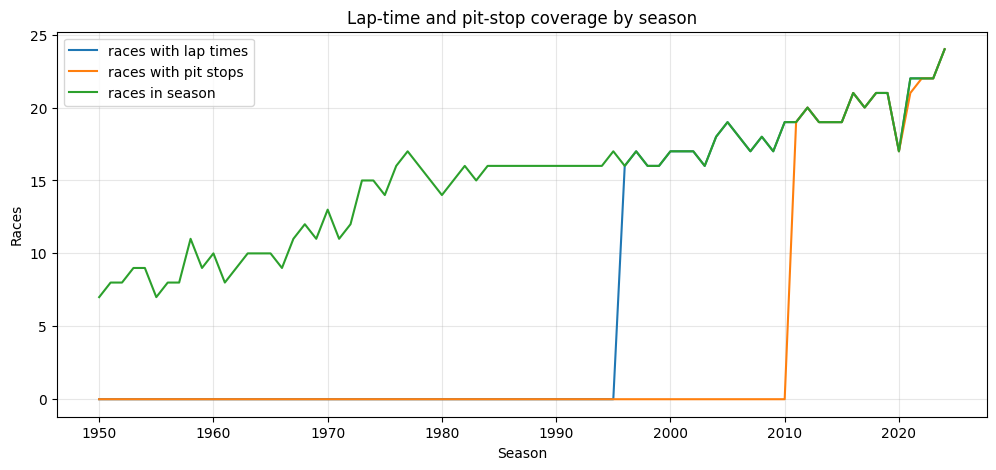

In [625]:
race_years = races_clean.set_index('raceId')['year']

coverage = pd.DataFrame({
    'races with lap times': lap_times_clean.groupby(lap_times_clean['raceId'].map(race_years))['raceId'].nunique(),
    'races with pit stops': pit_stops_clean.groupby(pit_stops_clean['raceId'].map(race_years))['raceId'].nunique(),
    'races in season': races_clean.groupby('year')['raceId'].nunique()
}).fillna(0).astype(int)

print("First season with lap times:", coverage.index[coverage['races with lap times'] > 0].min())
print("First season with pit stops:", coverage.index[coverage['races with pit stops'] > 0].min())

coverage[['races with lap times', 'races with pit stops', 'races in season']].plot(figsize=(12, 5))
plt.title('Lap-time and pit-stop coverage by season')
plt.xlabel('Season')
plt.ylabel('Races')
plt.grid(alpha=0.3)
plt.show()

In [626]:
# Extreme durations: if a whole race has the same huge value, it is a stoppage, not an error
for name, df, col in [('lap_times', lap_times_clean, 'time_seconds'),
                      ('pit_stops', pit_stops_clean, 'duration_seconds')]:
    threshold = df[col].quantile(0.999)
    extreme = df[df[col] > threshold]

    per_race = (
        extreme.groupby('raceId')
        .agg(rows=(col, 'size'), drivers=('driverId', 'nunique'),
             min_seconds=(col, 'min'), max_seconds=(col, 'max'))
        .join(races_clean.set_index('raceId')[['year', 'name']])
        .sort_values('rows', ascending=False)
    )

    print(f"{name}: {len(extreme)} rows above the 99.9th percentile ({threshold:.1f} s)")
    display(per_race.head(10))

lap_times: 590 rows above the 99.9th percentile (1080.9 s)


,rows,drivers,min_seconds,max_seconds,year,name
raceId,,,,,,
967,36,18,1587.639,2126.744,2016,Brazilian Grand Prix
1072,35,19,1185.303,1307.962,2021,Saudi Arabian Grand Prix
1100,30,18,1080.934,2014.652,2023,Australian Grand Prix
353,24,24,2920.458,2942.501,2010,Korean Grand Prix
861,23,23,3131.997,3138.842,2012,Malaysian Grand Prix
847,23,23,7469.869,7507.547,2011,Canadian Grand Prix
1039,23,13,1374.687,1617.695,2020,Tuscan Grand Prix
914,21,21,1264.753,1300.684,2014,Japanese Grand Prix
908,20,20,3667.384,3803.459,2014,British Grand Prix


pit_stops: 12 rows above the 99.9th percentile (3037.0 s)


,rows,drivers,min_seconds,max_seconds,year,name
raceId,,,,,,
1083,12,12,3037.323,3069.017,2022,British Grand Prix


#### 4.17.1 Pit-stop clock time to a time type
Durations are already in seconds (4.4); `pit_stops.time` is the time of day the stop happened (e.g. "17:05:23"), so it is converted to a time type like the race start times in 4.6.1, not to seconds.

In [627]:
# Record original non-missing count
original_pit_time_count = pit_stops_clean['time'].notna().sum()

parsed_pit_time = pd.to_datetime(
    pit_stops_clean['time'],
    format='%H:%M:%S',
    errors='coerce'
)

failed_pit_time = (pit_stops_clean['time'].notna() & parsed_pit_time.isna()).sum()
print("Pit-stop clock times before:", original_pit_time_count)
print("Failed conversions:", failed_pit_time)

pit_stops_clean['time'] = parsed_pit_time.dt.time

display(
    pit_stops_clean[['raceId', 'driverId', 'stop', 'time',
                     'duration', 'duration_seconds']].head()
)

# Summary of the semantic types now used for both tables
print("lap_times_clean types:")
print(lap_times_clean.dtypes)
print("\npit_stops_clean types:")
print(pit_stops_clean.dtypes)

assert failed_pit_time == 0
assert pit_stops_clean['time'].notna().sum() == original_pit_time_count


Pit-stop clock times before: 11371
Failed conversions: 0


,raceId,driverId,stop,time,duration,duration_seconds
0,841,153,1,17:05:23,26.898,26.898
1,841,30,1,17:05:52,25.021,25.021
2,841,17,1,17:20:48,23.426,23.426
3,841,4,1,17:22:34,23.251,23.251
4,841,13,1,17:24:10,23.842,23.842


lap_times_clean types:
raceId            int64
driverId          int64
lap               int64
position          int64
time             object
milliseconds      int64
time_seconds    float64
dtype: object

pit_stops_clean types:
raceId                int64
driverId              int64
stop                  int64
lap                   int64
time                 object
duration             object
milliseconds          int64
duration_seconds    float64
dtype: object


**Decision: lap_times and pit_stops keep all rows; only types are converted.**
- Keys are unique, foreign keys valid, no values missing, durations are in seconds from `milliseconds` (0 failures, 4.4–4.5) and the pit-stop clock time is a time type (4.17.1).
- The extreme durations are red-flag stoppages, not errors: the laps above the 99.9th percentile (> 1,081 s) come from races that were halted, such as the 2011 Canadian GP (about 2-hour rain stoppage), 2014 Japanese, 2016 Brazilian and 2020 Bahrain GPs, and in each one the whole field (18–24 drivers) has the long lap; the 12 pit stops above the threshold (> 3,037 s) are all from the 2022 British GP red flag. They are real recorded events, so they are not deleted.
- Both tables describe what happens during a race, so they are never used as features for that race; lap times only start in 1996 and pit stops in 2011, so any past-race feature built from them would be missing for earlier seasons.

## 5. Data-Engineering Questions
Each question joins several cleaned tables (multi-hop), answers with a table and a plot, and states its grain, missing data and, where relevant, the pre-race cutoff. All three use `results_clean`, so non-starters, duplicates and the Indy 500 are already handled.

In [628]:
# Shared plot colours for this section (one hue per era / group)
ERA_COLORS = {'1994–2013': '#eb6834', '2014–2024': '#2a78d6'}
GROUP_COLORS = {'away': '#9b9a95', 'home': '#2a78d6'}
TEXT_COLOR = '#52514e'

### 5.1 Q1 — Which circuits convert a front-row start into a podium most often, and did that change after 2014?
**Joins:** `results_clean` → `races_clean` (year, circuit) → `circuits_clean` (name), plus `qualifying_clean` (qualifying position).
**Front row** is measured two ways, as the question asks: by **grid** (where the car actually started, after penalties) and by **qualifying position** (before penalties). Qualifying data starts in 1994, so both are compared over **1994–2013 vs. 2014–2024** (the hybrid era).

In [629]:
q1 = (
    results_clean[['raceId', 'driverId', 'grid', 'podium']]
    .merge(races_clean[['raceId', 'year', 'circuitId']], on='raceId', how='left', validate='many_to_one')
    .merge(circuits_clean[['circuitId', 'name']].rename(columns={'name': 'circuit'}),
           on='circuitId', how='left', validate='many_to_one')
    .merge(qualifying_clean[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'}),
           on=['raceId', 'driverId'], how='left', validate='one_to_one')
)
q1 = q1[q1['year'] >= 1994].copy()
q1['era'] = np.where(q1['year'] >= 2014, '2014–2024', '1994–2013')
q1['grid_front_row'] = q1['grid'].isin([1, 2])
q1['quali_front_row'] = q1['quali_position'].isin([1, 2])

print("Driver-race rows, 1994–2024:", len(q1))
print("Rows without a qualifying record:", q1['quali_position'].isna().sum())

# Grid vs. qualifying: how often penalties move a car on or off the front row.
# Compared only where a qualifying record exists; a missing record is not a penalty.
q1_known_qualifying = q1[q1['quali_position'].notna()].copy()
print("\nRows with qualifying information:", len(q1_known_qualifying))

print("Front row by qualifying (rows) vs. by grid (columns), rows with qualifying only:")
display(pd.crosstab(q1_known_qualifying['quali_front_row'],
                    q1_known_qualifying['grid_front_row'], margins=True))

Driver-race rows, 1994–2024: 12279
Rows without a qualifying record: 1824

Rows with qualifying information: 10455
Front row by qualifying (rows) vs. by grid (columns), rows with qualifying only:


grid_front_row,False,True,All
quali_front_row,,,
False,9433,36,9469
True,38,948,986
All,9471,984,10455


In [630]:
MIN_STARTS = 10   # front-row starts per circuit per era


def conversion_by_circuit(df, front_row_col):
    """Podium rate of front-row starters per circuit and era."""
    front = df[df[front_row_col]]
    table = (
        front.groupby(['circuit', 'era'])['podium']
        .agg(starts='size', podiums='sum')
        .assign(rate=lambda t: t['podiums'] / t['starts'] * 100)
        .unstack('era')
    )
    # keep circuits with enough front-row starts in BOTH eras
    enough = (table['starts'] >= MIN_STARTS).all(axis=1)
    return table[enough]


q1_grid = conversion_by_circuit(q1, 'grid_front_row')
q1_quali = conversion_by_circuit(q1, 'quali_front_row')

for label, table in [('grid', q1_grid), ('qualifying', q1_quali)]:
    rates = table['rate']
    rank_corr = rates['1994–2013'].corr(rates['2014–2024'], method='spearman')
    print(f"Front row by {label}: {len(table)} circuits with >= {MIN_STARTS} front-row starts in each era")
    print(f"  Rank correlation between eras (1 = same ranking): {rank_corr:.2f}")

print("\nConversion rate (%) by circuit, front row by grid, sorted by 2014–2024:")
display(
    q1_grid['rate'].round(1)
    .join(q1_grid['starts'].add_suffix(' starts'))
    .sort_values('2014–2024', ascending=False)
)

Front row by grid: 15 circuits with >= 10 front-row starts in each era
  Rank correlation between eras (1 = same ranking): -0.07
Front row by qualifying: 14 circuits with >= 10 front-row starts in each era
  Rank correlation between eras (1 = same ranking): 0.20

Conversion rate (%) by circuit, front row by grid, sorted by 2014–2024:


era,1994–2013,2014–2024,1994–2013 starts,2014–2024 starts
circuit,,,,
Suzuka Circuit,75.0,88.9,36.0,18.0
Yas Marina Circuit,60.0,86.4,10.0,22.0
Circuit de Monaco,65.0,85.0,40.0,20.0
Circuit de Barcelona-Catalunya,65.0,81.8,40.0,22.0
Circuit de Spa-Francorchamps,50.0,81.8,36.0,22.0
Autódromo José Carlos Pace,55.0,78.9,40.0,19.0
Shanghai International Circuit,65.0,78.6,20.0,14.0
Circuit Gilles Villeneuve,57.9,77.8,38.0,18.0
Silverstone Circuit,62.5,75.0,40.0,24.0


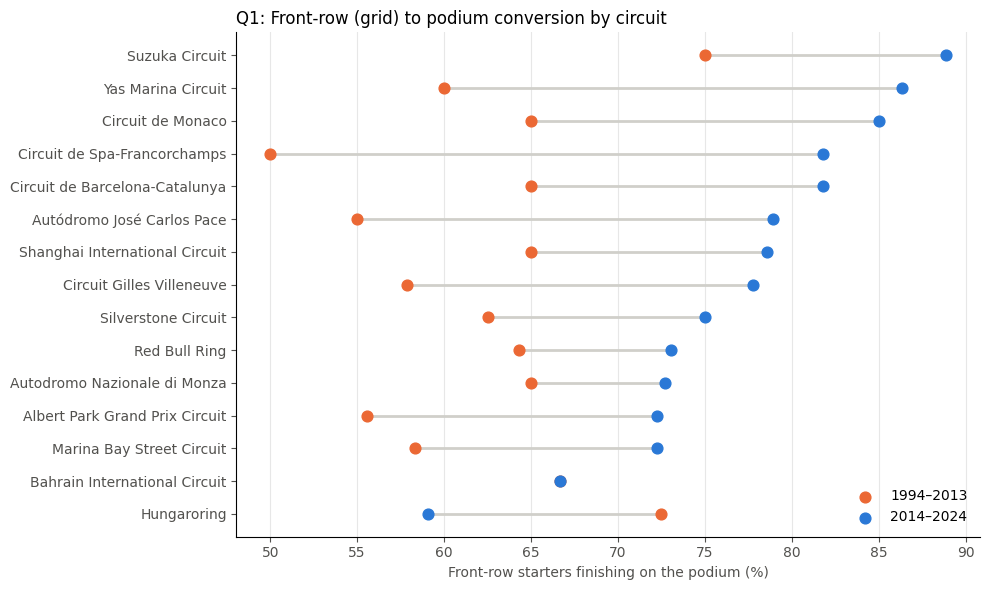

In [631]:
# Dumbbell plot: each circuit's conversion rate before and after 2014 (front row by grid)
plot_data = q1_grid['rate'].sort_values('2014–2024')

fig, ax = plt.subplots(figsize=(10, max(4, 0.4 * len(plot_data))))
y = np.arange(len(plot_data))
ax.hlines(y, plot_data['1994–2013'], plot_data['2014–2024'], color='#d0cfca', lw=2, zorder=1)
for era, color in ERA_COLORS.items():
    ax.scatter(plot_data[era], y, color=color, s=60, zorder=2, label=era)

ax.set_yticks(y, plot_data.index)
ax.set_xlabel('Front-row starters finishing on the podium (%)', color=TEXT_COLOR)
ax.set_title('Q1: Front-row (grid) to podium conversion by circuit', loc='left', fontsize=12)
ax.tick_params(colors=TEXT_COLOR)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

**Q1 — Answer**
- **Front-row starters became more likely to finish on the podium after 2014:** at 13 of the 15 circuits with enough data the conversion rate rose, Bahrain stayed level (66.7%) and only the **Hungaroring** fell (72.5% → 59.1%).
- **Best converters, 2014–2024 (front row by grid):** **Suzuka (88.9%)**, **Yas Marina (86.4%)**, **Monaco (85.0%)**, then Barcelona and Spa (81.8%). **1994–2013:** **Suzuka (75.0%)**, **Hungaroring (72.5%)** and **Bahrain (66.7%)**.
- **The ranking changed almost completely:** the rank correlation between the two eras is **−0.07** with front row by grid and **0.20** with front row by qualifying (1 would mean the same order). Suzuka is the only circuit at the top in both eras.
- **Qualifying vs. grid differ only slightly:** among the 10,455 rows with a qualifying record, 948 drivers both qualified and started on the front row, 36 started on the front row without qualifying there and 38 front-row qualifiers started further back (penalties and grid changes); this is why both definitions are reported. Rows without a qualifying record are left out of that comparison, because a missing record is not a penalty.
- **Caveats:** each rate rests on 10–40 front-row starts per era (Yas Marina only 10 before 2014), so single races move rates by several points; 1,824 of the 12,279 rows from 1994 onward have no qualifying record, so the qualifying definition covers fewer starts.

**Q1 — grain, missing data and cutoff**
- **Grain:** one row per driver per race (`results_clean`), restricted to front-row starters; the rate is computed per circuit and era.
- **Missing data:** qualifying positions exist only from 1994, so the comparison starts there; rows without a qualifying record are not counted as a qualifying front row. Circuits with fewer than 10 front-row starts in either era are left out, because a rate from a handful of races is unreliable.
- **Cutoff:** grid and qualifying position are both known before the race; the podium is the outcome being measured.

### 5.2 Q2 — Do drivers finish on the podium more often at home, after controlling for starting position?
**Joins:** `results_clean` → `drivers_clean` (`home_country`, `home_country_2`, 4.11.2) and `results_clean` → `races_clean` → `circuits_clean` (country).
A race is a **home race** when the circuit's country is the driver's home country (either one for dual nationalities). Home drivers might simply start further up, so home and away are compared **within the same starting-position group**.

In [632]:
q2 = (
    results_clean[['raceId', 'driverId', 'grid', 'podium']]
    .merge(races_clean[['raceId', 'year', 'circuitId']], on='raceId', how='left', validate='many_to_one')
    .merge(circuits_clean[['circuitId', 'country']], on='circuitId', how='left', validate='many_to_one')
    .merge(drivers_clean[['driverId', 'home_country', 'home_country_2']],
           on='driverId', how='left', validate='many_to_one')
)
q2['is_home'] = (q2['country'] == q2['home_country']) | (q2['country'] == q2['home_country_2'])

# Starting-position groups; grid 0 (no slot recorded, often a pit-lane start) is its own group
q2['grid_group'] = pd.cut(q2['grid'], bins=[-1, 0, 3, 6, 10, np.inf],
                          labels=['grid 0', '1–3', '4–6', '7–10', '11+'])

print("Driver-race rows:", len(q2))
print("Home starts:", q2['is_home'].sum(), f"({q2['is_home'].mean() * 100:.1f}%)")
print("Rows without a home country:", q2['home_country'].isna().sum())

# Without control: simple home vs. away podium rate
raw = q2.groupby('is_home')['podium'].mean() * 100
print(f"\nWithout controlling for grid: home {raw[True]:.1f}% vs. away {raw[False]:.1f}%")

# With control: compare inside each grid group
by_group = (
    q2.groupby(['grid_group', 'is_home'], observed=True)['podium']
    .agg(rate='mean', starts='size')
    .unstack('is_home')
)
by_group.columns = [f"{stat} {'home' if home else 'away'}" for stat, home in by_group.columns]
by_group['rate home'] *= 100
by_group['rate away'] *= 100
by_group['difference (pp)'] = by_group['rate home'] - by_group['rate away']
display(by_group.round(2))

# One overall number: group differences weighted by the number of home starts
weights = by_group['starts home'].fillna(0)
controlled_diff = (by_group['difference (pp)'] * weights).sum() / weights.sum()
print(f"Home advantage after controlling for grid: {controlled_diff:+.2f} percentage points")

Driver-race rows: 24686
Home starts: 1943 (7.9%)
Rows without a home country: 0

Without controlling for grid: home 11.6% vs. away 13.7%


,rate away,rate home,starts away,starts home,difference (pp)
grid_group,,,,,
grid 0,0.00,0.00,121,9,0.00
1–3,55.47,55.84,3106,231,0.37
4–6,26.06,26.67,3112,225,0.61
7–10,9.28,7.16,4095,335,-2.12
11+,1.67,1.05,12309,1143,-0.62


Home advantage after controlling for grid: -0.61 percentage points


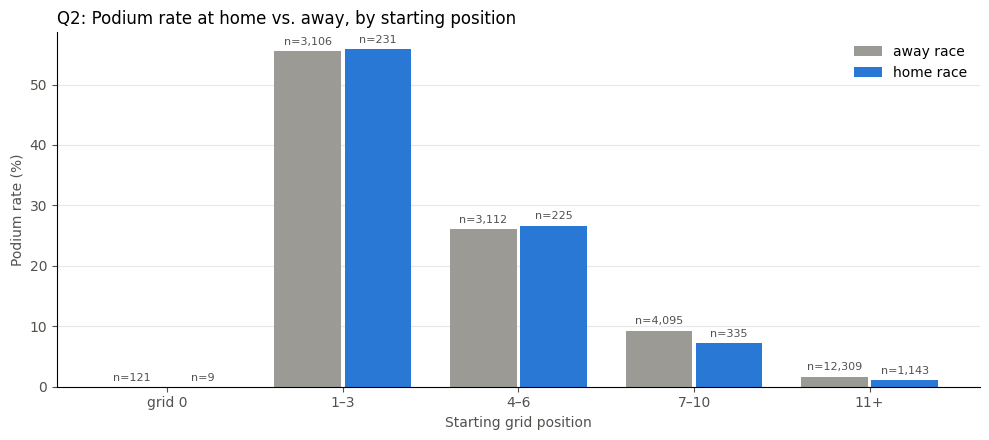

In [633]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(by_group.index))
for offset, side in [(-0.2, 'away'), (0.2, 'home')]:
    bars = ax.bar(x + offset, by_group[f'rate {side}'], width=0.38,
                  color=GROUP_COLORS[side], label=f'{side} race')
    ax.bar_label(bars, labels=[f"n={int(n):,}" for n in by_group[f'starts {side}'].fillna(0)],
                 padding=3, fontsize=8, color=TEXT_COLOR)

ax.set_xticks(x, by_group.index)
ax.set_xlabel('Starting grid position', color=TEXT_COLOR)
ax.set_ylabel('Podium rate (%)', color=TEXT_COLOR)
ax.set_title('Q2: Podium rate at home vs. away, by starting position', loc='left', fontsize=12)
ax.tick_params(colors=TEXT_COLOR)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Q2 — Answer**
- **No home advantage once starting position is taken into account.** Without any control, drivers actually podium *less* at home (11.6% vs. 13.7% away), because home starts come more often from the back: 58.8% of home starts (1,143 of 1,943) are from grid 11+ vs. 54.1% of away starts (12,309 of 22,743).
- **Inside each grid group the gap is close to zero:** +0.4 points (grid 1–3), +0.6 (4–6), −2.1 (7–10) and −0.6 (11+). Weighted by home starts, the overall difference is **−0.61 percentage points**.
- **Conclusion:** the raw "home disadvantage" disappears when drivers who start from similar positions are compared, and there is no sign of a home boost; starting position explains the difference.
- **Caveats:** home starts are only 7.9% of rows (1,943), so each group's home rate rests on 225–1,143 starts (9 from grid 0), and the small differences are within what chance can produce.

**Q2 — grain, missing data and cutoff**
- **Grain:** one row per driver per race; rates are compared per starting-position group, then combined into one number weighted by home starts.
- **Missing data:** every driver has a home country after the mapping in 4.11.2; drivers from countries that never hosted a race can only race away, which is correct rather than missing. Small groups (see `n` in the plot) give less reliable rates.
- **Cutoff:** nationality, circuit country and grid position are all known before the race.

### 5.3 Q3 — Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?
**Joins:** `results_clean` → `races_clean` (year) → `status_clean` (`is_mechanical`, 4.8) → `constructors_clean` (name).
**Rate** = mechanical retirements ÷ race starts. Non-starters were removed in 4.9.7, so the denominator counts only cars that actually started. Constructors need at least 30 starts in a period, and renamed teams are kept under the name the data records (e.g. Force India, Racing Point and Aston Martin separately).

In [634]:
MIN_STARTS_Q3 = 30

q3 = (
    results_clean[['raceId', 'driverId', 'constructorId', 'statusId']]
    .merge(races_clean[['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
    .merge(status_clean[['statusId', 'is_mechanical']], on='statusId', how='left', validate='many_to_one')
    .merge(constructors_clean[['constructorId', 'name']].rename(columns={'name': 'constructor'}),
           on='constructorId', how='left', validate='many_to_one')
)
q3 = q3[q3['year'].between(2014, 2024)].copy()
q3['period'] = np.where(q3['year'] <= 2021, '2014–2021', '2022–2024')

print("Race starts 2014–2024:", len(q3))
print("Rows with no status category:", q3['is_mechanical'].isna().sum())

q3_rates = (
    q3.groupby(['period', 'constructor'])['is_mechanical']
    .agg(starts='size', mechanical='sum')
    .assign(rate=lambda t: t['mechanical'] / t['starts'] * 100)
    .reset_index()
)
q3_rates = q3_rates[q3_rates['starts'] >= MIN_STARTS_Q3]

for period, table in q3_rates.groupby('period'):
    print(f"\n{period}: mechanical-retirement rate by constructor")
    display(table.sort_values('rate', ascending=False)
            [['constructor', 'starts', 'mechanical', 'rate']].round(2).reset_index(drop=True))

Race starts 2014–2024: 4612
Rows with no status category: 0

2014–2021: mechanical-retirement rate by constructor


,constructor,starts,mechanical,rate
0,Caterham,34,8,23.53
1,Lotus F1,75,14,18.67
2,Toro Rosso,242,39,16.12
3,McLaren,318,44,13.84
4,Renault,200,27,13.50
5,Sauber,200,22,11.00
6,Red Bull,319,34,10.66
7,AlphaTauri,78,8,10.26
8,Marussia,31,3,9.68
9,Racing Point,76,7,9.21



2022–2024: mechanical-retirement rate by constructor


,constructor,starts,mechanical,rate
0,Alfa Romeo,88,11,12.50
1,Alpine F1 Team,136,15,11.03
2,AlphaTauri,88,7,7.95
3,Ferrari,136,9,6.62
4,Williams,134,8,5.97
5,Aston Martin,133,7,5.26
6,Haas F1 Team,135,6,4.44
7,Mercedes,136,6,4.41
8,RB F1 Team,48,2,4.17
9,McLaren,136,5,3.68


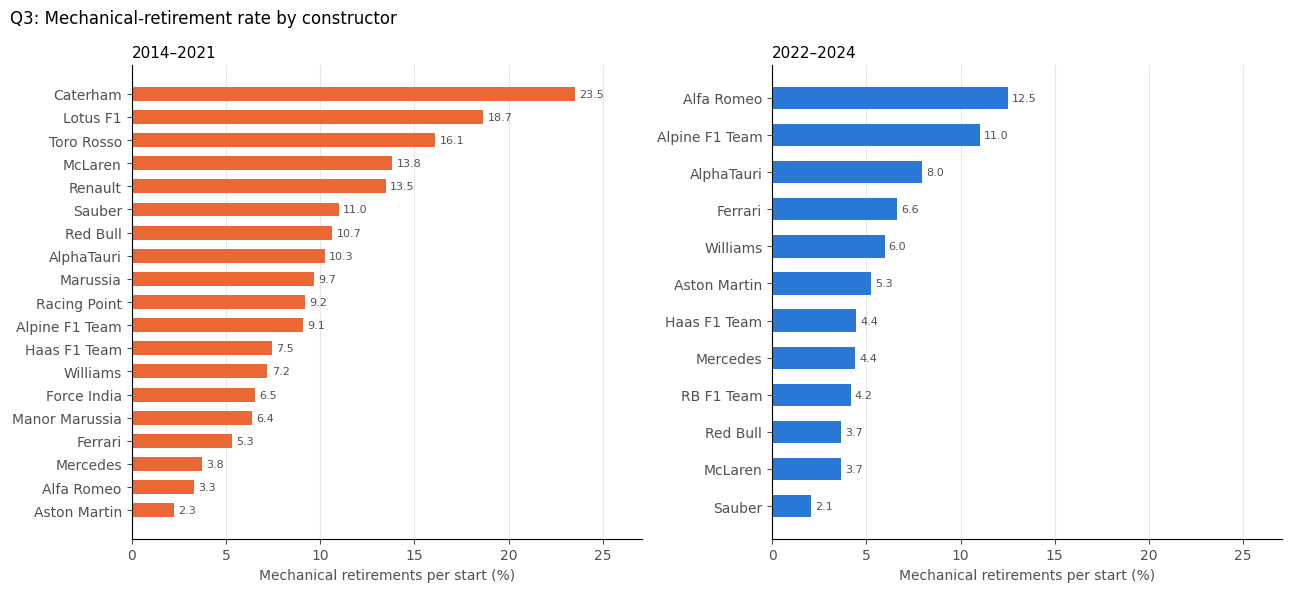

In [635]:
periods = ['2014–2021', '2022–2024']
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
max_rate = q3_rates['rate'].max()

for ax, period, color in zip(axes, periods, ['#eb6834', '#2a78d6']):
    table = q3_rates[q3_rates['period'] == period].sort_values('rate')
    bars = ax.barh(table['constructor'], table['rate'], color=color, height=0.6)
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8, color=TEXT_COLOR)
    ax.set_title(period, loc='left', fontsize=11)
    ax.set_xlabel('Mechanical retirements per start (%)', color=TEXT_COLOR)
    ax.set_xlim(0, max_rate * 1.15)
    ax.tick_params(colors=TEXT_COLOR)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle('Q3: Mechanical-retirement rate by constructor', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

**Q3 — Answer**
- **2014–2021:** the highest mechanical-retirement rates were **Caterham (23.5%)**, **Lotus F1 (18.7%)**, **Toro Rosso (16.1%)**, **McLaren (13.8%)** and **Renault (13.5%)**; the most reliable were **Aston Martin (2.3%)**, **Alfa Romeo (3.3%)**, **Mercedes (3.8%)** and **Ferrari (5.3%)**.
- **2022–2024:** the highest were **Alfa Romeo (12.5%)**, **Alpine (11.0%)** and **AlphaTauri (8.0%)**; the lowest were **Sauber (2.1%)**, **McLaren (3.7%)** and **Red Bull (3.7%)**.
- **Reliability improved overall:** 303 mechanical retirements in 3,258 starts (9.3%) in 2014–2021 vs. 82 in 1,354 starts (6.1%) in 2022–2024, and the worst team's rate roughly halved (23.5% → 12.5%).
- **The ranking changed:** McLaren (13.8% → 3.7%) and Red Bull (10.7% → 3.7%) went from among the least to among the most reliable, while Alfa Romeo moved the other way (3.3% → 12.5%).
- **Caveats:** Caterham (34 starts), Marussia (31), Alpine and Aston Martin in 2014–2021 (44 each) are just above the 30-start minimum, so their rates are less certain; renamed teams are counted separately as the data records them; and the rates rely on recorded retirement reasons, so they are conservative estimates.

**Q3 — grain, missing data and cutoff**
- **Grain:** one row per race start; the rate is computed per constructor and period.
- **Missing data:** every status has a category (4.8). The rate relies on the recorded retirement reason, and vague statuses such as `Retired` are not counted as mechanical, so it is a conservative estimate, not an exact count of every mechanical failure.
- **Cutoff:** retirements are race outcomes, so this is descriptive analysis only; it is never used as a feature for the same race.

## 6. Feature Engineering
Every feature must be known **after qualifying and before the race starts**. Anything about the current race's result (finishing position, points, laps, status, pit stops, standings after the race) is excluded. Form and standings features use **past races only**: rows are sorted by race **date** and shifted by one race, so the current race never contributes to its own features.

### 6.1 Base table and data split
All seasons (1950–2024) are used, including those with incomplete data: before 1994 there is no qualifying table, so those rows get the qualifying position from the grid, `has_qualifying` = 0 and an imputed time gap (6.3). Features are built for every row, so form and standings always draw on the full history.

**Main split — chronological (`split`).** Training: 1950–2019, validation: 2020–2021, test: 2022–2024. The task is to predict an upcoming race from what is known before it, so the model learns only from the past and is tested on later seasons it has never seen, exactly as it would be used. All tuning, the decision threshold, the model comparison, the ablation and the explanations use this split; the test seasons are used once, at the end.

**Robustness check — by era (`era_split`).** The seasons are divided into five 15-season eras and shuffled inside each era with a fixed seed: 11 seasons to training, 2 to validation and 2 to test, so every era (including modern F1) is in all three sets. The same models are also scored on this split to check that they hold up across eras and not only in recent seasons.

In both splits whole seasons stay together: rows of one race (same weather, same dominant car) and one championship are never split across sets, which a random row split would do.

**Shared-drive rows left out of modeling.** The rows kept from the 1950s duplicate groups (4.9.4) may not carry the driver's full podium outcome: a driver whose other car reached the podium can be labelled 0. These rows are flagged as `ambiguous_shared_drive` and left out of training, validation and test, rather than given an uncertain label. They stay in `results_clean`, the EDA and Q1–Q3, and features are still built on the full table so race sizes and race histories stay complete. Limitation: their labels still feed the same driver's later form features.

In [ ]:
model_df = (
    results_clean[['resultId', 'raceId', 'driverId', 'constructorId',
                   'grid', 'positionOrder', 'podium']]
    .merge(races_clean[['raceId', 'year', 'round', 'date', 'circuitId']],
           on='raceId', how='left', validate='many_to_one')
    .sort_values(['date', 'raceId', 'driverId'])
    .reset_index(drop=True)
)
print("Rows:", len(model_df), "| seasons:", model_df['year'].min(), "-", model_df['year'].max())

# Shared-drive rows whose kept record was chosen among several cars (4.9.4): left out of modeling
ambiguous_ids = results_clean.loc[results_clean['selection_method'] != 'single_record', 'resultId']
model_df['ambiguous_shared_drive'] = model_df['resultId'].isin(ambiguous_ids).astype(int)
print("Ambiguous shared-drive rows (excluded from modeling):", model_df['ambiguous_shared_drive'].sum(),
      "| seasons:", sorted(model_df.loc[model_df['ambiguous_shared_drive'] == 1, 'year'].unique()))

# Main split: chronological (train <= 2019, validation 2020-2021, test >= 2022)
model_df['split'] = np.select(
    [model_df['year'] <= 2019, model_df['year'] <= 2021],
    ['train', 'validation'], default='test'
)

# Robustness check: random by season, within five 15-season eras (whole seasons stay together)
SEED = 42
ERA_STARTS = [1950, 1965, 1980, 1995, 2010]
rng = np.random.default_rng(SEED)

TRAIN_SEASONS, VAL_SEASONS, TEST_SEASONS = [], [], []
for start in ERA_STARTS:
    era_seasons = rng.permutation(np.arange(start, start + 15))
    TRAIN_SEASONS += era_seasons[:11].tolist()
    VAL_SEASONS += era_seasons[11:13].tolist()
    TEST_SEASONS += era_seasons[13:].tolist()
TRAIN_SEASONS, VAL_SEASONS, TEST_SEASONS = sorted(TRAIN_SEASONS), sorted(VAL_SEASONS), sorted(TEST_SEASONS)

# The documented era split must be the one produced here
assert VAL_SEASONS == [1951, 1962, 1971, 1976, 1992, 1993, 1999, 2009, 2017, 2019]
assert TEST_SEASONS == [1958, 1963, 1974, 1979, 1980, 1983, 1998, 2006, 2015, 2022]
assert set(TRAIN_SEASONS) | set(VAL_SEASONS) | set(TEST_SEASONS) == set(model_df['year'])

season_to_split = {**{y: 'train' for y in TRAIN_SEASONS},
                   **{y: 'validation' for y in VAL_SEASONS},
                   **{y: 'test' for y in TEST_SEASONS}}
model_df['era_split'] = model_df['year'].map(season_to_split)

# Evidence: rows and seasons per set in both splits
for name in ['split', 'era_split']:
    summary = model_df.groupby(name).agg(rows=('raceId', 'size'),
                                         seasons=('year', 'nunique'),
                                         first=('year', 'min'), last=('year', 'max'))
    print(f"\n{name}:")
    display(summary.loc[['train', 'validation', 'test']])

print("Era split - validation seasons:", VAL_SEASONS)
print("Era split - test seasons:", TEST_SEASONS)

decade = (model_df['year'] // 10 * 10).astype(str) + 's'
display(pd.crosstab(decade, model_df['era_split'])[['train', 'validation', 'test']]
        .rename_axis('decade (rows, era split)'))

assert not set(TRAIN_SEASONS) & set(VAL_SEASONS)
assert not set(TRAIN_SEASONS) & set(TEST_SEASONS)
assert not set(VAL_SEASONS) & set(TEST_SEASONS)
assert model_df['split'].notna().all() and model_df['era_split'].notna().all()
assert len(model_df) == len(results_clean)
assert not model_df.duplicated(['raceId', 'driverId']).any()

### 6.2 Grid features
`grid` is the actual starting slot (after penalties). Grid 0 means no starting slot was recorded: often a pit-lane start, but not always — of the 130 grid-0 rows left after cleaning, 72 completed at least one lap and 58 none (4.9.5). `grid_zero_flag` marks these rows, and `grid_filled` places them at the back of the field (the number of starters). That back-of-grid value is an **assumption**, not a recorded position; the flag lets the model treat these rows differently.

In [637]:
model_df['field_size'] = model_df.groupby('raceId')['driverId'].transform('size')
model_df['grid_zero_flag'] = (model_df['grid'] == 0).astype(int)
# Assumption: a driver with no recorded slot starts from the back of the field
model_df['grid_filled'] = model_df['grid'].where(model_df['grid'] > 0, model_df['field_size'])

print("Grid-0 rows (no starting slot recorded):", model_df['grid_zero_flag'].sum())
print(model_df[['grid', 'grid_filled', 'field_size']].describe().round(1))

Grid-0 rows (no starting slot recorded): 130
          grid  grid_filled  field_size
count  24686.0      24686.0     24686.0
mean      11.7         11.8        22.6
std        6.8          6.8         3.0
min        0.0          1.0         6.0
25%        6.0          6.0        20.0
50%       11.0         12.0        22.0
75%       17.0         17.0        25.0
max       34.0         34.0        34.0


### 6.3 Qualifying features
Qualifying position and the gap to the fastest qualifier are known before the race. The gap uses **Q1 times only**: every driver sets a Q1 time in the same session, whereas a driver knocked out in Q1 would otherwise be compared with a pole time set in Q3, under different track conditions (before 2006 the single session is stored as Q1). Only recorded times are used. Where no qualifying record exists, the position is filled with the grid slot (the two are nearly identical, 5.1) and `has_qualifying` records that it was filled; the time gap is left missing and imputed later on training data only.
**Extreme gaps.** A few Q1 gaps are far beyond normal qualifying pace (the largest is over 900%). They are listed below for inspection, and gaps above **30%** are set to missing in this feature only: such a time reflects an interrupted lap or a recording problem, not competitive pace, and a single huge value stretches the scaling of every other gap. 30% is a documented cleaning rule chosen from that inspection, not an official definition of an invalid lap; the original times stay unchanged in `qualifying_clean`, and the rows themselves are kept.

In [ ]:
quali_features = qualifying_clean[['raceId', 'driverId', 'position', 'q1_seconds']].copy()

# Gap to the fastest Q1 time of the same race (all drivers run Q1 in the same session)
fastest_q1 = quali_features.groupby('raceId')['q1_seconds'].transform('min')
quali_features['quali_gap_pct'] = (quali_features['q1_seconds'] / fastest_q1 - 1) * 100

print("Q1 gap computed for:", quali_features['quali_gap_pct'].notna().sum(), "of", len(quali_features), "qualifying rows")
print("Largest gaps (%):", quali_features['quali_gap_pct'].nlargest(5).round(1).tolist())
assert (quali_features['quali_gap_pct'].dropna() >= 0).all()

# Audit unusually large gaps before filtering
MAX_QUALI_GAP_PCT = 30
extreme_gaps = (
    quali_features.loc[quali_features['quali_gap_pct'] > MAX_QUALI_GAP_PCT,
                       ['raceId', 'driverId', 'q1_seconds', 'quali_gap_pct']]
    .assign(fastest_q1_seconds=fastest_q1)
    .merge(races_clean[['raceId', 'year', 'name']], on='raceId', how='left')
    .merge(drivers_clean[['driverId', 'surname']], on='driverId', how='left')
    .sort_values('quali_gap_pct', ascending=False)
)
print(f"\nQ1 gaps above {MAX_QUALI_GAP_PCT}%:", len(extreme_gaps))
display(extreme_gaps.round(3))

# Not a competitive pace measurement -> missing (imputed later on training data)
quali_features.loc[quali_features['quali_gap_pct'] > MAX_QUALI_GAP_PCT, 'quali_gap_pct'] = np.nan
print("Largest gap kept (%):", round(quali_features['quali_gap_pct'].max(), 1))

model_df = model_df.merge(
    quali_features[['raceId', 'driverId', 'position', 'quali_gap_pct']]
    .rename(columns={'position': 'quali_position'}),
    on=['raceId', 'driverId'], how='left', validate='one_to_one'
)
model_df['has_qualifying'] = model_df['quali_position'].notna().astype(int)
model_df['quali_position_filled'] = model_df['quali_position'].fillna(model_df['grid_filled'])

print("Rows without a qualifying record:", (model_df['has_qualifying'] == 0).sum(), "of", len(model_df))
print("  of which from 1994 onward:", ((model_df['has_qualifying'] == 0) & (model_df['year'] >= 1994)).sum())
print("Rows without a qualifying time gap:", model_df['quali_gap_pct'].isna().sum())

### 6.4 Driver and constructor form (past races only)
Form = how the driver or team did in their previous races: podium rate and average finish over the last 5 races, career podium rate and number of previous starts. Each value is computed with `shift(1)`, so a race only sees earlier races.

In [639]:
# Rows are sorted by date, so shift(1) inside each group = the previous race
by_driver = model_df.groupby('driverId')

model_df['drv_prev_races'] = by_driver.cumcount()
model_df['drv_podium_rate_last5'] = by_driver['podium'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
model_df['drv_avg_finish_last5'] = by_driver['positionOrder'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
model_df['drv_career_podium_rate'] = by_driver['podium'].transform(
    lambda s: s.shift(1).expanding().mean())
model_df['drv_form_source_date'] = by_driver['date'].shift(1)

# Driver's past podium rate at this circuit
model_df['drv_circuit_podium_rate'] = model_df.groupby(['driverId', 'circuitId'])['podium'].transform(
    lambda s: s.shift(1).expanding().mean())

# Constructor form: one row per team per race, then the same shift + rolling window
team_races = (
    model_df.groupby(['constructorId', 'raceId'])
    .agg(date=('date', 'first'), team_podiums=('podium', 'sum'), team_avg_finish=('positionOrder', 'mean'))
    .reset_index()
    .sort_values(['date', 'raceId'])
)
by_team = team_races.groupby('constructorId')
team_races['cons_podiums_last5'] = by_team['team_podiums'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team_races['cons_avg_finish_last5'] = by_team['team_avg_finish'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team_races['cons_form_source_date'] = by_team['date'].shift(1)

model_df = model_df.merge(
    team_races[['constructorId', 'raceId', 'cons_podiums_last5',
                'cons_avg_finish_last5', 'cons_form_source_date']],
    on=['constructorId', 'raceId'], how='left', validate='many_to_one'
)
print(model_df[['drv_prev_races', 'drv_podium_rate_last5', 'drv_avg_finish_last5',
                'drv_career_podium_rate', 'cons_podiums_last5']].describe().round(2))

       drv_prev_races  drv_podium_rate_last5  drv_avg_finish_last5  \
count        24686.00               24000.00              24000.00   
mean            68.09                   0.14                 11.69   
std             68.98                   0.24                  4.43   
min              0.00                   0.00                  1.00   
25%             15.00                   0.00                  8.60   
50%             45.00                   0.00                 12.00   
75%            100.00                   0.20                 14.80   
max            401.00                   1.00                 31.00   

       drv_career_podium_rate  cons_podiums_last5  
count                24000.00            24421.00  
mean                     0.12                0.31  
std                      0.16                0.46  
min                      0.00                0.00  
25%                      0.00                0.00  
50%                      0.05                0.00  
75%  

### 6.5 Pre-race championship standings
Standings tables hold the championship **after** each race (4.13), so each race takes the standings after the driver's or team's previous race of the same season. At the first race of a season everyone starts on 0 points and 0 wins with no position yet. Points systems changed over the years, so points are expressed as a share of the leader's points.

In [640]:
def pre_race_standings(standings, key, prefix):
    """Standings after the previous race of the same season, for each (raceId, key)."""
    s = standings.merge(races_clean[['raceId', 'year', 'date']], on='raceId', how='left')
    s = s.sort_values(['date', 'raceId'])
    season = s.groupby([key, 'year'])
    s[f'{prefix}_pre_points'] = season['points'].shift(1)
    s[f'{prefix}_pre_wins'] = season['wins'].shift(1)
    s[f'{prefix}_pre_position'] = season['position'].shift(1)
    s[f'{prefix}_standings_source_date'] = season['date'].shift(1)
    # season start: nothing scored yet
    s[f'{prefix}_pre_points'] = s[f'{prefix}_pre_points'].fillna(0)
    s[f'{prefix}_pre_wins'] = s[f'{prefix}_pre_wins'].fillna(0)
    leader = s.groupby('raceId')[f'{prefix}_pre_points'].transform('max')
    s[f'{prefix}_pre_points_share'] = np.where(leader > 0, s[f'{prefix}_pre_points'] / leader, 0.0)
    return s[['raceId', key, f'{prefix}_pre_points_share', f'{prefix}_pre_wins',
              f'{prefix}_pre_position', f'{prefix}_standings_source_date']]


model_df = model_df.merge(pre_race_standings(driver_standings_clean, 'driverId', 'drv'),
                          on=['raceId', 'driverId'], how='left', validate='one_to_one')
model_df = model_df.merge(pre_race_standings(constructor_standings_clean, 'constructorId', 'cons'),
                          on=['raceId', 'constructorId'], how='left', validate='many_to_one')

print(model_df[['drv_pre_points_share', 'drv_pre_wins', 'drv_pre_position',
                'cons_pre_points_share', 'cons_pre_position']].describe().round(2))

       drv_pre_points_share  drv_pre_wins  drv_pre_position  \
count              24261.00      24261.00          21771.00   
mean                   0.19          0.34             12.85   
std                    0.28          1.12              8.95   
min                    0.00          0.00              1.00   
25%                    0.00          0.00              6.00   
50%                    0.06          0.00             12.00   
75%                    0.28          0.00             18.00   
max                    1.00         18.00            102.00   

       cons_pre_points_share  cons_pre_position  
count               23355.00           21770.00  
mean                    0.28               6.10  
std                     0.33               3.63  
min                     0.00               1.00  
25%                     0.00               3.00  
50%                     0.12               6.00  
75%                     0.45               9.00  
max                     1.00    

#### 6.5.1 Check: do the standings come from the immediately previous race?
The shift takes each driver's or team's previous standings row in the season. If a race is missing from that history, the value comes from an older race: still before the race (no leakage), but possibly out of date. The check compares each source with the previous race of the season.

In [641]:
previous_race = (
    races_clean.sort_values('date')
    .assign(prev_race_date=lambda d: d.groupby('year')['date'].shift(1))
    [['raceId', 'prev_race_date']]
)
staleness = model_df[['raceId', 'year', 'drv_standings_source_date', 'cons_standings_source_date']].merge(
    previous_race, on='raceId', how='left', validate='many_to_one')
period = pd.cut(staleness['year'], bins=[1949, 1979, 2009, 2024], labels=['1950–1979', '1980–2009', '2010–2024'])

for prefix in ['drv', 'cons']:
    source = staleness[f'{prefix}_standings_source_date']
    status = np.select(
        [staleness['prev_race_date'].isna(), source.isna(),
         source == staleness['prev_race_date'], source < staleness['prev_race_date']],
        ['season start', 'no earlier standings this season', 'previous race', 'older race (stale)'],
        default='other'
    )
    print(f"{prefix} standings source, by period (rows):")
    display(pd.crosstab(period, status))

drv standings source, by period (rows):


col_0,no earlier standings this season,previous race,season start
year,,,
1950–1979,717,5514,585
1980–2009,559,10188,707
2010–2024,38,6069,309


cons standings source, by period (rows):


col_0,no earlier standings this season,previous race,season start
year,,,
1950–1979,1133,5098,585
1980–2009,174,10573,707
2010–2024,8,6099,309


**Assumptions in the standings features (documented, not reconstructed).**
- At the first race of a season every driver and team has 0 points and 0 wins: this is a fact, not an estimate.
- A championship position does not exist yet at the season start, for a driver or team joining mid-season, or for constructors before 1958 (4.13); these values are missing (see the missing-value table in 6.7) and are filled with the training median during preprocessing (7.1). That fill is a modeling assumption, not the real rank.
- The check above found no row whose standings come from an older race, in any period: every value is either the previous race, the season start, or missing because there were no earlier standings that season.

### 6.6 Context features and the sprint decision
Driver age (from `dob`, 4.11.1), home race (as in Q2), round of the season and hybrid era (2014+).
**Sprint decision:** neither sprint results nor a sprint-weekend flag is used as a feature. Sprints exist only from 2021, so with training seasons up to 2019 the flag would be 0 for every training row and no model could learn from it; and in 2021–2022 the sprint result set the race grid, so it is already contained in `grid`. `is_sprint_weekend` is still computed below for reference only.

In [642]:
required_driver_cols = ['dob', 'home_country', 'home_country_2']

missing_driver_cols = [
    c for c in required_driver_cols
    if c not in model_df.columns
]

if missing_driver_cols:
    model_df = model_df.merge(
        drivers_clean[['driverId'] + missing_driver_cols],
        on='driverId',
        how='left',
        validate='many_to_one'
    )

if 'country' not in model_df.columns:
    model_df = model_df.merge(
        circuits_clean[['circuitId', 'country']],
        on='circuitId',
        how='left',
        validate='many_to_one'
    )

# Convert dates safely
model_df['dob'] = pd.to_datetime(
    model_df['dob'], errors='coerce'
)
model_df['date'] = pd.to_datetime(
    model_df['date'], errors='coerce'
)

# Age at the time of the Grand Prix
model_df['driver_age'] = (
    (model_df['date'] - model_df['dob']).dt.days / 365.25
)

# Is the circuit in the driver's home country?
model_df['home_race'] = (
    (model_df['country'] == model_df['home_country'])
    | (model_df['country'] == model_df['home_country_2'])
).astype(int)

# Hybrid era (2014 onward)
model_df['hybrid_era'] = (
    model_df['year'] >= 2014
).astype(int)

# Weekend with a sprint event
model_df['is_sprint_weekend'] = (
    model_df['raceId']
    .isin(sprint_results_clean['raceId'])
).astype(int)

# Validate
assert not model_df.columns.duplicated().any()
assert not model_df.duplicated(
    ['raceId', 'driverId']
).any()
assert len(model_df) == len(results_clean)

print("Home races:", model_df['home_race'].sum())
print(
    "Sprint-weekend rows:",
    model_df['is_sprint_weekend'].sum()
)
print(
    "Driver age range:",
    round(model_df['driver_age'].min(), 1),
    "-",
    round(model_df['driver_age'].max(), 1)
)
print("\nContext feature creation passed!")


Home races: 1943
Sprint-weekend rows: 358
Driver age range: 17.5 - 56.8

Context feature creation passed!


### 6.7 Feature list and leakage check
The features are grouped for the ablation in Section 9. The check proves the form and standings features come only from earlier races: every source date must be strictly before the race date.

In [ ]:
FEATURE_GROUPS = {
    'grid': ['grid_filled', 'grid_zero_flag', 'field_size'],
    'qualifying': ['quali_position_filled', 'has_qualifying', 'quali_gap_pct'],
    'driver_form': ['drv_prev_races', 'drv_podium_rate_last5', 'drv_avg_finish_last5',
                    'drv_career_podium_rate', 'drv_circuit_podium_rate'],
    'constructor_form': ['cons_podiums_last5', 'cons_avg_finish_last5'],
    'standings': ['drv_pre_points_share', 'drv_pre_wins', 'drv_pre_position',
                  'cons_pre_points_share', 'cons_pre_position'],
    'context': ['driver_age', 'home_race', 'round', 'hybrid_era'],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
TARGET = 'podium'

# Leakage check: every past-race source is dated before the race it describes
for source in ['drv_form_source_date', 'cons_form_source_date',
               'drv_standings_source_date', 'cons_standings_source_date']:
    known = model_df[source].notna()
    print(f"{source}: {known.sum()} rows, all earlier than the race:",
          (model_df.loc[known, source] < model_df.loc[known, 'date']).all())
    assert (model_df.loc[known, source] < model_df.loc[known, 'date']).all()

# No result-of-the-race column may be a feature
forbidden = {'positionOrder', 'position', 'points', 'laps', 'statusId', 'milliseconds',
             'time_seconds', 'fastestLap', 'rank', 'podium'}
assert not forbidden & set(FEATURES)

print("\nFeatures:", len(FEATURES))
missing_pct = (model_df[FEATURES].isna().mean() * 100).round(2)
display(missing_pct[missing_pct > 0].rename('missing %').to_frame())

### 6.8 Evidence for the features (training seasons only)
Feature choices are checked on the training seasons only, so validation and test data never influence them. The table shows each feature's correlation with the podium; the plots show the podium rate across each feature's range.

In [ ]:
train_rows = model_df[(model_df['split'] == 'train') & (model_df['ambiguous_shared_drive'] == 0)]

evidence = pd.DataFrame({
    'group': [g for g, cols in FEATURE_GROUPS.items() for _ in cols],
    'correlation with podium': [train_rows[f].corr(train_rows[TARGET]) for f in FEATURES],
    'missing %': [round(train_rows[f].isna().mean() * 100, 2) for f in FEATURES],
}, index=FEATURES)
evidence['|correlation|'] = evidence['correlation with podium'].abs()
display(evidence.sort_values('|correlation|', ascending=False).round(3))

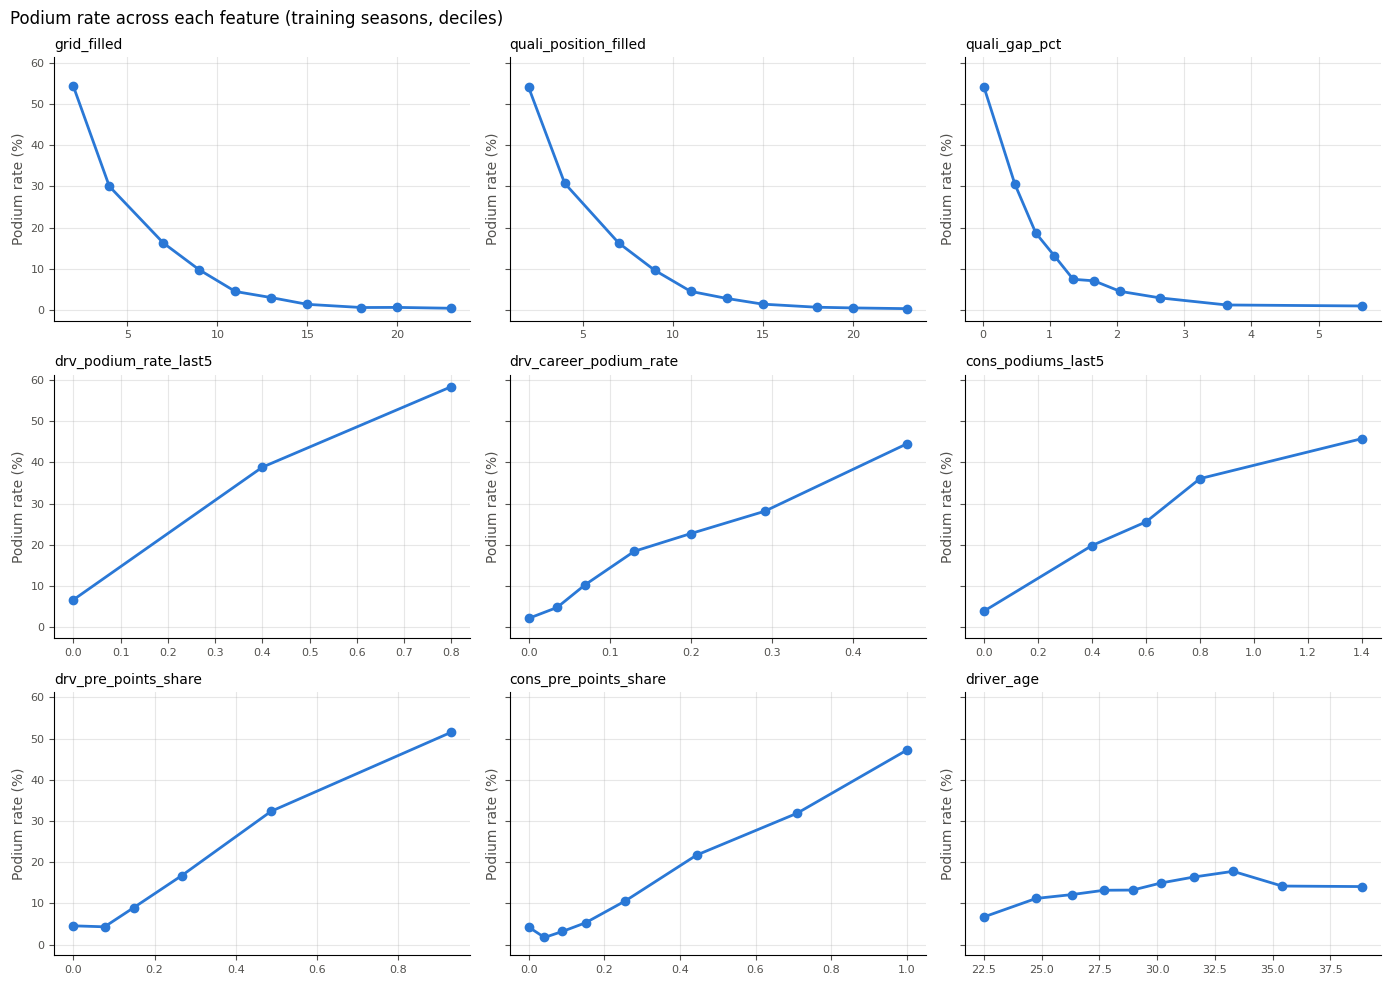

In [645]:
plot_features = ['grid_filled', 'quali_position_filled', 'quali_gap_pct',
                 'drv_podium_rate_last5', 'drv_career_podium_rate', 'cons_podiums_last5',
                 'drv_pre_points_share', 'cons_pre_points_share', 'driver_age']

fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharey=True)
for ax, feature in zip(axes.ravel(), plot_features):
    values = train_rows[[feature, TARGET]].dropna()
    bins = pd.qcut(values[feature], q=10, duplicates='drop')
    rate = values.groupby(bins, observed=True)[TARGET].mean() * 100
    centers = values.groupby(bins, observed=True)[feature].median()
    ax.plot(centers, rate, marker='o', color='#2a78d6', lw=2)
    ax.set_title(feature, loc='left', fontsize=10)
    ax.set_ylabel('Podium rate (%)', color=TEXT_COLOR)
    ax.tick_params(colors=TEXT_COLOR, labelsize=8)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)

fig.suptitle('Podium rate across each feature (training seasons, deciles)',
             x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

**Yes/no features.** The decile plots above cannot show 0/1 features, so their podium rate is compared directly (training seasons only).

In [ ]:
binary_features = ['grid_zero_flag', 'has_qualifying', 'home_race', 'hybrid_era']

fig, axes = plt.subplots(1, len(binary_features), figsize=(15, 3.8), sharey=True)
for ax, feature in zip(axes, binary_features):
    stats = train_rows.groupby(feature)[TARGET].agg(rate='mean', rows='size')
    bars = ax.bar(stats.index.astype(str), stats['rate'] * 100,
                  color=['#9b9a95', '#2a78d6'][:len(stats)], width=0.6)
    ax.bar_label(bars, labels=[f"n={n:,}" for n in stats['rows']], padding=3, fontsize=8, color=TEXT_COLOR)
    ax.set_title(feature, loc='left', fontsize=10)
    ax.set_xlabel('0 = no, 1 = yes', color=TEXT_COLOR, fontsize=8)
    ax.tick_params(colors=TEXT_COLOR)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Podium rate (%)', color=TEXT_COLOR)
fig.suptitle('Podium rate for the yes/no features (training seasons)', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

**Why each feature group was chosen**

Each group starts from a hypothesis based on the earlier EDA and data-engineering answers (grid: 4.9.12 and Q1; qualifying: Q1; era: Q1; home race: Q2), tested by the correlations and plots above. The empirical check follows in the feature-group ablation (Section 9), where each group is removed and the model retrained to measure what it actually adds.

**Validity at the pre-race cutoff:** each feature's source is explained in 6.2–6.6, and 6.7 checks that form and standings come only from earlier races and that no result column is used.

## 7. Preprocessing
All preprocessing is learned from the **training seasons only** and then applied unchanged to validation and test, so no information from later seasons leaks into the model. It is built into `Pipeline` objects, so the same steps run in the same order for every model and for the inference function.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_curve, precision_recall_curve)

RANDOM_STATE = 42
PARTS = ['train', 'validation', 'test']


def get_xy(split_col, part):
    rows = model_df[(model_df[split_col] == part) & (model_df['ambiguous_shared_drive'] == 0)]
    return rows[FEATURES], rows[TARGET]


X_train, y_train = get_xy('split', 'train')
X_val, y_val = get_xy('split', 'validation')
X_test, y_test = get_xy('split', 'test')

display(pd.DataFrame({
    'rows': [len(y_train), len(y_val), len(y_test)],
    'podium %': [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)],
}, index=PARTS))

### 7.1 Preprocessing steps and their effect
1. **Missing values → median of the training seasons.** The median is not pulled by extreme values (e.g. very large qualifying gaps), and `has_qualifying` already tells the model which qualifying values were filled.
2. **Scaling → mean 0, standard deviation 1.** Features range from 0/1 flags to ages near 30 and grid positions up to 34; logistic regression and the neural network learn badly when inputs are on such different scales. Gradient boosting splits on thresholds, so it needs neither step and handles missing values itself.

The table and plot show the effect on the training data: no missing values remain, every feature has mean 0 and standard deviation 1, and the filled values appear as a spike at the median.

,missing % before,mean before,std before,missing % after,mean after,std after
grid_filled,0.00,11.95,6.84,0.0,-0.0,1.0
grid_zero_flag,0.00,0.00,0.06,0.0,0.0,1.0
field_size,0.00,22.84,3.02,0.0,0.0,1.0
quali_position_filled,0.00,11.95,6.84,0.0,0.0,1.0
has_qualifying,0.00,0.37,0.48,0.0,0.0,1.0
quali_gap_pct,63.69,2.14,10.37,0.0,-0.0,1.0
drv_prev_races,0.00,61.60,61.81,0.0,-0.0,1.0
drv_podium_rate_last5,2.98,0.14,0.23,0.0,0.0,1.0
drv_avg_finish_last5,2.98,11.81,4.43,0.0,0.0,1.0
drv_career_podium_rate,2.98,0.12,0.16,0.0,0.0,1.0


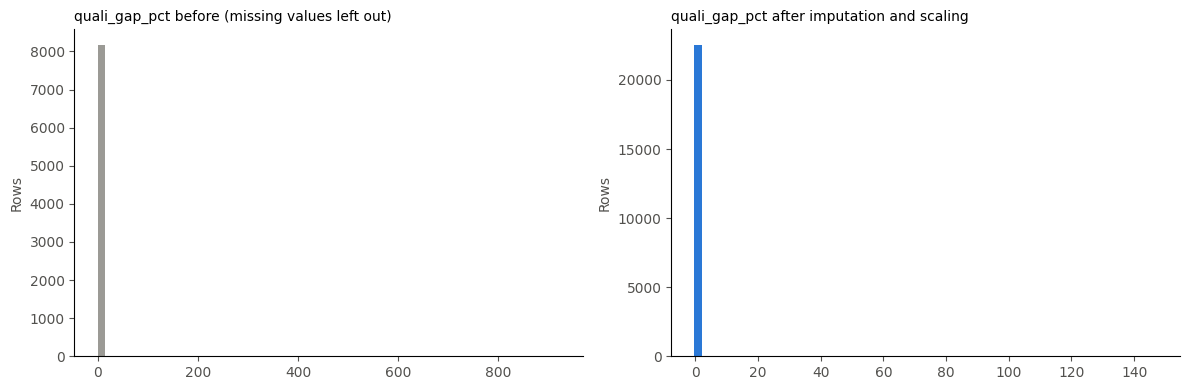

In [648]:
preprocessor = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
X_train_prepared = pd.DataFrame(preprocessor.fit_transform(X_train), columns=FEATURES, index=X_train.index)

effect = pd.DataFrame({
    'missing % before': (X_train.isna().mean() * 100).round(2),
    'mean before': X_train.mean().round(2),
    'std before': X_train.std().round(2),
    'missing % after': (X_train_prepared.isna().mean() * 100).round(2),
    'mean after': X_train_prepared.mean().round(2),
    'std after': X_train_prepared.std().round(2),
})
display(effect)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train['quali_gap_pct'].dropna(), bins=60, color='#9b9a95')
axes[0].set_title('quali_gap_pct before (missing values left out)', loc='left', fontsize=10)
axes[1].hist(X_train_prepared['quali_gap_pct'], bins=60, color='#2a78d6')
axes[1].set_title('quali_gap_pct after imputation and scaling', loc='left', fontsize=10)
for ax in axes:
    ax.set_ylabel('Rows', color=TEXT_COLOR)
    ax.tick_params(colors=TEXT_COLOR)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### 7.2 Shared evaluation helpers
Every model is scored the same way. The decision threshold (probability above which a row is predicted as podium) is chosen on the **validation** set to maximise F1. Experiments and tuning trials are scored on **train and validation only**; the test seasons are scored once, for the final models (8.4), so they cannot influence any choice.

In [649]:
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


def scores(y, proba, threshold):
    predicted = (proba >= threshold).astype(int)

    return {
        'ROC-AUC': roc_auc_score(y, proba),
        'PR-AUC': average_precision_score(y, proba),
        'accuracy': accuracy_score(y, predicted),
        'precision': precision_score(
            y, predicted, zero_division=0
        ),
        'recall': recall_score(
            y, predicted, zero_division=0
        ),
        'F1': f1_score(
            y, predicted, zero_division=0
        )
    }



def best_threshold(y, proba):
    thresholds = np.linspace(0.05, 0.95, 91)

    f1s = [
        f1_score(
            y,
            (proba >= t).astype(int),
            zero_division=0
        )
        for t in thresholds
    ]

    return thresholds[int(np.argmax(f1s))]


def evaluate(model, name, split_col='split', score_test=False):

    parts = PARTS if score_test else ['train', 'validation']

    data = {
        part: get_xy(split_col, part)
        for part in parts
    }

    fitted = clone(model).fit(*data['train'])

    proba = {
        part: fitted.predict_proba(data[part][0])[:, 1]
        for part in parts
    }

    threshold = best_threshold(
        data['validation'][1],
        proba['validation']
    )

    rows = [
        {
            'model': name,
            'part': part,
            'threshold': threshold,
            **scores(
                data[part][1],
                proba[part],
                threshold
            )
        }
        for part in parts
    ]

    return fitted, threshold, pd.DataFrame(rows)


print("Evaluation functions defined successfully!")
print(
    "Metrics: ROC-AUC, PR-AUC, Accuracy, "
    "Precision, Recall, F1"
)
print("Confusion matrices will be plotted for final models.")


Evaluation functions defined successfully!
Metrics: ROC-AUC, PR-AUC, Accuracy, Precision, Recall, F1
Confusion matrices will be plotted for final models.


### 7.3 Preprocessing-order experiment 1: fill missing values before or after scaling?
When missing values are filled with a constant 0, the order changes what 0 means. **Fill → scale:** 0 is a raw value, e.g. a qualifying gap of 0 % (the pole time) or grid position 0. **Scale → fill:** 0 is the training mean. The median fill used in 7.1 is shown for comparison. All three use the same logistic regression and are scored on validation.

In [650]:
def logistic(pipeline_steps):
    return Pipeline(pipeline_steps + [('model', LogisticRegression(max_iter=2000))])


order_experiment = {
    'fill 0, then scale': logistic([('impute', SimpleImputer(strategy='constant', fill_value=0)),
                                    ('scale', StandardScaler())]),
    'scale, then fill 0': logistic([('scale', StandardScaler()),
                                    ('impute', SimpleImputer(strategy='constant', fill_value=0))]),
    'fill median, then scale (chosen)': logistic([('impute', SimpleImputer(strategy='median')),
                                                  ('scale', StandardScaler())]),
}

order_results = pd.concat([evaluate(model, name)[2] for name, model in order_experiment.items()])
display(order_results[order_results['part'] == 'validation']
        .set_index('model')[['ROC-AUC', 'PR-AUC', 'F1']].round(4))

,ROC-AUC,PR-AUC,F1
model,,,
"fill 0, then scale",0.9302,0.7362,0.7185
"scale, then fill 0",0.9299,0.7349,0.7126
"fill median, then scale (chosen)",0.9297,0.7342,0.7099


**Conclusion of experiment 1.** The three approaches score within a few thousandths of PR-AUC of each other on validation (table above), so the order of filling and scaling barely changes the result here. Median filling, then scaling, is kept for its meaning and robustness, not because it scored highest: a constant 0 would claim "pole time" for a missing qualifying gap, while the median is a typical value and is not pulled by extreme gaps.

### 7.4 Preprocessing-order experiment 2: fit preprocessing before or after the split?
**Correct order:** split first, then learn the medians and scaling from the training seasons only. **Leaky order:** learn them from all seasons (including validation and test) before splitting. The experiment shows how much the preprocessing statistics change and whether the leaky order flatters the validation score.

In [651]:
X_all = pd.concat([X_train, X_val, X_test])

fit_on_train = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]).fit(X_train)
fit_on_all = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]).fit(X_all)

stats_change = pd.DataFrame({
    'median (train only)': fit_on_train.named_steps['impute'].statistics_,
    'median (all seasons)': fit_on_all.named_steps['impute'].statistics_,
    'mean (train only)': fit_on_train.named_steps['scale'].mean_,
    'mean (all seasons)': fit_on_all.named_steps['scale'].mean_,
}, index=FEATURES).round(3)
display(stats_change[(stats_change['median (train only)'] != stats_change['median (all seasons)'])
                     | (stats_change['mean (train only)'] != stats_change['mean (all seasons)'])])

leak_rows = []
for label, prep in [('fit on training seasons (correct)', fit_on_train),
                    ('fit on all seasons (leaky)', fit_on_all)]:
    clf = LogisticRegression(max_iter=2000).fit(prep.transform(X_train), y_train)
    proba_val = clf.predict_proba(prep.transform(X_val))[:, 1]
    leak_rows.append({'preprocessing': label,
                      **scores(y_val, proba_val, best_threshold(y_val, proba_val))})
display(pd.DataFrame(leak_rows).set_index('preprocessing')[['ROC-AUC', 'PR-AUC', 'F1']].round(4))

,median (train only),median (all seasons),mean (train only),mean (all seasons)
grid_filled,12.000,12.000,11.948,11.826
grid_zero_flag,0.000,0.000,0.003,0.005
field_size,22.000,22.000,22.837,22.586
quali_position_filled,12.000,12.000,11.947,11.821
has_qualifying,0.000,0.000,0.369,0.424
quali_gap_pct,1.502,1.344,1.733,1.594
drv_prev_races,41.000,45.000,61.599,68.091
drv_podium_rate_last5,0.000,0.000,0.133,0.134
drv_avg_finish_last5,12.000,12.000,11.816,11.697
drv_career_podium_rate,0.050,0.049,0.119,0.121


,ROC-AUC,PR-AUC,F1
preprocessing,,,
fit on training seasons (correct),0.9297,0.7342,0.7099
fit on all seasons (leaky),0.9118,0.6204,0.6637


## 8. Models
Three model types are trained on the same rows and the same 22 features, so their scores are directly comparable: logistic regression (baseline), gradient boosting and a shallow neural network, with more than one attempt for the last two.

**Primary metric: PR-AUC.** Only about 13% of rows are podiums (4.9.5 and the class balance in 4.9.11), so a model can score a high ROC-AUC mostly by ranking the many easy non-podium rows correctly; PR-AUC focuses on how well the actual podium finishers are ranked. **Secondary: ROC-AUC** (overall separation). **F1, precision and recall** are reported at the threshold chosen on validation.

### 8.1 Baseline: logistic regression
**How it works:** it learns one weight per feature and turns the weighted sum into a podium probability with the logistic (S-shaped) function. **Limitations:** it can only learn effects that rise or fall steadily with each feature and does not combine features on its own (e.g. "front row *and* a strong car"), so it is the simple reference the other models must beat.

In [652]:
attempts = {}   

baseline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000)),
])
attempts['Logistic regression (baseline)'] = evaluate(baseline, 'Logistic regression (baseline)')
display(attempts['Logistic regression (baseline)'][2].set_index('part').round(4))

,model,threshold,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
part,,,,,,,,
train,Logistic regression (baseline),0.22,0.9003,0.5688,0.8507,0.4654,0.7648,0.5787
validation,Logistic regression (baseline),0.22,0.9297,0.7342,0.9024,0.6414,0.7949,0.7099


### 8.2 Gradient boosting: default settings and a small tuning search
**How it works:** it builds many small decision trees one after another, each correcting the mistakes of the previous ones, so it can learn thresholds and combinations of features. `HistGradientBoostingClassifier` handles missing values itself, so it uses the raw features. **Limitations:** it overfits more easily than logistic regression (watch the train vs. validation gap) and its individual decisions are harder to read, which is why Section 10 explains it. The settings are chosen on validation only; every trial stays visible below.

**Early stopping.** `HistGradientBoostingClassifier` turns on early stopping automatically for datasets this large: it holds back part of the training data and stops adding trees once that score stops improving. It is kept on, because it limits overfitting. In the trials below, 200 and 400 trees can therefore give identical scores; the check after the table prints how many trees were actually fitted.

In [653]:
gb_default = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
attempts['Gradient boosting (default)'] = evaluate(gb_default, 'Gradient boosting (default)')
display(attempts['Gradient boosting (default)'][2].set_index('part').round(4))

,model,threshold,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
part,,,,,,,,
train,Gradient boosting (default),0.37,0.9355,0.6776,0.8980,0.6067,0.6798,0.6412
validation,Gradient boosting (default),0.37,0.9280,0.7043,0.9089,0.6917,0.7094,0.7004


In [654]:
gb_grid = [
    {'learning_rate': lr, 'max_depth': depth, 'max_iter': iters, 'l2_regularization': 1.0}
    for lr in [0.03, 0.1]
    for depth in [3, 6]
    for iters in [200, 400]
]

gb_trials = []
for params in gb_grid:
    model = HistGradientBoostingClassifier(random_state=RANDOM_STATE, **params)
    _, _, result = evaluate(model, 'trial')
    val = result.set_index('part').loc['validation']
    train = result.set_index('part').loc['train']
    gb_trials.append({**params, 'train PR-AUC': train['PR-AUC'],
                      'validation PR-AUC': val['PR-AUC'], 'validation ROC-AUC': val['ROC-AUC']})

gb_trials = pd.DataFrame(gb_trials).sort_values('validation PR-AUC', ascending=False)
display(gb_trials.round(4))

best_gb_params = gb_trials.iloc[0][['learning_rate', 'max_depth', 'max_iter', 'l2_regularization']].to_dict()
best_gb_params['max_depth'] = int(best_gb_params['max_depth'])
best_gb_params['max_iter'] = int(best_gb_params['max_iter'])
print("Chosen on validation PR-AUC:", best_gb_params)

gb_tuned = HistGradientBoostingClassifier(random_state=RANDOM_STATE, **best_gb_params)
attempts['Gradient boosting (tuned)'] = evaluate(gb_tuned, 'Gradient boosting (tuned)')
display(attempts['Gradient boosting (tuned)'][2].set_index('part').round(4))

,learning_rate,max_depth,max_iter,l2_regularization,train PR-AUC,validation PR-AUC,validation ROC-AUC
6,0.10,6,200,1.0,0.6629,0.7193,0.9264
7,0.10,6,400,1.0,0.6629,0.7193,0.9264
4,0.10,3,200,1.0,0.6088,0.7057,0.9272
5,0.10,3,400,1.0,0.6088,0.7057,0.9272
2,0.03,6,200,1.0,0.6500,0.7018,0.9239
3,0.03,6,400,1.0,0.6500,0.7018,0.9239
0,0.03,3,200,1.0,0.6060,0.7008,0.9276
1,0.03,3,400,1.0,0.6060,0.7008,0.9276


Chosen on validation PR-AUC: {'learning_rate': 0.1, 'max_depth': 6, 'max_iter': 200, 'l2_regularization': 1.0}


,model,threshold,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
part,,,,,,,,
train,Gradient boosting (tuned),0.56,0.9296,0.6629,0.8964,0.7384,0.352,0.4767
validation,Gradient boosting (tuned),0.56,0.9264,0.7193,0.9191,0.7812,0.641,0.7042


In [ ]:
# Early-stopping check: how many trees were actually fitted for each limit?
for max_iterations in [200, 400]:
    check = HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
        **{**best_gb_params, 'max_iter': max_iterations}
    ).fit(X_train, y_train)
    print(f"Maximum allowed: {max_iterations} | trees actually fitted: {check.n_iter_}")

### 8.3 Shallow neural network
**How it works:** a feed-forward network with one or two hidden layers of neurons; each layer combines the previous layer's values and passes them through a non-linear function (ReLU), so it can learn curved effects and feature combinations. Early stopping holds back part of the training data and stops when that score stops improving, to limit overfitting. **Limitations:** it needs scaled inputs, is sensitive to its settings and random start, and is the hardest model to interpret. Two sizes are tried and the better one on validation is kept.

In [655]:
def shallow_nn(hidden_layers):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', MLPClassifier(hidden_layer_sizes=hidden_layers, activation='relu', alpha=1e-3,
                                early_stopping=True, max_iter=500, random_state=RANDOM_STATE)),
    ])


nn_attempts = {
    'Shallow NN (1 hidden layer: 32)': shallow_nn((32,)),
    'Shallow NN (2 hidden layers: 64, 32)': shallow_nn((64, 32)),
}
for name, model in nn_attempts.items():
    attempts[name] = evaluate(model, name)
    display(attempts[name][2].set_index('part').round(4))

best_nn_name = max(nn_attempts, key=lambda n: attempts[n][2].set_index('part').loc['validation', 'PR-AUC'])
print("Chosen on validation PR-AUC:", best_nn_name)

,model,threshold,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
part,,,,,,,,
train,Shallow NN (1 hidden layer: 32),0.35,0.9046,0.5845,0.8785,0.5397,0.6358,0.5838
validation,Shallow NN (1 hidden layer: 32),0.35,0.9235,0.7189,0.9063,0.6746,0.7265,0.6996


,model,threshold,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
part,,,,,,,,
train,"Shallow NN (2 hidden layers: 64, 32)",0.24,0.8970,0.5571,0.8429,0.4495,0.7658,0.5665
validation,"Shallow NN (2 hidden layers: 64, 32)",0.24,0.9136,0.6813,0.9024,0.6519,0.7521,0.6984


Chosen on validation PR-AUC: Shallow NN (1 hidden layer: 32)


Selected architecture: Shallow NN (1 hidden layer: 32)
Maximum allowed epochs: 500
Actual epochs trained: 36
Final training loss: 0.24525
Early stopping enabled: True


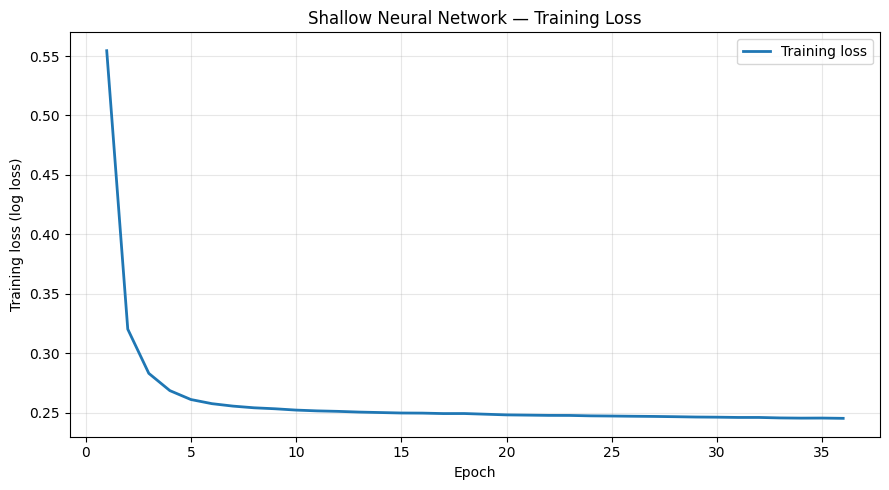

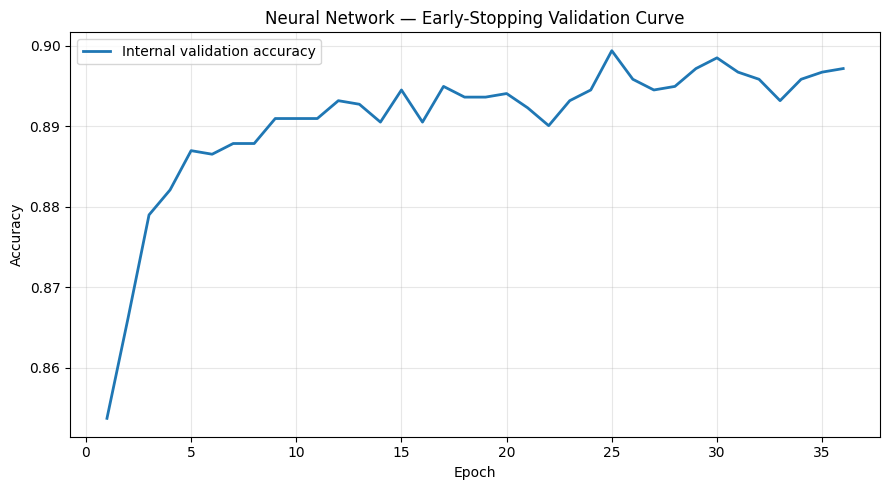

In [660]:
fitted_nn = attempts[best_nn_name][0]

mlp = fitted_nn.named_steps['model']

print("Selected architecture:", best_nn_name)
print("Maximum allowed epochs:", mlp.max_iter)
print("Actual epochs trained:", mlp.n_iter_)
print("Final training loss:", round(mlp.loss_, 5))
print("Early stopping enabled:", mlp.early_stopping)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(mlp.loss_curve_) + 1),
    mlp.loss_curve_,
    linewidth=2,
    label="Training loss"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss (log loss)")
plt.title("Shallow Neural Network — Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

if hasattr(mlp, 'validation_scores_') and mlp.validation_scores_ is not None:
    plt.figure(figsize=(9, 5))
    plt.plot(
        range(1, len(mlp.validation_scores_) + 1),
        mlp.validation_scores_,
        linewidth=2,
        label="Internal validation accuracy"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Neural Network — Early-Stopping Validation Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


### 8.4 Model comparison (chronological split)
All attempts in one table: train and validation scores show over- or under-fitting. The three final models (the baseline, the tuned gradient boosting and the better neural network) were chosen on validation; only they are scored on the **test seasons**, here, for the first and only time.

In [656]:
FINAL_MODELS = ['Logistic regression (baseline)', 'Gradient boosting (tuned)', best_nn_name]

test_rows = []
for name in FINAL_MODELS:
    fitted, threshold, _ = attempts[name]
    proba_test = fitted.predict_proba(X_test)[:, 1]
    test_rows.append({'model': name, 'part': 'test', 'threshold': threshold,
                      **scores(y_test, proba_test, threshold)})

comparison = pd.concat([result for _, _, result in attempts.values()] + [pd.DataFrame(test_rows)])
comparison_wide = comparison.pivot_table(index='model', columns='part',
                                         values=['PR-AUC','ROC-AUC','accuracy','precision', 'recall','F1'])
comparison_wide = comparison_wide.reindex(columns=PARTS, level=1)
display(comparison_wide.round(4))

print("Final models:", FINAL_MODELS)
print("Thresholds chosen on validation:",
      {name: round(attempts[name][1], 2) for name in FINAL_MODELS})

F1                     PR-AUC  \
part                                   train validation    test   train   
model                                                                     
Gradient boosting (default)           0.6412     0.7004     NaN  0.6776   
Gradient boosting (tuned)             0.4767     0.7042  0.5941  0.6629   
Logistic regression (baseline)        0.5787     0.7099  0.6805  0.5688   
Shallow NN (1 hidden layer: 32)       0.5838     0.6996  0.6316  0.5845   
Shallow NN (2 hidden layers: 64, 32)  0.5665     0.6984     NaN  0.5571   

                                                        ROC-AUC             \
part                                 validation    test   train validation   
model                                                                        
Gradient boosting (default)              0.7043     NaN  0.9355     0.9280   
Gradient boosting (tuned)                0.7193  0.7178  0.9296     0.9264   
Logistic regression (baseline)           0.7342  0.7243  0.9003     0.9297   
Shallow NN (1 hidden layer: 32)          0.7189  0.6801  0.9046     0.9235   
Shallow NN (2 hidden layers: 64, 32)     0.6813     NaN  0.8970     0.9136   

                                             accuracy                     \
part                                    test    train validation    test   
model                                                                      
Gradient boosting (default)              NaN   0.8980     0.9089     NaN   
Gradient boosting (tuned)             0.9395   0.8964     0.9191  0.8981   
Logistic regression (baseline)        0.9382   0.8507     0.9024  0.8744   
Shallow NN (1 hidden layer: 32)       0.9275   0.8785     0.9063  0.8863   
Shallow NN (2 hidden layers: 64, 32)     NaN   0.8429     0.9024     NaN   

                                     precision                     recall  \
part                                     train validation    test   train   
model                                                                       
Gradient boosting (default)             0.6067     0.6917     NaN  0.6798   
Gradient boosting (tuned)               0.7384     0.7812  0.7426  0.3520   
Logistic regression (baseline)          0.4654     0.6414  0.5518  0.7648   
Shallow NN (1 hidden layer: 32)         0.5397     0.6746  0.6168  0.6358   
Shallow NN (2 hidden layers: 64, 32)    0.4495     0.6519     NaN  0.7658   

                                                         
part                                 validation    test  
model                                                    
Gradient boosting (default)              0.7094     NaN  
Gradient boosting (tuned)                0.6410  0.4951  
Logistic regression (baseline)           0.7949  0.8873  
Shallow NN (1 hidden layer: 32)          0.7265  0.6471  
Shallow NN (2 hidden layers: 64, 32)     0.7521     NaN

Final models: ['Logistic regression (baseline)', 'Gradient boosting (tuned)', 'Shallow NN (1 hidden layer: 32)']
Thresholds chosen on validation: {'Logistic regression (baseline)': np.float64(0.22), 'Gradient boosting (tuned)': np.float64(0.56), 'Shallow NN (1 hidden layer: 32)': np.float64(0.35)}


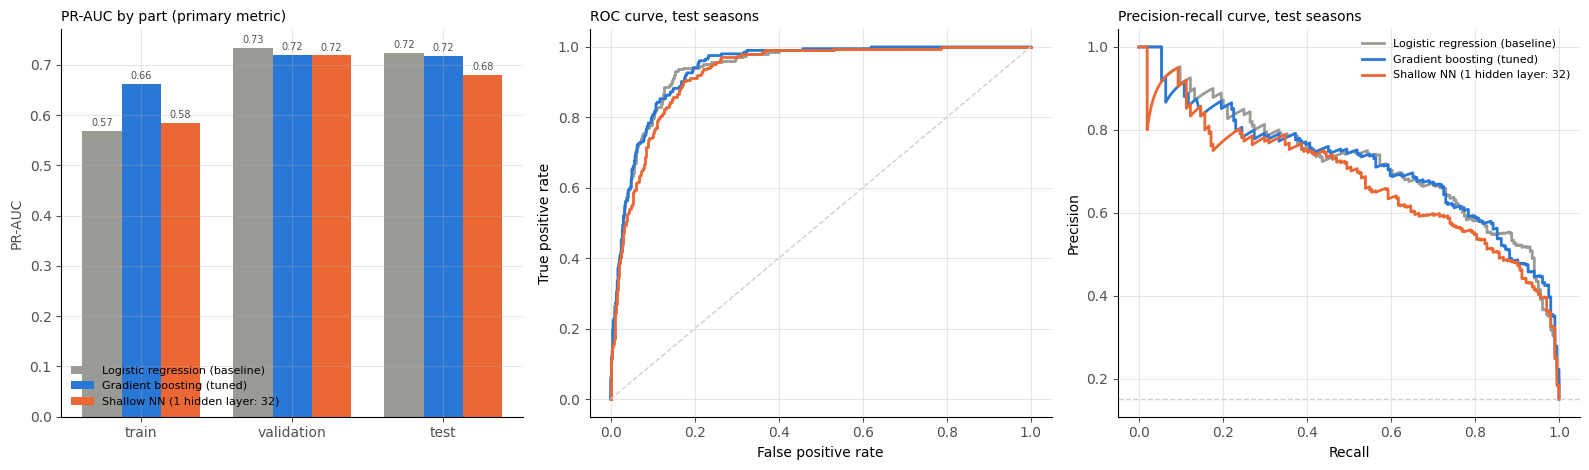

In [657]:
MODEL_COLORS = dict(zip(FINAL_MODELS, ['#9b9a95', '#2a78d6', '#eb6834']))
test_X, test_y = X_test, y_test

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

pr = comparison[comparison['model'].isin(FINAL_MODELS)].pivot(index='part', columns='model', values='PR-AUC').loc[PARTS]
x = np.arange(len(PARTS))
width = 0.26
for k, name in enumerate(FINAL_MODELS):
    bars = axes[0].bar(x + (k - 1) * width, pr[name], width=width, color=MODEL_COLORS[name], label=name)
    axes[0].bar_label(bars, fmt='%.2f', padding=2, fontsize=7, color=TEXT_COLOR)
axes[0].set_xticks(x, PARTS)
axes[0].set_ylabel('PR-AUC', color=TEXT_COLOR)
axes[0].set_title('PR-AUC by part (primary metric)', loc='left', fontsize=10)
axes[0].legend(frameon=False, fontsize=8)

# ROC and precision-recall curves on the test seasons
for name in FINAL_MODELS:
    proba = attempts[name][0].predict_proba(test_X)[:, 1]
    fpr, tpr, _ = roc_curve(test_y, proba)
    precision, recall, _ = precision_recall_curve(test_y, proba)
    axes[1].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=name)
    axes[2].plot(recall, precision, color=MODEL_COLORS[name], lw=2, label=name)
axes[1].plot([0, 1], [0, 1], color='#d0cfca', lw=1, ls='--')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate')
axes[1].set_title('ROC curve, test seasons', loc='left', fontsize=10)
axes[2].axhline(test_y.mean(), color='#d0cfca', lw=1, ls='--')
axes[2].set(xlabel='Recall', ylabel='Precision')
axes[2].set_title('Precision-recall curve, test seasons', loc='left', fontsize=10)

for ax in axes:
    ax.tick_params(colors=TEXT_COLOR)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### 8.5 Robustness check: the same models on the by-era split
Each final model is refitted with the same settings on the era split's training seasons, its threshold is chosen on that split's validation seasons and it is scored on its test seasons (every era, 6.1). Similar scores to 8.4 mean the models are not only good at recent seasons.

In [658]:
model_specs = {
    'Logistic regression (baseline)': baseline,
    'Gradient boosting (tuned)': gb_tuned,
    best_nn_name: nn_attempts[best_nn_name],
}

era_results = pd.concat([evaluate(model, name, split_col='era_split', score_test=True)[2]
                         for name, model in model_specs.items()])
era_wide = era_results.pivot_table(index='model', columns='part', values=['PR-AUC', 'ROC-AUC', 'F1'])
era_wide = era_wide.reindex(columns=PARTS, level=1)
display(era_wide.round(4))

print("Test PR-AUC, chronological vs. era split:")
display(pd.DataFrame({
    'chronological test': comparison[(comparison['part'] == 'test')].set_index('model').loc[FINAL_MODELS, 'PR-AUC'],
    'era-split test': era_results[era_results['part'] == 'test'].set_index('model').loc[FINAL_MODELS, 'PR-AUC'],
}).round(4))

F1                     PR-AUC             \
part                              train validation    test   train validation   
model                                                                           
Gradient boosting (tuned)        0.6412     0.6229  0.5858  0.6888      0.607   
Logistic regression (baseline)   0.5878     0.6366  0.5985  0.5795      0.599   
Shallow NN (1 hidden layer: 32)  0.5810     0.6216  0.5827  0.5838      0.591   

                                        ROC-AUC                     
part                               test   train validation    test  
model                                                               
Gradient boosting (tuned)        0.6172  0.9335     0.9170  0.9089  
Logistic regression (baseline)   0.6081  0.9001     0.9167  0.9082  
Shallow NN (1 hidden layer: 32)  0.5992  0.9015     0.9125  0.9081

Test PR-AUC, chronological vs. era split:


,chronological test,era-split test
model,,
Logistic regression (baseline),0.7243,0.6081
Gradient boosting (tuned),0.7178,0.6172
Shallow NN (1 hidden layer: 32),0.6801,0.5992


### 8.6 Confusion Matrices and Classification Reports


Model: Logistic regression (baseline)
Threshold: 0.220
              precision    recall  f1-score   support

  Not Podium       0.98      0.87      0.92      1150
      Podium       0.55      0.89      0.68       204

    accuracy                           0.87      1354
   macro avg       0.76      0.88      0.80      1354
weighted avg       0.91      0.87      0.89      1354


Model: Gradient boosting (tuned)
Threshold: 0.560
              precision    recall  f1-score   support

  Not Podium       0.92      0.97      0.94      1150
      Podium       0.74      0.50      0.59       204

    accuracy                           0.90      1354
   macro avg       0.83      0.73      0.77      1354
weighted avg       0.89      0.90      0.89      1354


Model: Shallow NN (1 hidden layer: 32)
Threshold: 0.350
              precision    recall  f1-score   support

  Not Podium       0.94      0.93      0.93      1150
      Podium       0.62      0.65      0.63       204

    accuracy      

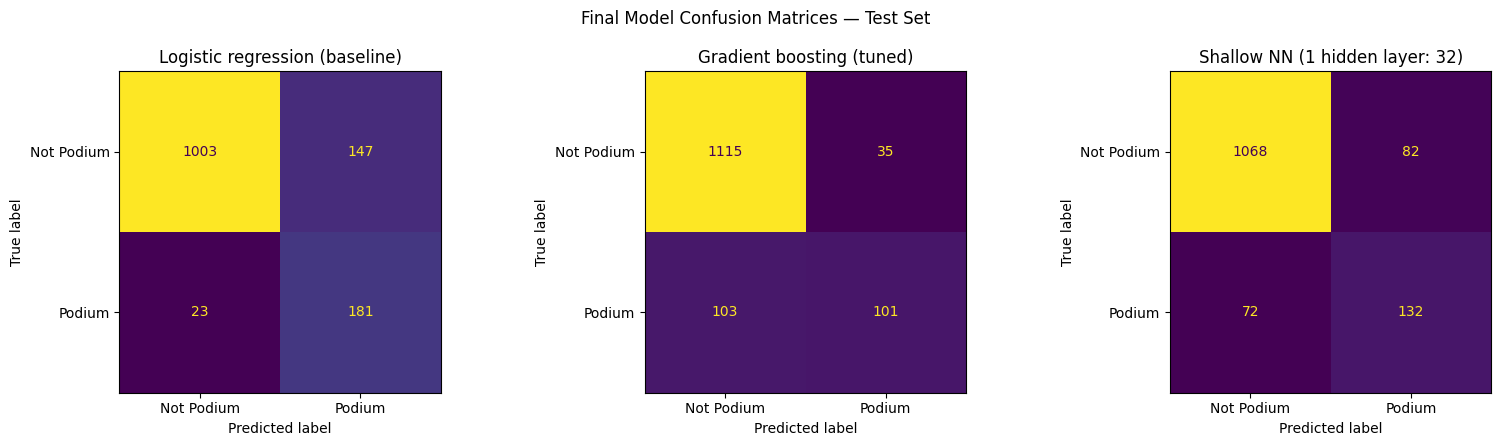

In [659]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, name in zip(axes, FINAL_MODELS):

    fitted, threshold, _ = attempts[name]

    probabilities = fitted.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=['Not Podium', 'Podium'],
        ax=ax,
        colorbar=False,
        values_format='d'
    )

    ax.set_title(name)

    print(f"\n{'=' * 50}")
    print(f"Model: {name}")
    print(f"Threshold: {threshold:.3f}")

    print(classification_report(
        y_test,
        predictions,
        target_names=['Not Podium', 'Podium'],
        zero_division=0
    ))

plt.suptitle('Final Model Confusion Matrices — Test Set')
plt.tight_layout()
plt.show()


## 9. Feature-Group Ablation
Each feature group (6.7) is removed in turn and the three final models are retrained without it, on the same training seasons and with the threshold chosen on validation. The drop in validation PR-AUC compared with the full feature set measures how much each group actually contributes after training, complementing the evidence gathered before training (6.8). Validation is used so that the test seasons stay reserved for the final evaluation (8.4).

In [ ]:
ablation_models = {
    'Logistic regression (baseline)': baseline,
    'Gradient boosting (tuned)': gb_tuned,
    best_nn_name: nn_attempts[best_nn_name],
}


def validation_scores(model, features):
    fitted = clone(model).fit(X_train[features], y_train)
    proba = fitted.predict_proba(X_val[features])[:, 1]
    return scores(y_val, proba, best_threshold(y_val, proba))


ablation_rows = []
for model_name, model in ablation_models.items():
    ablation_rows.append({'model': model_name, 'removed group': 'none (all features)',
                          'features used': len(FEATURES), **validation_scores(model, FEATURES)})
    for group, columns in FEATURE_GROUPS.items():
        kept = [f for f in FEATURES if f not in columns]
        ablation_rows.append({'model': model_name, 'removed group': group,
                              'features used': len(kept), **validation_scores(model, kept)})

ablation = pd.DataFrame(ablation_rows)
full_scores = ablation[ablation['removed group'] == 'none (all features)'].set_index('model')['PR-AUC']
ablation['PR-AUC drop'] = ablation['model'].map(full_scores) - ablation['PR-AUC']

display(ablation.pivot(index='removed group', columns='model', values='PR-AUC').round(4))
print("Drop in validation PR-AUC when the group is removed (positive = the group helps):")
display(ablation[ablation['removed group'] != 'none (all features)']
        .pivot(index='removed group', columns='model', values='PR-AUC drop')
        .sort_values('Gradient boosting (tuned)', ascending=False).round(4))

In [ ]:
drops = (ablation[ablation['removed group'] != 'none (all features)']
         .pivot(index='removed group', columns='model', values='PR-AUC drop'))
drops = drops.loc[drops.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(drops))
height = 0.26
for k, name in enumerate(ablation_models):
    ax.barh(y + (k - 1) * height, drops[name], height=height, color=MODEL_COLORS[name], label=name)
ax.axvline(0, color='#52514e', lw=1)
ax.set_yticks(y, drops.index)
ax.set_xlabel('Drop in validation PR-AUC when the group is removed', color=TEXT_COLOR)
ax.set_title('Feature-group ablation: how much each group contributes', loc='left', fontsize=12)
ax.tick_params(colors=TEXT_COLOR)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**How to read the ablation.** A large positive drop means the model relies on that group and nothing else replaces it. A drop near zero means the group adds little *given the other groups*, often because another group carries the same information (e.g. grid and qualifying position overlap strongly). A negative drop means the model did slightly better without the group on validation, which marks it as a candidate to remove. The written conclusion is added after the run.